# 28 · Applications créatives — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch28_creatif/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 28.Q1 à 28.Q10, 28.R1 à 28.R3, 28.1, 28.2, 28.4 | vérifier tes réponses courtes | 🧠 🔁 ✏️ | ★ à ★★ | |
| A | 28.11 | Un extracteur multi-couches par hooks sur un réseau pré-entraîné gelé | 📦 | ★★ | 25 |
|  | 28.12 | Prédire l'image qui excite un filtre précoce, puis un filtre profond | 🔮 | ★★ | 15 |
|  | 28.13 | Visualiser un filtre d'un réseau ImageNet : la montée de gradient du ch. 21 passe à l'échelle | 📦 | ★★ | 30 |
|  | 28.14 | Une galerie couche par couche (fig. 28.7) | 🎨 | ★★ | 25 |
|  | 28.15 | Régulariser la visualisation : décalages, flou, octaves | 🔬 | ★★★ | 40 |
| B | 28.16 | Deep dream sur une photo libre 🚀 | 📦 | ★★★ | 40 |
|  | 28.17 | Choisir couches et poids, ne rêver que dans une zone | 🔬 | ★★★ | 30 |
| C | 28.18 | La matrice de Gram en PyTorch, vérifiée contre NumPy | 📦 | ★ | 15 |
|  | 28.19 | Prédire une reconstruction depuis le bruit : contenu profond seul, style seul | 🔮 | ★ | 10 |
|  | 28.20 | Lire les courbes de losses d'un transfert de style | 📈 | ★★ | 15 |
|  | 28.21 | Le transfert de style qui ne produisait que du gris | 🐛 | ★★ | 25 |
|  | 28.22 | Reconstructions de contenu et de style couche par couche (fig. 28.19, 28.23, 28.24) 🚀 | 🎨 | ★★★ | 45 |
|  | 28.23 | Transfert de style complet sous budget CPU 🚀 | 📦 | ★★★ | 45 |
|  | 28.24 | Poids contenu/style, variation totale et image de départ 🚀 | 🔬 | ★★★ | 35 |
|  | 28.25 | Au-delà de Gram : moyennes et écarts-types des canaux | 🔬 | ★★★ | 40 |
|  | 28.26 | Crédits, licences et paramètres : documenter une galerie générée | 🛠️ | ★★★ | 30 |
| D | 28.27 | Plus de Verne : réutiliser le code du LSTM mot à mot de 24.30 sur Verne et l'entraîner plus longtemps, du charabia aux phrases 🚀 | 📦 | ★★★ | 45 |
|  | 28.28 | Glouton, température, top-k ou top-p : répétitions et diversité | 🔬 | ★★★ | 30 |
|  | 28.29 | Défi : un transfert de style en moins de 2 minutes de CPU, loss de style divisée par 10 et contenu reconnaissable | 🏆 | ★★★★ | 90 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Extraire les activations d'un réseau pré-entraîné gelé avec des hooks, et visualiser ce que cherchent ses filtres et ses couches par montée de gradient sur l'image.
- Faire rêver un réseau sur une photo libre (deep dream).
- Écrire la matrice de Gram et les losses de contenu, de style et de variation totale, puis un transfert de style complet sous budget CPU, et documenter une galerie (sources, licences, réglages).
- Générer du texte mot à mot sur Verne et comparer les stratégies de décodage.

**Rappel express.** Montée de gradient : $\mathbf{x} \leftarrow \mathbf{x} + \eta\, \nabla_{\mathbf{x}}\, a(\mathbf{x})$, poids gelés. Gram : $G = \frac{1}{CHW} F F^\top$. Transfert de style : $L = \alpha \lVert F(\mathbf{x}) - F(\mathbf{c}) \rVert^2 + \beta \sum_\ell w_\ell \lVert G^\ell(\mathbf{x}) - G^\ell(\mathbf{s}) \rVert_F^2 + \lambda L_{TV}$. Température : $p_i \propto e^{z_i / T}$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 28.1, 28.2 et 28.4)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"B"`) ; plusieurs lettres : entre guillemets (`"ABD"`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les dérivations ∂ 28.3 et 28.5, les estimations 🧮 28.6 et 28.7, la réflexion (🗣️ 28.8, ⚖️ 28.9, 📄 28.10) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import numpy as np

# VGG16: (convolutions, filters) of the five blocks; a 2x2 max-pooling of stride 2 ends each block
VGG16_BLOCKS = [(2, 64), (2, 128), (3, 256), (3, 512), (3, 512)]


def side(block, image=224):
    """Side of the activation maps of the convolutions of a block (1 to 5)."""
    return image // 2 ** (block - 1)


F_28_2 = np.array([[1, 0, 2, 1], [0, 3, 1, 1], [2, 0, 4, 2]], dtype=float)
RAW_28_2 = F_28_2 @ F_28_2.T
G_28_2 = RAW_28_2 / F_28_2.size

FX_28_4, FC_28_4 = np.array([1, 2, 0, 1.0]), np.array([1, 0, 1, 1.0])
SX_28_4, SS_28_4 = np.array([[1, 1], [0, 2.0]]), np.array([[2, 0], [0, 2.0]])
GX_28_4, GS_28_4 = SX_28_4 @ SX_28_4.T / SX_28_4.size, SS_28_4 @ SS_28_4.T / SS_28_4.size
IMG_28_4 = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 3.0]])
LC_28_4 = float(((FX_28_4 - FC_28_4) ** 2).sum())
LS_28_4 = float(((GX_28_4 - GS_28_4) ** 2).sum())
LTV_28_4 = float(((IMG_28_4[1:] - IMG_28_4[:-1]) ** 2).sum() + ((IMG_28_4[:, 1:] - IMG_28_4[:, :-1]) ** 2).sum())

**28.Q1 — Pourquoi partir d'un réseau pré-entraîné comme VGG16**

In [3]:
wb.record("28.Q1a", False, mistakes={"relis le §28.2.2 : que modifie-t-on à chaque pas, et que garde-t-on fixe ?": True})
wb.record("28.Q1b", 13 + 3, mistakes={"les 13 convolutions ne sont pas tout : ajoute les couches denses": 13,
          "le max-pooling n'a pas de poids : ne compte que les convolutions et les couches denses": 21})
wb.record("28.Q1c", "B", mistakes={"VGG16 est un gros réseau, lent pour sa précision : ce n'est pas la raison": "A", "ImageNet contient des photos d'objets et d'animaux, pas des tableaux": "C"})
wb.record("28.Q1d", "B", mistakes={"c'est le chiffre du livre, corrigé par la fiche (§28.2.1)": "A", "14 millions est la taille de la base ImageNet complète, pas du jeu d'entraînement d'ILSVRC": "C"})
wb.record("28.Q1e", 1000, mistakes={"ImageNet-1k : le nom donne le nombre de classes": 21000})

WB_ANSWER {"hash": "7034d074a093cec6238ef634513f0c5c01eb66259e1300cf70e3a7a16e69ea49", "id": "28.Q1a", "kind": "bool", "mistakes": {"9c1486e18c68c09a642d03639a905b1f511ec65e5d8d2e6b39f740b00c8b2a8d": "relis le §28.2.2 : que modifie-t-on à chaque pas, et que garde-t-on fixe ?"}}
📝 Ex 28.Q1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "1eb408fe4395f378d64a4e68372d1aa989ae767394b09aab23933477549814e8", "id": "28.Q1b", "kind": "int", "magnitude": 1, "mistakes": {"42c573ae6ca792fd7f449690ed66d96e4719554ca4cc5ee011e11fdd03283871": "le max-pooling n'a pas de poids : ne compte que les convolutions et les couches denses", "8512dc3f15606c96de7b66fa8ea21dec1189383ba555d9b94dac0f557065d927": "les 13 convolutions ne sont pas tout : ajoute les couches denses"}, "sign": 1}
📝 Ex 28.Q1b : réponse enregistrée (int).
WB_ANSWER {"hash": "d2a7546a2e7c829f8ce579d7d3d0abb4ec27bed97d0ba1ff92f9555f706934c7", "id": "28.Q1c", "kind": "str", "mistakes": {"19d835c9aec190e40a83013988e6c461205a6d967c24299e24a1e

**28.Q2 — Montée de gradient sur l'entrée, poids gelés**

In [4]:
wb.record("28.Q2a", "B", mistakes={"les poids du réseau restent fixes pendant toute la visualisation": "A", "le learning rate est un réglage, pas ce qu'on optimise": "C"})
wb.record("28.Q2b", True, mistakes={"monter sur a, c'est descendre sur −a : le gradient change de signe, le pas aussi": False})
wb.record("28.Q2c", "A", mistakes={"c'est le deep dream qui part d'une photo, pas la visualisation d'un filtre": "B", "relis le §28.2.2 : des valeurs tirées au hasard entre −1 et 1": "C"})
wb.record("28.Q2d", "B", mistakes={"l'optimiseur ne reçoit que ce qu'on veut modifier : l'image": "A"})
wb.record("28.Q2e", True, mistakes={"geler les poids coupe leur gradient, pas celui de l'image, qui a requires_grad=True": False})

WB_ANSWER {"hash": "9197b1913558fb5e1c2b28db5c643c96809944c32b36a163a6a2d4098e36f51e", "id": "28.Q2a", "kind": "str", "mistakes": {"bbf55a165a1f0721e555f3b25c1264d69c1e6c90791c00be1f5bf0a531974bd6": "le learning rate est un réglage, pas ce qu'on optimise", "d8dd2e7d7f96dcb9d0aab8fd750f49b268878fc4e37d8f15d03bd55753d73556": "les poids du réseau restent fixes pendant toute la visualisation"}}
📝 Ex 28.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "2fe3bf971f93e92728564bb08f6f2f46a2eff17e7a3c10ea0ba0a54c1ce2c982", "id": "28.Q2b", "kind": "bool", "mistakes": {"9b5a4c4a5251c0fc7b93cdc81ff02443ff5cbb42a3bf38e5868afa3d3d552fdc": "monter sur a, c'est descendre sur −a : le gradient change de signe, le pas aussi"}}
📝 Ex 28.Q2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "7c321cc355c7fb3fdb3af448b394fd38e96fec750d550a458ad9d2cb88f5d500", "id": "28.Q2c", "kind": "str", "mistakes": {"4152ef56eae0ab47f591196d221a58fea00ff1df949b63d6b8a3555b03b9250c": "relis le §28.2.2 : des valeurs tirées 

**28.Q3 — Visualiser une couche entière, pondérer ses filtres**

In [5]:
wb.record("28.Q3a", "B", mistakes={"un seul filtre, c'est la visualisation d'un filtre (§28.2.2)": "A", "les couches denses ne servent pas ici : on regarde les convolutions": "C"})
wb.record("28.Q3b", "A", mistakes={"les parties d'objets apparaissent dans les couches profondes, pas au bloc 1": "B"})
wb.record("28.Q3c", True, mistakes={"avec un poids négatif, augmenter la somme pondérée, c'est diminuer l'activation de ce filtre": False})
wb.record("28.Q3d", 512, mistakes={"les filtres doublent de bloc en bloc jusqu'au bloc 4, puis restent à 512": 256})
wb.record("28.Q3e", side(4), mistakes={"le bloc 4 vient après trois poolings, pas quatre": 14,
          "le bloc 4 vient après trois poolings, et chacun divise le côté par 2": 56})

WB_ANSWER {"hash": "9e8248f218f742377441f14c013a47a7fa10d2db64a6c167143a27ea8365d6db", "id": "28.Q3a", "kind": "str", "mistakes": {"5003f49390d8f82c81683ff770596e09c5658795052d9fe0d3f9280c59b77cc9": "un seul filtre, c'est la visualisation d'un filtre (§28.2.2)", "7b9fcfa6b5a2679506ddd5f0fa60053ce29e1c2c0f56be999e2494ff9fd4d401": "les couches denses ne servent pas ici : on regarde les convolutions"}}
📝 Ex 28.Q3a : réponse enregistrée (str).
WB_ANSWER {"hash": "ecb470e9f953c5f6709d1de59bb3fc25b7e7bf148c03d819574557c59ed68fb0", "id": "28.Q3b", "kind": "str", "mistakes": {"870734d2711506ef3fd67f311db2ec840c5c5bf66de0d455c0f1d717e0f154ab": "les parties d'objets apparaissent dans les couches profondes, pas au bloc 1"}}
📝 Ex 28.Q3b : réponse enregistrée (str).
WB_ANSWER {"hash": "c17ed6679dc06146ae2ef2b6996b130820495db29f210e37dfeae812f974b687", "id": "28.Q3c", "kind": "bool", "mistakes": {"a33a5da556043a092de3b29b846df442da6154b0046e17c0713d052c9756f392": "avec un poids négatif, augmenter la

**28.Q4 — Deep dream : ce qui change par rapport à la visualisation d'une couche**

In [6]:
wb.record("28.Q4a", "AB", mistakes={"les poids du réseau ne changent jamais dans ce chapitre": "ABC",
          "le deep dream fait monter les activations, comme la visualisation": "ABD",
          "il manque le changement d'image de départ": "B",
          "il manque la combinaison de plusieurs couches": "A"})
wb.record("28.Q4b", True, mistakes={"la montée de gradient renforce ce qui excite déjà les filtres choisis": False})
wb.record("28.Q4c", "A", mistakes={"relis le §28.3 : le nom du billet vient du réseau de Google qu'il utilisait": "B", "relis le §28.3 : le billet porte le nom d'un réseau de Google, pas d'une technique de peinture": "C"})
wb.record("28.Q4d", "C", mistakes={"couper le réseau change les couches, pas la zone de l'image": "A", "un pas plus petit ralentit le rêve partout, pas seulement dans une zone": "B"})
wb.record("28.Q4e", False, mistakes={"le transfert de style cherche à ressembler à des cibles : il fait baisser des écarts": True})

WB_ANSWER {"hash": "05c5233c246d40fc6bf3f5661042da4adcccf1677bfeb3cb6a6398029b751626", "id": "28.Q4a", "kind": "str", "mistakes": {"1a3e9034d54b7808a439628b39205ff83d0104edd966ebc16d29f894b83698ce": "le deep dream fait monter les activations, comme la visualisation", "24fb8bc5667d52efe73e8f2981646f3a3207e04c28b8cd855ee2921d3b087f51": "il manque la combinaison de plusieurs couches", "54b4347932a534e9c19e197b694b8861b934a26e8587273eaf3998874f61a232": "les poids du réseau ne changent jamais dans ce chapitre", "d258cc819d18fc47694f0376c6ec3f54eb2d73a7e99269a60fdeb1d1bc98f04f": "il manque le changement d'image de départ"}}
📝 Ex 28.Q4a : réponse enregistrée (str).
WB_ANSWER {"hash": "8396f170a8cf40b2d13bbd1820febd2e7b69641dddb951e6d720aa6777bafa66", "id": "28.Q4b", "kind": "bool", "mistakes": {"5b71b6fb0387fe450e1469b1e20b36e75fa9e9c58fce6681224b05675219a278": "la montée de gradient renforce ce qui excite déjà les filtres choisis"}}
📝 Ex 28.Q4b : réponse enregistrée (bool).
WB_ANSWER {"hash"

**28.Q5 — Des yeux partout : l'écho des données d'entraînement**

In [7]:
wb.record("28.Q5a", "C", mistakes={"aucune couche n'est spécialisée à l'avance : les détecteurs sont appris": "A", "le deep dream part d'une photo, pas d'un bruit": "B"})
wb.record("28.Q5b", False, mistakes={"plus d'une centaine des 1 000 classes sont des races de chiens": True})
wb.record("28.Q5c", "B", mistakes={"un réseau ne rêve que de ce qu'il a appris": "A"})
wb.record("28.Q5d", "B", mistakes={"les traits et les textures, ce sont les couches précoces": "A"})
wb.record("28.Q5e", True, mistakes={"ce que le réseau fait apparaître dépend de ses données d'entraînement": False})

WB_ANSWER {"hash": "2dce2bbe1695c606fb86f924a04f65d12c3337e580499e86703c2869b389911e", "id": "28.Q5a", "kind": "str", "mistakes": {"14ba0bb311222045d2118041fc64fa946ddb30ae5c306a8a5c8bbab6006b5e03": "le deep dream part d'une photo, pas d'un bruit", "da69356fc7c53f27337fd48f0d2c03c78e9c6f34cbfd5947b43609c53e328818": "aucune couche n'est spécialisée à l'avance : les détecteurs sont appris"}}
📝 Ex 28.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "03b1b8e310706fb5901b7340f1fc4a6acc2cc4752ee7b2c5a7462f0b899b5fa1", "id": "28.Q5b", "kind": "bool", "mistakes": {"8c9eee895f62901ce013679ea8e96215c008aa420e730af3ef4363ccf3eb406a": "plus d'une centaine des 1 000 classes sont des races de chiens"}}
📝 Ex 28.Q5b : réponse enregistrée (bool).
WB_ANSWER {"hash": "8bc514568452c8e030ed7b00661e739a17554f5e39f1eca82bc1e18033f1c8f0", "id": "28.Q5c", "kind": "str", "mistakes": {"5eb672ce9d20cf9bdb1e38ddda5653db34cb490d5659f2eef69bfd99ee6ed040": "un réseau ne rêve que de ce qu'il a appris"}}
📝 Ex 28.Q5c

**28.Q6 — Image de base, référence de style, image générée : que minimise-t-on ?**

In [8]:
wb.record("28.Q6a", "C", mistakes={"la photo de contenu est une cible, elle ne change pas": "A", "le tableau est une cible, il ne change pas": "B", "le réseau est gelé pendant tout le transfert": "D"})
wb.record("28.Q6b", "A", mistakes={"le style se compare par les matrices de Gram, le contenu par les activations": "B"})
wb.record("28.Q6c", "B", mistakes={"la photo fournit le contenu, pas le style": "A"})
wb.record("28.Q6d", False, mistakes={"le réseau sert d'instrument de mesure : ses poids ne bougent pas": True})
wb.record("28.Q6e", 1, mistakes={"les cibles sont déjà calculées : seule l'image générée change d'un pas à l'autre": 3,
          "les cibles sont calculées une fois : seule l'image générée repasse": 2})

WB_ANSWER {"hash": "0716e5a88e4281da40af8bf913e818781f14ea421bcb0e1a2b8ce16b0078fd75", "id": "28.Q6a", "kind": "str", "mistakes": {"43145bf9f043e144090257f739c979d8466a6d43f34626d385f1c73296f7787e": "le réseau est gelé pendant tout le transfert", "70c164926bc30668c33aac03c2ca518b4625851355cb637ee08ff9d1fa562b7f": "la photo de contenu est une cible, elle ne change pas", "b6bed5a8d206df8e7895ded5ab6201a66af6d19f9508871d4354f0abe52cc206": "le tableau est une cible, il ne change pas"}}
📝 Ex 28.Q6a : réponse enregistrée (str).
WB_ANSWER {"hash": "92ade09d938939bdb16d889c3daa17fd8956a91f51e3ea1bda4fe5404c2d9c89", "id": "28.Q6b", "kind": "str", "mistakes": {"303048c966739256c59e5d216d8a13f6a71e979f64eb84c6d0ea50c2c9d03f22": "le style se compare par les matrices de Gram, le contenu par les activations"}}
📝 Ex 28.Q6b : réponse enregistrée (str).
WB_ANSWER {"hash": "bacb5aceaf271308126bb96d71c8acd67698b1a584cdd663a3db992fb862c613", "id": "28.Q6c", "kind": "str", "mistakes": {"18f11597dcf96541df8

**28.Q7 — Ce que la matrice de Gram retient et ce qu'elle oublie**

In [9]:
wb.record("28.Q7a", "A", mistakes={"on compare des filtres deux à deux, pas des positions": "B", "c'est la forme de F, la matrice des cartes mises à plat": "C"})
wb.record("28.Q7b", "B", mistakes={"les indices de G sont des filtres, pas des pixels": "A", "la somme porte sur toutes les positions : la position est oubliée": "C"})
wb.record("28.Q7c", True, mistakes={"chaque coefficient est une somme sur les positions : l'ordre des termes ne compte pas": False})
wb.record("28.Q7d", "B", mistakes={"G_ii additionne des carrés d'activations, pas des présences": "A", "G_ii additionne sur toutes les positions, pas seulement la plus forte": "C"})
wb.record("28.Q7e", False, mistakes={"relis l'encadré ⚠️ « personne ne sait vraiment » du §28.4.6 : Li et coll. nomment cette mesure": True})

WB_ANSWER {"hash": "f2d66f28cb12fdae7ef1b91d5935e884066bf25bedf35a4e182e87a90269aa95", "id": "28.Q7a", "kind": "str", "mistakes": {"5e746db08de8ebedb6d5d676251443154b35977699d3581e00ea8fa7edb0c741": "c'est la forme de F, la matrice des cartes mises à plat", "e74a2e35bb986b63234588b93f453d8596828fce78f905668524a0295f98b4ec": "on compare des filtres deux à deux, pas des positions"}}
📝 Ex 28.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "68bc15e0a787ab26f914fee31bf8f69f2ac3e5bfad90907c2843c83c670fd1cd", "id": "28.Q7b", "kind": "str", "mistakes": {"2e582cee91d3e86667f2fbd95fe0adb9e0fccde486b9fc0a66187eb549ef9c9d": "la somme porte sur toutes les positions : la position est oubliée", "7ab74c22a5c6b9bba3deb238068e05b9c26e62a575960d0da846ac2bb1c349e3": "les indices de G sont des filtres, pas des pixels"}}
📝 Ex 28.Q7b : réponse enregistrée (str).
WB_ANSWER {"hash": "7c55b50f9161e7409fd9aae8b283e10c0a91f9509ca41e407f738a0b362e35d6", "id": "28.Q7c", "kind": "bool", "mistakes": {"2e340cb3f39

**28.Q8 — Loss de contenu : couches précoces ou profondes ?**

In [10]:
wb.record("28.Q8a", "A", mistakes={"les couches précoces gardent les détails : la reconstruction est presque exacte": "B"})
wb.record("28.Q8b", "B", mistakes={"plus on va profond, plus la reconstruction s'éloigne des pixels": "A"})
wb.record("28.Q8c", "C", mistakes={"c'est le choix du code de Chollet, pas celui du livre": "A", "toutes les couches, c'est le choix du livre pour le style": "B"})
wb.record("28.Q8d", False, mistakes={"Gatys et coll. prennent conv4_2, une couche profonde (fiche §28.4.3)": True})
wb.record("28.Q8e", "B", mistakes={"le nombre de paramètres n'a rien à voir avec ce que la loss impose": "A", "le temps de calcul n'a rien à voir avec ce que la loss impose": "C"})

WB_ANSWER {"hash": "ecf308271af2f327f9c17f74b2cee9732650f286d6553c8712b69e92f791421c", "id": "28.Q8a", "kind": "str", "mistakes": {"349645cc4e375617e638608c19f8f2d285e5cc999b335fef3abd7121bb422232": "les couches précoces gardent les détails : la reconstruction est presque exacte"}}
📝 Ex 28.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "803d1c3e0fd3878b2dee9e9b1645ea00e7ba1f0cf224b0a030b62e097d222749", "id": "28.Q8b", "kind": "str", "mistakes": {"0b678656a542a2d98995f0d2f3ffce79955b38449d4fe91f4a21d42b7a79d994": "plus on va profond, plus la reconstruction s'éloigne des pixels"}}
📝 Ex 28.Q8b : réponse enregistrée (str).
WB_ANSWER {"hash": "9f960359bb7c9d875216d6f559456592ab04643618372789e4bc4026aa2e05c7", "id": "28.Q8c", "kind": "str", "mistakes": {"394ba23579e6364406aaf7767c97ccae960beb309521456cd695f3e0f72d33d0": "toutes les couches, c'est le choix du livre pour le style", "a0a3b5657c2f4192762c86be2d975ceec982672caad2f3f99d2fc399e59e987b": "c'est le choix du code de Chollet, pas 

**28.Q9 — Loss de style, poids relatifs et variation totale**

In [11]:
wb.record("28.Q9a", "B", mistakes={"relis le §28.4.5 : le livre prend le style sur toutes les convolutions": "A"})
wb.record("28.Q9b", round(1 / 0.025), mistakes={"refais la division : 1 divisé par 0,025": 25})
wb.record("28.Q9c", "C", mistakes={"la variation totale compare chaque pixel à ses voisins, pas à une plage de couleurs": "A", "l'écart à la photo, c'est la loss de contenu": "B"})
wb.record("28.Q9d", True, mistakes={"multiplie la loss de style par 1 000 en changeant de normalisation : le même β donne-t-il le même dosage ?": False})
wb.record("28.Q9e", False, mistakes={"partir de la photo, c'est partir d'une image dont le contenu est déjà juste : c'est elle qui converge vite": True})

WB_ANSWER {"hash": "37e608d47ad2c1d21fa8cc2953e8d56966b16253dd4c6ca77df9e9c1d6b46da2", "id": "28.Q9a", "kind": "str", "mistakes": {"8bb06dcbddc6f80f9f4406792848a72de398f7a394ffc7e691b1db76517f6336": "relis le §28.4.5 : le livre prend le style sur toutes les convolutions"}}
📝 Ex 28.Q9a : réponse enregistrée (str).
WB_ANSWER {"hash": "fa351441fcea156e57c357e392ffb6f9fec4f15f05fe3edcb20153804670e288", "id": "28.Q9b", "kind": "int", "magnitude": 1, "mistakes": {"54c11942fcec319dcdd21c7adb86b50d50d7c30f2efcb107bf2ba48f3b5e795f": "refais la division : 1 divisé par 0,025"}, "sign": 1}
📝 Ex 28.Q9b : réponse enregistrée (int).
WB_ANSWER {"hash": "0cd2a93f9eccba478e85a2df719a840e943b7bf6c1ac6be9570c0b8680a4095c", "id": "28.Q9c", "kind": "str", "mistakes": {"5648b41a7f6b6a2a54d094aae3abcd47183e73ba90698444cb15702cd5344817": "la variation totale compare chaque pixel à ses voisins, pas à une plage de couleurs", "8f768471b330c4e16ac02064977ebf8853c257624266c019386fa686775c0bf5": "l'écart à la photo,

**28.Q10 — Générer du texte mot à mot : ce qu'implique « le mot le plus probable »**

In [12]:
wb.record("28.Q10a", "A", mistakes={"relis le §28.5 : « le mot suivant le plus probable »": "B"})
wb.record("28.Q10b", False, mistakes={"le glouton ne tire rien au hasard : même entrée, même sortie": True})
wb.record("28.Q10c", "B", mistakes={"un modèle mot à mot choisit dans son vocabulaire : il ne peut pas inventer de mot": "A"})
wb.record("28.Q10d", False, mistakes={"la couche de sortie a un neurone par mot du vocabulaire : rien d'autre ne peut sortir": True})
wb.record("28.Q10e", "A", mistakes={"diviser par T < 1, c'est multiplier les écarts entre logits": "B"})

WB_ANSWER {"hash": "0ac416a7410ca42f63a48bb0f4eff319674184d02058b06912b0b0ad19d35941", "id": "28.Q10a", "kind": "str", "mistakes": {"be6bf61f4dbe88916c53c98665de69e43fa15035c01bf698b1bd3e2c9ab01154": "relis le §28.5 : « le mot suivant le plus probable »"}}
📝 Ex 28.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "64166dbb3ec22cea47544b2d78493e0dc6f545427b88640a3d494a82281bf72a", "id": "28.Q10b", "kind": "bool", "mistakes": {"68a651408b7e09fe566099f57e33e3788123d21e180ab6445dce7b74b036084d": "le glouton ne tire rien au hasard : même entrée, même sortie"}}
📝 Ex 28.Q10b : réponse enregistrée (bool).
WB_ANSWER {"hash": "c8bca6ac6abb57e031b5487c4b07f3bfcc5ffc35d0357993739adf61c5c2f8c1", "id": "28.Q10c", "kind": "str", "mistakes": {"7a68b25d6771d12ff709a1928b1b09fd1619662c4f4ac8ddc9e3c9881a1f9941": "un modèle mot à mot choisit dans son vocabulaire : il ne peut pas inventer de mot"}}
📝 Ex 28.Q10c : réponse enregistrée (str).
WB_ANSWER {"hash": "06ea8c35afb695d0805b0156a9f9e99836d7af6de5e4

**28.R1 — Un réseau qui sert de loss (le discriminateur)**

In [13]:
wb.record("28.R1a", "A", mistakes={"le générateur ne voit jamais de vraie image (ch. 27)": "B"})
wb.record("28.R1b", "B", mistakes={"VGG16 est gelé : il n'apprend rien pendant le transfert": "A"})
wb.record("28.R1c", True, mistakes={"dans les deux cas, le gradient de la loss traverse un réseau avant d'arriver à ce qu'on modifie": False})
wb.record("28.R1d", "B", mistakes={"chez Gatys, il n'y a pas de générateur : on modifie l'image elle-même": "A"})
wb.record("28.R1e", "B", mistakes={"une loss adversariale vient d'un discriminateur entraîné en même temps": "A"})

WB_ANSWER {"hash": "8b7942c8afd22f32753de39131dfa8598fde545cdc2ae777e909038be6969ea0", "id": "28.R1a", "kind": "str", "mistakes": {"7b60b0d819611c4e8a471b58d2a29a7ef8a76dbbe2a3fd39ea0eead82f48ce70": "le générateur ne voit jamais de vraie image (ch. 27)"}}
📝 Ex 28.R1a : réponse enregistrée (str).
WB_ANSWER {"hash": "8b16352111938ee1779ddc834e721ac0088ef2aa1d7b18bce0262a91a7f9dd3f", "id": "28.R1b", "kind": "str", "mistakes": {"5d4ab55898d284ef9fddbecbafc53b4c320db49244534f45698398b53adafaa2": "VGG16 est gelé : il n'apprend rien pendant le transfert"}}
📝 Ex 28.R1b : réponse enregistrée (str).
WB_ANSWER {"hash": "7db5aa9148a6bdd8f9508d6c614c3d120e8f1ba9eb31afbe9ec03a9939ef5327", "id": "28.R1c", "kind": "bool", "mistakes": {"84e56fa905c8629d1f00063189b60b776918f4153a52e381d0db7b516cc1fc68": "dans les deux cas, le gradient de la loss traverse un réseau avant d'arriver à ce qu'on modifie"}}
📝 Ex 28.R1c : réponse enregistrée (bool).
WB_ANSWER {"hash": "a5fe25838e991bf56c0f2c4ea823f2bf6adb819b6

**28.R2 — Mélange de contenu contre mélange de représentations**

In [14]:
wb.record("28.R2a", "B", mistakes={"une moyenne de pixels superpose les deux traits, chacun à moitié d'intensité": "A"})
wb.record("28.R2b", "A", mistakes={"le décodeur transforme un code en une image qui ressemble aux données": "B"})
wb.record("28.R2c", True, mistakes={"le transfert de style ne moyenne pas de pixels : il impose des activations et des matrices de Gram": False})
wb.record("28.R2d", round(0.75 * 0 + 0.25 * 4), mistakes={"t pondère z₂, et 1 − t pondère z₁": 3})
wb.record("28.R2e", False, mistakes={"la matrice de Gram est quadratique en F : développe (F₁ + F₂)(F₁ + F₂)ᵀ / 4": True})

WB_ANSWER {"hash": "990e7bf46daba7583732dfd3242662aaa43deaa38e7095030f730ce333055636", "id": "28.R2a", "kind": "str", "mistakes": {"badf33867f03f79e2ede5c8ffe46ef7d874891adadc415624d2506ad6d78c1f1": "une moyenne de pixels superpose les deux traits, chacun à moitié d'intensité"}}
📝 Ex 28.R2a : réponse enregistrée (str).
WB_ANSWER {"hash": "7dd537e9f94697b4cfc7acc872563b772a5ff5cfb90bcddaeb813d42029e740b", "id": "28.R2b", "kind": "str", "mistakes": {"3f5c5b2764564b5f788213364b37460aff6a4cce7a8d4b7a13b50410be9efdcf": "le décodeur transforme un code en une image qui ressemble aux données"}}
📝 Ex 28.R2b : réponse enregistrée (str).
WB_ANSWER {"hash": "8c495842011e003bdb1a943c060be4ed4e063a14663d6cab0a03b0e7d559b359", "id": "28.R2c", "kind": "bool", "mistakes": {"c9c0bac9fa84c15ca8afc57061facd91c104602af57ddde790376b776712ab83": "le transfert de style ne moyenne pas de pixels : il impose des activations et des matrices de Gram"}}
📝 Ex 28.R2c : réponse enregistrée (bool).
WB_ANSWER {"hash": "

**28.R3 — Champ récepteur et hiérarchie des filtres de VGG16**

In [15]:
wb.record("28.R3a", 3 + 2, mistakes={"chaque convolution 3 × 3 de plus ajoute 2 pixels au champ récepteur, pas 3": 6,
          "deux convolutions ne voient pas seulement 3 pixels : la seconde voit 3 sorties de la première": 3})
wb.record("28.R3b", 3 + 2 + 2, mistakes={"chaque convolution 3 × 3 de plus ajoute 2 pixels, pas 3": 9})
wb.record("28.R3c", True, mistakes={"relis le ch. 21 : chaque couche voit une plus grande région de l'image": False})
wb.record("28.R3d", 32 // 2 ** 5, mistakes={"il y a cinq poolings, pas quatre": 2,
          "seuls les poolings réduisent la taille, et il y en a cinq": 0})
wb.record("28.R3e", 64 * 64 * 9 + 64, mistakes={"n'oublie pas les 64 biais": 36864,
          "un filtre 3 × 3 voit tous les canaux d'entrée : 64 × 3 × 3 poids par filtre": 640})

WB_ANSWER {"hash": "4bb20f4033e2202a0ed1c3b49a9721ccd346b438a6e78a557ca3ca3e100f128b", "id": "28.R3a", "kind": "int", "magnitude": 0, "mistakes": {"2576edf6ad49fd4df3d4895bbbcd4c490f7276332af7eb42df20df7e71da2c2c": "deux convolutions ne voient pas seulement 3 pixels : la seconde voit 3 sorties de la première", "d263ec6f5ae3fbda8c16e445b6a1881e9561700bcac75cc6d685e293dd0a5ca5": "chaque convolution 3 × 3 de plus ajoute 2 pixels au champ récepteur, pas 3"}, "sign": 1}
📝 Ex 28.R3a : réponse enregistrée (int).
WB_ANSWER {"hash": "b579654d13b6db34fe083d52faa071cb89bffddd9eeebdd62c4e15ca275c04bc", "id": "28.R3b", "kind": "int", "magnitude": 0, "mistakes": {"d4c1ed3fff61b978ca3dc32473f97dc32157e70a752f3466007ecb782a044a8b": "chaque convolution 3 × 3 de plus ajoute 2 pixels, pas 3"}, "sign": 1}
📝 Ex 28.R3b : réponse enregistrée (int).
WB_ANSWER {"hash": "a72f84a13b23e9d951bde0a365da583a5142907112ce7a5d28a7199f13d2041e", "id": "28.R3c", "kind": "bool", "mistakes": {"e963914cc15a2f908ba9c13f6b53c

**Ex 28.1 — Tailles des activations et des matrices de Gram le long de VGG16**

In [16]:
wb.record("28.1a", 64 * side(1) ** 2, mistakes={"n'oublie pas les 64 canaux": 50176,
          "la convolution garde la taille : 224 × 224, pas 112 × 112": 64 * 112 ** 2})
wb.record("28.1b", 512 * side(4) ** 2, mistakes={"le bloc 4 vient après trois poolings : ses cartes font 28 × 28": 512 * 14 ** 2,
          "la première convolution du bloc 4 a déjà 512 filtres": 256 * 28 ** 2})
wb.record("28.1c", 512 ** 2, mistakes={"la matrice de Gram est C × C : elle ne dépend pas de la taille des cartes": 401408,
          "c'est la moitié de la matrice : compte tous ses coefficients": 512 * 513 // 2})
wb.record("28.1d", 64 * side(1) ** 2 // 64 ** 2, mistakes={"divise le nombre de valeurs de l'activation par 64 × 64, la taille de la matrice": 64 * 224 ** 2 // 64})
wb.record("28.1e", 512 * 513 // 2, mistakes={"la diagonale compte aussi : n(n + 1)/2, pas n(n − 1)/2": 512 * 511 // 2,
          "la matrice est symétrique : les coefficients de part et d'autre de la diagonale sont égaux": 512 ** 2})
wb.record("28.1f", side(5, image=128), mistakes={"le bloc 5 vient après quatre poolings, pas cinq": 4,
          "le bloc 5 vient après quatre poolings, et chacun divise le côté par 2": 16})
wb.record("28.1g", False, mistakes={"la matrice de Gram est C × C : seul le nombre de filtres compte": True})

WB_ANSWER {"hash": "0f40da9941a6b912c190bf5b035167bff8dd03bc8b6891f86bff698122ec2425", "id": "28.1a", "kind": "int", "magnitude": 6, "mistakes": {"867b55d0146ab3dce7804f400718d63c12e7cd0ca74817785f2fbe3e580f0f9e": "n'oublie pas les 64 canaux", "d52f53241186da389971bdae0f5f7a0ee6e64d395f04c365ecd5b17c4c74cb1e": "la convolution garde la taille : 224 × 224, pas 112 × 112"}, "sign": 1}
📝 Ex 28.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "054820a336609ff366432bbb2bf2446a14dbf5c5e4c4728d2097b64a4e5c2f7b", "id": "28.1b", "kind": "int", "magnitude": 5, "mistakes": {"426549d6a787169986cfef3c0cc6d55342e7a56fa11e51a29f239fb12790d4cb": "la première convolution du bloc 4 a déjà 512 filtres", "46aee663a0a0c23476a81e191a874870ed7d9aac76b81d5418762d214ef0a16b": "le bloc 4 vient après trois poolings : ses cartes font 28 × 28"}, "sign": 1}
📝 Ex 28.1b : réponse enregistrée (int).
WB_ANSWER {"hash": "4ae18fcdb871ac4f39a29d94bf26e4916a75c4435b280d34a98117c944e7a095", "id": "28.1c", "kind": "int", "m

**Ex 28.2 — Une matrice de Gram à la main**

In [17]:
wb.record("28.2a", int(RAW_28_2[0, 1]), mistakes={"le coefficient (1, 2) combine deux lignes différentes de F, pas une ligne avec elle-même": 6})
wb.record("28.2b", int(RAW_28_2[1, 1]), mistakes={"le coefficient (2, 2) est la somme des carrés de la ligne 2, pas sa somme": 5})
wb.record("28.2c", G_28_2[0, 2], decimals=3, mistakes={"normalise par C·H·W = 3 × 2 × 2 = 12": 12.0,
          "normalise par C·H·W = 12, pas seulement par H·W = 4": 3.0})
wb.record("28.2d", G_28_2[1, 1], decimals=3, mistakes={"normalise par C·H·W = 12": 11.0,
          "normalise par C·H·W = 12, pas seulement par H·W = 4": 2.75})
wb.record("28.2e", G_28_2.sum(), decimals=3, mistakes={"compte chaque coefficient hors diagonale deux fois : la matrice en a neuf": 0.5 + 11 / 12 + 2 + 0.25 + 1 + 0.5,
          "normalise par C·H·W = 12": 83.0})
wb.record("28.2f", G_28_2[0, 1] / np.sqrt(G_28_2[0, 0] * G_28_2[1, 1]), decimals=3, mistakes={"divise par la racine du produit des deux diagonales, pas par leur produit": 3 / 66,
          "divise par la racine des deux coefficients diagonaux, pas par leur somme": 3 / 17})
wb.record("28.2g", True, mistakes={"retourner toutes les cartes de la même façon ne fait que réordonner les positions": False})

WB_ANSWER {"hash": "ea353f698aab10a19ea8ecdc6bcc04c69779302193fe5972e0219fb94604f783", "id": "28.2a", "kind": "int", "magnitude": 0, "mistakes": {"4fbceebc59a2285fe5abe130dc3ed20d25cf12419a1d5a0e1012304ea60536eb": "le coefficient (1, 2) combine deux lignes différentes de F, pas une ligne avec elle-même"}, "sign": 1}
📝 Ex 28.2a : réponse enregistrée (int).
WB_ANSWER {"hash": "65bad9b19f91f30dec146a421764b9d47d222420aa50cb5481936780981bc07f", "id": "28.2b", "kind": "int", "magnitude": 1, "mistakes": {"729cf1d21e8f8c6bd937041d3eef5c050b0eb3df5a8547a17acd985c85655fd1": "le coefficient (2, 2) est la somme des carrés de la ligne 2, pas sa somme"}, "sign": 1}
📝 Ex 28.2b : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "hash": "eb0ede69b41d75ce81775d45d41c77b6ec9ab19610384e8f7b83aa3eb74a876e", "hash_coarse": "d62cdc67781ed328e70158b69f1d47546775276a78cb0c57686df8e2fc32cc96", "id": "28.2c", "kind": "float", "magnitude": 0, "mistakes": {"28ffd83b2614775eb2f9318319acb47614401c6b0525d43e5b18

**Ex 28.4 — Losses de contenu, de style et de variation totale sur un mini-exemple**

In [18]:
wb.record("28.4a", LC_28_4, decimals=3, mistakes={"additionne les carrés des écarts, pas les écarts": 1.0,
          "additionne les carrés des écarts, pas leurs valeurs absolues": 3.0})
wb.record("28.4b", LC_28_4 / 4, decimals=3, mistakes={"F.mse_loss prend la moyenne des carrés : divise par 4": 5.0})
wb.record("28.4c", GX_28_4[0, 1], decimals=3, mistakes={"normalise par C·H·W = 2 × 2 = 4": 2.0,
          "G multiplie les lignes de F (une par filtre) : F Fᵀ, pas Fᵀ F": 0.25})
wb.record("28.4d", LS_28_4, decimals=3, mistakes={"additionne les carrés des quatre écarts, sans racine": np.sqrt(0.75),
          "n'oublie pas les deux coefficients hors diagonale, qui comptent chacun": 0.5})
wb.record("28.4e", LTV_28_4, decimals=3, mistakes={"additionne les deux directions, horizontale et verticale": 7.0,
          "élève chaque écart au carré : la valeur absolue ne suffit pas": 10.0,
          "des écarts signés se compensent : élève-les au carré": 6.0})
wb.record("28.4f", 0.025 * LC_28_4 + LS_28_4 + 1e-4 * LTV_28_4, decimals=4, mistakes={"le contenu est pondéré par α = 0,025": 5 + 0.75 + 14e-4,
          "n'oublie pas la variation totale, même petite": 0.875})
wb.record("28.4g", float(((SX_28_4 @ SX_28_4.T - SS_28_4 @ SS_28_4.T) ** 2).sum()), decimals=3, mistakes={"sans normalisation, les écarts sont 4 fois plus grands, leurs carrés 16 fois": 3.0})

WB_ANSWER {"decimals": 3, "hash": "6217e81df67e2261b817a74a6ab5855a0d4a9cc6fd8e4efaa2fc5955c0382b49", "hash_coarse": "5e446d57a6238ad83f8af1631673d7364c0cc5a62eae2a6b5b1f94f5c965273f", "id": "28.4a", "kind": "float", "magnitude": 0, "mistakes": {"94da5a866da9ff88d9acfc66997c0b9efa7299ec14d919886905aa3a03ecc241": "additionne les carrés des écarts, pas les écarts", "ab886a456d614761ad3c67f9a7e929fb2e862f620d356f8ecef5147da49a0b8a": "additionne les carrés des écarts, pas leurs valeurs absolues"}, "sign": 1}
📝 Ex 28.4a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "ac321f32102aaadee99a536b9203efdbda022ffd022ce2fc5495a1632f87e299", "hash_coarse": "32fa6508616b245e517d970d2e27436c6b10ddd5779a9e1fd9ebb7be98bba480", "id": "28.4b", "kind": "float", "magnitude": 0, "mistakes": {"1b262142b02568288268906452e5af9b57cd1988277063b571675fc6d5169362": "F.mse_loss prend la moyenne des carrés : divise par 4"}, "sign": 1}
📝 Ex 28.4b : réponse enregistrée (float, 3 décimal

## Outils du notebook

La cellule suivante importe PyTorch, charge le réseau pré-entraîné gelé `NET` (SqueezeNet 1.1) et définit les petits outils des quatre parties : `normalize`, `to_batch`, `to_image`, `show_images`, `high_freq_share`, `dominant_period`… Lis leurs docstrings au besoin. Le premier lancement télécharge les poids (5 Mo).

In [19]:
# Tools for the notebook exercises (parts A to D)
import json
import math
import re
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from wb.nbtools import StopCheck, checked, filled, fr, returned, same, verdict

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError:                       # a computer without PyTorch (Mac Intel): this chapter is done on Colab
    torch = None
    print("⏳ PyTorch absent sur cet ordinateur : ce chapitre se fait sur Colab (00_setup/INSTALL_LOCAL.md).")

WORK_DIR = Path(tempfile.mkdtemp(prefix="wb_ch28_"))   # a temporary folder for the files the exercises write
# The small network of the whole notebook (both modes): SqueezeNet 1.1, 4.7 MB of weights, its convolutional part only,
# frozen, in eval() mode, ReLUs without inplace (wb.datasets.load_pretrained). NET[i] is its i-th module.
NET, MEAN, STD = wb.datasets.load_pretrained("squeezenet1_1")
LAYERS = {"conv1": 1, "fire2": 3, "fire3": 4, "fire4": 6, "fire5": 7, "fire6": 9, "fire7": 10, "fire8": 11, "fire9": 12}
SIZE = 160 if FAST_MODE else 256        # the longer side of the images of parts B and C
# The full mode (🚀) of 28.16, 28.22, 28.23 and 28.24 can use VGG16 (528 MiB, downloaded once) instead:
VGG_LAYERS = {"block1_conv1": 1, "block1_conv2": 3, "block2_conv1": 6, "block2_conv2": 8, "block3_conv1": 11,
              "block3_conv2": 13, "block3_conv3": 15, "block4_conv1": 18, "block4_conv2": 20, "block4_conv3": 22,
              "block5_conv1": 25, "block5_conv2": 27, "block5_conv3": 29}


def pct(x, digits=1):
    """A share written the French way: 0.734 -> '73,4 %'."""
    return f"{100 * x:.{digits}f} %".replace(".", ",")


def unpack(text):
    """Data packed by the builder (zlib + base64 of a JSON text)."""
    import base64
    import zlib
    return json.loads(zlib.decompress(base64.b64decode(text)).decode("utf-8"))


def to_batch(img):
    """A (3, H, W) array or tensor in [0, 1] -> a float32 tensor (1, 3, H, W) (a copy, without graph)."""
    return torch.as_tensor(np.asarray(img, dtype=np.float32)).unsqueeze(0).clone()


def to_image(x):
    """A tensor (1, 3, H, W) or (3, H, W) -> a numpy array (3, H, W) in [0, 1] (detached, clipped)."""
    x = x.detach()
    return np.clip((x[0] if x.dim() == 4 else x).numpy(), 0, 1).astype(np.float32)


def normalize(x):
    """ImageNet normalisation of an image batch in [0, 1], as the network expects (differentiable)."""
    return (x - MEAN) / STD


def show_images(images, titles=None, size=2.6, cols=None):
    """Show (3, H, W) arrays in [0, 1] side by side (cols per row)."""
    n = len(images)
    cols = cols or n
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for k, img in enumerate(images):
        ax = axes.ravel()[k]
        ax.imshow(np.clip(np.asarray(img).transpose(1, 2, 0), 0, 1))
        if titles:
            ax.set_title(titles[k], fontsize=9)
    plt.tight_layout()
    plt.show()


def weights_signature(net):
    """A number that changes as soon as one weight of `net` changes."""
    with torch.no_grad():
        return float(sum((p.double() * (k + 1)).sum() for k, p in enumerate(net.parameters())))


def high_freq_share(img):
    """The share of the variance of an image (3, H, W) that sits in its highest spatial frequencies (above half the
    Nyquist frequency): about 0.75 for white noise, a few % for a photo."""
    a = np.asarray(img, dtype=np.float64).mean(axis=0)
    spec = np.abs(np.fft.fft2(a - a.mean())) ** 2
    fy, fx = np.meshgrid(np.fft.fftfreq(a.shape[0]), np.fft.fftfreq(a.shape[1]), indexing="ij")
    high = np.hypot(fx, fy) > 0.25
    return float(spec[high].sum() / spec.sum())


def dominant_period(img):
    """The period in pixels of the strongest spatial frequency of an image (3, H, W) (its mean over the channels)."""
    a = np.asarray(img, dtype=np.float64).mean(axis=0)
    spec = np.abs(np.fft.fft2(a - a.mean())) ** 2
    fy, fx = np.meshgrid(np.fft.fftfreq(a.shape[0]), np.fft.fftfreq(a.shape[1]), indexing="ij")
    spec[0, 0] = 0
    k = np.unravel_index(np.argmax(spec), spec.shape)
    return float(1.0 / np.hypot(fx[k], fy[k]))


def need(ex_id, *names):
    """Stop a check cell with ⏳ while a function of an earlier exercise is not written yet."""
    for name in names:
        fn = globals().get(name)
        if fn is None:
            print(f"⏳ Ex {ex_id} : définis d'abord {name}.")
            raise StopCheck
        try:
            fn.__wb_probe__ = True
        except AttributeError:
            pass


torch.manual_seed(0)
print(f"Réseau : SqueezeNet 1.1, {sum(p.numel() for p in NET.parameters()):_} paramètres dans ses convolutions, ".replace("_", " ")
      + f"tous gelés ; images de {SIZE} pixels de côté au plus.")

Réseau : SqueezeNet 1.1, 722 496 paramètres dans ses convolutions, tous gelés ; images de 160 pixels de côté au plus.


## Partie A · Visualiser ce que cherchent les filtres et les couches

Un réseau pré-entraîné sur ImageNet, gelé : SqueezeNet 1.1 (`NET`, dans les outils), petit et rapide sur CPU. Tu écris d'abord un extracteur d'activations par *hooks*, que tout le chapitre réutilise, puis la montée de gradient sur l'image, pour un filtre, pour une couche entière, et avec les régularisations qui rendent les images lisibles.

### Ex 28.11 — Un extracteur multi-couches par hooks sur un réseau pré-entraîné gelé 📦 ★★ ⏱️ 25 min
**Objectif :** récupérer en une passe les activations de plusieurs couches d'un réseau pré-entraîné, sans le modifier.  
**Prérequis :** ch. 21 (cartes d'activation) · ch. 23 (modèles de torchvision) · fiche §28.2.1 (encadré 🧮 sur les hooks) · **Parcours :** R, M, C

`NET` est la partie convolutive de SqueezeNet 1.1 : un `nn.Sequential` de 13 modules, `NET[0]` à `NET[12]`. Le dictionnaire `LAYERS` nomme ceux dont on lira la sortie : `"conv1"` (la ReLU qui suit la première convolution, `NET[1]`), puis les modules `Fire` (`"fire2"` = `NET[3]`… `"fire9"` = `NET[12]`). Le réseau attend des images normalisées comme celles d'ImageNet : `normalize(x)` (dans les outils) le fait pour un batch `(N, 3, H, W)` dans $[0, 1]$.

**Contrat** de `extract_11(net, x, layers)` :
- `x` est un batch **déjà normalisé** ; `layers` un dictionnaire `{nom: indice}` ;
- une seule passe `net(x)`, pendant laquelle un *hook* par couche (`register_forward_hook`) range la sortie du module dans un dictionnaire `{nom: tenseur}`, rendu à la fin ;
- les tenseurs gardent leur graphe (aucun `detach`, aucun `torch.no_grad()`) : on dérivera par rapport à l'image ;
- les hooks sont retirés après la passe, **même si elle échoue** (`try`/`finally`) : aucun hook ne doit rester accroché à `NET`.

La cellule de vérification compare une activation à la sortie de `NET[:8](x)`, compte les hooks qui restent, vérifie le graphe, puis te fait reporter deux tailles :
a) le nombre de valeurs de l'activation `"fire4"` pour la photo `x_11` (128 pixels de large ; `numel()`) ;
b) le côté des cartes de `"fire9"` pour une image de 192 × 192.

Dans tes notes : pourquoi accrocher le hook à la ReLU (ou ici au module `Fire`, qui finit par une ReLU) plutôt qu'à la convolution, surtout si la ReLU est `inplace` ? Que se passe-t-il si l'on relance une cellule qui accroche des hooks sans les retirer ?

In [20]:
def extract_11(net, x, layers):
    """The activations of several layers in ONE forward pass, recorded by hooks.

    net: an nn.Sequential (NET); x: a batch (N, 3, H, W) already normalised; layers: a dict {name: index}. Returns a
    dict {name: output of net[index]}, the tensors as they come out (with their graph: no detach). One forward hook per
    layer, registered before the pass and removed after it, even if the pass fails (try/finally)."""
    acts, handles = {}, []
    for name, index in layers.items():
        handles.append(net[index].register_forward_hook(lambda module, inputs, output, name=name: acts.__setitem__(name, output)))
    try:
        net(x)
    finally:
        for handle in handles:
            handle.remove()
    return acts


with checked("28.11"):
    x_11 = normalize(to_batch(wb.datasets.load_sample_image("china", 128)))
    acts_11 = extract_11(NET, x_11, LAYERS)
    if not returned("28.11", "extract_11", acts_11):
        raise StopCheck
    verdict("28.11", isinstance(acts_11, dict) and set(acts_11) == set(LAYERS), "un dictionnaire, une entrée par couche.",
            f"attendu un dict aux clés {sorted(LAYERS)}, reçu {type(acts_11).__name__} {sorted(acts_11) if isinstance(acts_11, dict) else ''}.")
    with torch.no_grad():
        want_11 = NET[:LAYERS["fire5"] + 1](x_11)
    same("28.11", "acts['fire5'] (comparé à NET[:8](x))", acts_11["fire5"].detach(), want_11, rtol=1e-5, atol=1e-6)
    left_11 = sum(len(m._forward_hooks) for m in NET.modules())
    verdict("28.11", left_11 == 0, "aucun hook ne reste accroché après l'appel.",
            f"{left_11} hook(s) encore accroché(s) : retire-les (handle.remove()) dans un finally.")
    try:
        extract_11(NET, torch.zeros(1, 1, 32, 32), {"fire3": LAYERS["fire3"]})   # one channel instead of 3: the pass fails
    except Exception:
        pass
    left_fail_11 = sum(len(m._forward_hooks) for m in NET.modules())
    for m_11 in NET.modules():
        m_11._forward_hooks.clear()
    verdict("28.11", left_fail_11 == 0, "les hooks sont retirés même quand la passe échoue.",
            f"une passe qui échoue laisse {left_fail_11} hook(s) accroché(s) : retire-les dans un finally.")
    x_grad_11 = x_11.clone().requires_grad_(True)
    out_11 = extract_11(NET, x_grad_11, {"fire3": LAYERS["fire3"]})["fire3"]
    verdict("28.11", out_11.requires_grad, "les activations gardent leur graphe : on pourra dériver par rapport à l'image.",
            "l'activation n'a plus de graphe : pas de detach() ni de torch.no_grad() dans extract_11.")
    wb.check("28.11a", int(acts_11["fire4"].numel()), computed=True)
    wb.check("28.11b", int(extract_11(NET, normalize(torch.zeros(1, 3, 192, 192)), {"f9": LAYERS["fire9"]})["f9"].shape[-1]), computed=True)

✅ Ex 28.11 : un dictionnaire, une entrée par couche.
✅ Ex 28.11 : acts['fire5'] (comparé à NET[:8](x)) : un tableau (1, 256, 10, 15), comme attendu.
✅ Ex 28.11 : aucun hook ne reste accroché après l'appel.
✅ Ex 28.11 : les hooks sont retirés même quand la passe échoue.
✅ Ex 28.11 : les activations gardent leur graphe : on pourra dériver par rapport à l'image.
✅ Ex 28.11a : Bien joué !
✅ Ex 28.11b : C'est ça !


In [21]:
wb.record("28.11a", 38400, mistakes={"la photo n'est pas carrée : elle mesure 128 × 85 pixels": 256 * 15 * 15,
                                      "compte les valeurs de tous les canaux, pas seulement une carte": 150})
wb.record("28.11b", 11, mistakes={"à 192 pixels, pas à 128 : relance avec une image 192 × 192": 7})

WB_ANSWER {"hash": "e1ec8b1fe335067db2ab6719d37121472ec46bc9798a27c3dc2a18bb54127360", "id": "28.11a", "kind": "int", "magnitude": 4, "mistakes": {"aa33629ec289c979f4578bf9c136d2f831aa631f6548b4f683a21124bb66ba12": "compte les valeurs de tous les canaux, pas seulement une carte", "dba95786cc29ee71e9a0c97cf9fdba17f5d9e2a1187d02ef96ffb5575fbbbd6a": "la photo n'est pas carrée : elle mesure 128 × 85 pixels"}, "sign": 1}
📝 Ex 28.11a : réponse enregistrée (int).
WB_ANSWER {"hash": "ab94536ba58ebdea3d0e4d25a225c6c878e397f22cef291d8fee72ea06320268", "id": "28.11b", "kind": "int", "magnitude": 1, "mistakes": {"1f55720f32e7cab945d877466482524eaec1f68da5a58743fc28bed2e769be16": "à 192 pixels, pas à 128 : relance avec une image 192 × 192"}, "sign": 1}
📝 Ex 28.11b : réponse enregistrée (int).


### Ex 28.12 — Prédire l'image qui excite un filtre précoce, puis un filtre profond 🔮 ★★ ⏱️ 15 min
**Objectif :** prédire, en pixels, la taille des motifs que cherchent les filtres d'une couche précoce et d'une couche profonde.  
**Prérequis :** Ex 28.11 · fiche §28.2.2, §28.2.3 · **Parcours :** R, C

La fiche dit que les couches précoces cherchent des traits et des textures fines, les couches profondes des motifs plus grands. De combien ? La cellule suivante charge, pour 8 filtres de `conv1` et 8 filtres de `fire8`, l'image qui les excite le plus (la montée de gradient de 28.13, à partir d'un bruit, 128 × 128 pixels, 100 pas), résumée par sa **période dominante** : la longueur, en pixels, du motif qui se répète le plus dans l'image (le pic de son spectre de Fourier, fonction `dominant_period` des outils).

**Avant d'exécuter**, écris tes deux prédictions :
a) la médiane des 8 périodes de `conv1` : `"A"` moins de 4 pixels, `"B"` de 4 à 8, `"C"` plus de 8 ;
b) la médiane des 8 périodes de `fire8`, avec les mêmes catégories.

Rappel utile : la première convolution de SqueezeNet a un noyau de 3 × 3 et un pas de 2 ; `fire8` vient après trois max-poolings.

La cellule d'expérience n'affiche rien tant que tes deux prédictions ne sont pas écrites.

In [22]:
# The images that excite 8 filters of conv1 and 8 filters of fire8 (the solution of 28.13, 128 pixels, 100 steps;
# tools/chapters/history_ch28.py), summed up by their dominant period in pixels (dominant_period, in the tools) and
# their share of high frequencies (high_freq_share)
FILTERS_12 = unpack("eNqVkbEKwzAMRH8leA7GiizL6q+UDiVNm0BJSoYuIf9ej7YCLhlP3EM63Wb6Zf6CuTTXzfTjfZ6HdxLYNuYzrNPySKKzLslxeo1JOBs4yN42uR0g96OVLgeiY9KAVBYwQVT+jit+kQDKj5T7wXooAWAF+GpiIn0QQW0BI+nEJH9fdEuT57QOUbcB7uR72VWvC/HQB5aEt1gigHyosI6EIEG3SBoBXyBCXhdZZgewEQskdjoL8tl3+UN6iUV6L6md/Qf1K9mJ")   # packed, so that the numbers stay hidden until the experiment cell

In [23]:
early_12, deep_12 = "A", "C"

In [24]:
wb.record("28.12a", "A", mistakes={"regarde la médiane des périodes de conv1 : les motifs mesurent-ils plus de 4 pixels ?": "B", "regarde la médiane des périodes de conv1, en pixels": "C"})
wb.record("28.12b", "C", mistakes={"regarde la médiane des périodes de fire8 : un filtre profond cherche-t-il des motifs de quelques pixels ?": "A", "regarde la médiane des périodes de fire8, en pixels": "B"})

WB_ANSWER {"hash": "418233cb3ef0964611c546a4906ff1095770cd5578366fbcfc1ee098b977d267", "id": "28.12a", "kind": "str", "mistakes": {"004b0ff9650b155fea3c4245fd4218269f4cb2abe0c3f371482c129e767ef616": "regarde la médiane des périodes de conv1 : les motifs mesurent-ils plus de 4 pixels ?", "32c06133dec1e9da93799b8735b74420d8b9452b4b71534bda6f03a9f6bf2a2e": "regarde la médiane des périodes de conv1, en pixels"}}
📝 Ex 28.12a : réponse enregistrée (str).
WB_ANSWER {"hash": "cc3ffb0c9e8fe8fff6dab75ec5e7651dd48f1d7a902bc175276bd58deab2c580", "id": "28.12b", "kind": "str", "mistakes": {"7f16b85ae17a04cb71ab4616db99af95353de31decfce2a4767e56afd4a766d6": "regarde la médiane des périodes de fire8, en pixels", "85862bded98e759c84431d90372fcf30372bd6bd7d4fae977d356acce41a2c20": "regarde la médiane des périodes de fire8 : un filtre profond cherche-t-il des motifs de quelques pixels ?"}}
📝 Ex 28.12b : réponse enregistrée (str).


In [25]:
if any(answer is ... or answer is None for answer in [early_12, deep_12]):
    print("⏳ Ex 28.12 : écris d'abord tes deux prédictions dans la cellule précédente.")
else:
    for name_12, rows_12 in FILTERS_12.items():
        periods_12 = [r["period"] for r in rows_12]
        print(f"{name_12} : périodes dominantes {', '.join(fr(p, 1) for p in periods_12)} pixels ; médiane "
              f"{fr(float(np.median(periods_12)), 1)} ; hautes fréquences {pct(float(np.mean([r['high'] for r in rows_12])), 0)} en moyenne")
    wb.check("28.12a", early_12)
    wb.check("28.12b", deep_12)

conv1 : périodes dominantes 2,0, 3,9, 2,0, 2,0, 1,4, 2,0, 1,4, 3,9 pixels ; médiane 2,0 ; hautes fréquences 80 % en moyenne
fire8 : périodes dominantes 3,9, 1,4, 14,3, 14,3, 14,1, 11,8, 3,9, 15,0 pixels ; médiane 13,0 ; hautes fréquences 74 % en moyenne
✅ Ex 28.12a : C'est ça !
✅ Ex 28.12b : Parfait !


Dans tes notes : tes prédictions étaient-elles justes ? Relie la période des images de `fire8` au champ récepteur de cette couche (🔁 R3). Pourquoi certaines images de `fire8` ont-elles quand même une période de 2 à 4 pixels (pense à ce que la fiche dit du bruit de haute fréquence) ?

### Ex 28.13 — Visualiser un filtre d'un réseau ImageNet : la montée de gradient du ch. 21 passe à l'échelle 📦 ★★ ⏱️ 30 min
**Objectif :** écrire la montée de gradient sur l'image qui fait apparaître ce que cherche un filtre d'un réseau pré-entraîné.  
**Prérequis :** Ex 28.11 · ch. 21 (montée de gradient sur un petit CNN) · fiche §28.2.2 (encadré 🧮) · **Parcours :** R, C

**Contrat**
- `activation_13(net, x, layer_index, channel)` : pour un batch `x` dans $[0, 1]$ (normalisé **dans** la fonction), la moyenne des carrés de la carte du filtre `channel` à la sortie de `net[layer_index]`, $a(\mathbf{x}) = \frac{1}{HW}\sum A_{c,h,w}^2$ ; un tenseur à 0 dimension, avec son graphe (`net[:layer_index + 1]` suffit : inutile de calculer les couches suivantes) ;
- `visualize_filter_13(net, layer_index, channel, size=128, steps=100, lr=0.05, seed=0)` : part du bruit gris `torch.rand(1, 3, size, size, generator=torch.Generator().manual_seed(seed)) * 0.2 + 0.4`, fait `steps` pas d'`Adam([x], lr)` sur $-a(\mathbf{x})$, ramène les pixels dans $[0, 1]$ après chaque pas, et rend l'image `(3, size, size)` en `float32` (`to_image`). Les poids du réseau ne changent jamais.

La cellule de vérification contrôle l'activation sur un bruit, puis une visualisation courte : forme, plage des pixels, poids intacts, activation multipliée par plus de 5. La cellule suivante visualise six filtres, du premier au dernier module (quelques secondes).

Dans tes notes : décris ce que tu vois de `conv1` à `fire9`. Pourquoi les images de `conv1` sont-elles presque uniformes, avec une grille fine ? Que se passerait-il sans le `clamp_` ?

In [26]:
def activation_13(net, x, layer_index, channel):
    """a(x): the mean of the squared activation map of filter `channel` of net[layer_index], for an image batch x in
    [0, 1] (normalised inside), a 0-d tensor with its graph."""
    out = net[:layer_index + 1](normalize(x))
    return (out[:, channel] ** 2).mean()


def visualize_filter_13(net, layer_index, channel, size=128, steps=100, lr=0.05, seed=0):
    """The image (3, size, size) in [0, 1], a float32 numpy array, that excites filter `channel` of net[layer_index]:
    start from torch.rand(1, 3, size, size, generator=torch.Generator().manual_seed(seed)) * 0.2 + 0.4 (a grey noise),
    then `steps` steps of Adam([x], lr) on -activation_13(...), the pixels clamped to [0, 1] after every step. The
    weights of the network are never changed."""
    x = (torch.rand(1, 3, size, size, generator=torch.Generator().manual_seed(seed)) * 0.2 + 0.4).requires_grad_(True)
    optimizer = torch.optim.Adam([x], lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = -activation_13(net, x, layer_index, channel)
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            x.clamp_(0, 1)
    return to_image(x)


with checked("28.13"):
    noise_13 = to_batch(np.random.default_rng(13).uniform(0.4, 0.6, (3, 64, 64)))
    a_13 = activation_13(NET, noise_13, LAYERS["fire3"], 5)
    with torch.no_grad():
        want_a_13 = float((NET[:LAYERS["fire3"] + 1](normalize(noise_13))[:, 5] ** 2).mean())
    with torch.no_grad():
        raw_13 = float((NET[:LAYERS["fire3"] + 1](noise_13)[:, 5] ** 2).mean())
    if abs(float(a_13) - raw_13) <= 1e-5 * abs(raw_13) and abs(raw_13 - want_a_13) > 1e-3 * abs(want_a_13):
        verdict("28.13", False, "", "activation_13 passe l'image telle quelle : normalise-la d'abord (normalize), comme pendant l'entraînement du réseau.")
    else:
        same("28.13", "activation_13(NET, bruit, fire3, 5)", float(a_13), want_a_13, rtol=1e-5)
    signature_13 = weights_signature(NET)
    start_13 = to_image(torch.rand(1, 3, 64, 64, generator=torch.Generator().manual_seed(1)) * 0.2 + 0.4)
    seen_13 = []
    handle_13 = NET[0].register_forward_pre_hook(lambda m, inputs: seen_13.append((float(inputs[0].detach().min()), float(inputs[0].detach().max()))))
    try:
        img_13 = visualize_filter_13(NET, LAYERS["fire3"], 5, size=64, steps=30, seed=1)
    finally:
        handle_13.remove()
    if not returned("28.13", "visualize_filter_13", img_13):
        raise StopCheck
    img_13 = np.asarray(img_13)
    verdict("28.13", img_13.shape == (3, 64, 64) and img_13.dtype == np.float32,
            "une image float32 (3, 64, 64).", f"attendu un tableau float32 (3, 64, 64), reçu {img_13.dtype} {img_13.shape}.")
    low_13 = min(s[0] for s in seen_13) if seen_13 else 0.0
    high_13 = max(s[1] for s in seen_13) if seen_13 else 0.0
    verdict("28.13", img_13.min() >= 0 and img_13.max() <= 1 and low_13 >= -2.12 and high_13 <= 2.65,
            "les pixels restent dans [0, 1] pendant toute l'optimisation.",
            f"pendant l'optimisation, le réseau a reçu des pixels hors de [0, 1] (normalisés de {fr(low_13, 2)} à {fr(high_13, 2)}) : clamp_ après chaque pas.")
    verdict("28.13", weights_signature(NET) == signature_13, "les poids du réseau n'ont pas bougé.",
            "les poids du réseau ont changé : l'optimiseur ne doit recevoir que l'image.")
    with torch.no_grad():
        before_13 = float(activation_13(NET, to_batch(start_13), LAYERS["fire3"], 5))
        after_13 = float(activation_13(NET, to_batch(img_13), LAYERS["fire3"], 5))
    moved_13 = float(np.abs(img_13 - start_13).max())
    if moved_13 < 1e-6:
        verdict("28.13", False, "", "l'image n'a pas bougé : l'optimiseur reçoit-il l'image ([x]) et non les poids du réseau ?")
    else:
        verdict("28.13", after_13 > 5 * before_13, f"l’activation du filtre passe de {fr(before_13, 4)} à {fr(after_13, 1)}.",
                f"l'activation ne monte pas assez ({fr(before_13, 4)} → {fr(after_13, 4)}) : une montée (loss = −a), le bon départ ?")

✅ Ex 28.13 : activation_13(NET, bruit, fire3, 5) : 0.00106858, comme attendu.
✅ Ex 28.13 : une image float32 (3, 64, 64).
✅ Ex 28.13 : les pixels restent dans [0, 1] pendant toute l'optimisation.
✅ Ex 28.13 : les poids du réseau n'ont pas bougé.
✅ Ex 28.13 : l’activation du filtre passe de 0,0002 à 321,3.


6 visualisations en 3,8 s


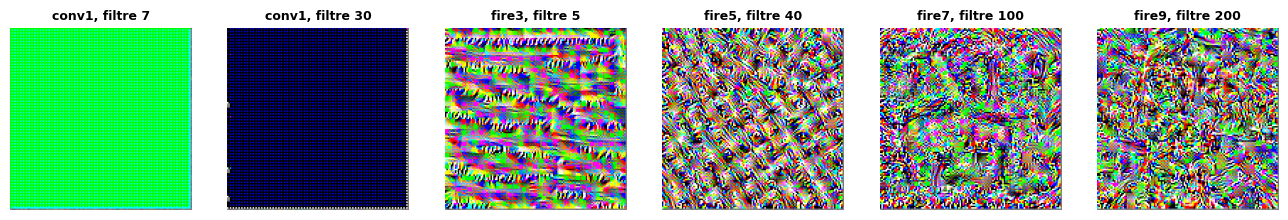

In [27]:
with checked("28.13"):
    picks_13 = [("conv1", 7), ("conv1", 30), ("fire3", 5), ("fire5", 40), ("fire7", 100), ("fire9", 200)]
    t0_13 = time.perf_counter()
    images_13 = [visualize_filter_13(NET, LAYERS[name], ch, size=128, steps=100 if FAST_MODE else 300) for name, ch in picks_13]
    print(f"6 visualisations en {fr(time.perf_counter() - t0_13, 1)} s")
    show_images(images_13, [f"{name}, filtre {ch}" for name, ch in picks_13], cols=6, size=2.2)

### Ex 28.14 — Une galerie couche par couche (fig. 28.7) 🎨 ★★ ⏱️ 25 min
**Objectif :** refaire la figure 28.7 du livre : une image par couche, qui l'excite en entier.  
**Prérequis :** Ex 28.13 · fiche §28.2.3 · **Parcours :** C

Le livre montre une image par couche de VGG16 (fig. 28.7). Fais-en autant pour les neuf couches de `LAYERS`.

**Contrat** de `visualize_layer_14(net, layer_index, size=128, steps=100, lr=0.05, seed=0)` : comme `visualize_filter_13`, mais la quantité qui monte est la moyenne des carrés des activations de **tous** les filtres de `net[layer_index]`.

La cellule de vérification produit la galerie (une dizaine de secondes), vérifie que chaque couche s'active plus fort qu'au départ, et affiche sous chaque image le gain obtenu, puis la part de hautes fréquences de chaque image (`high_freq_share`).

Dans tes notes : compare la galerie à la fig. 28.7. Les images de toutes les couches sont-elles dominées par les hautes fréquences ? Qu'est-ce que cela annonce pour 28.15 ?

9 couches en 5,6 s
✅ Ex 28.14 : chaque couche s'active plus fort (gain minimal × 69,3).


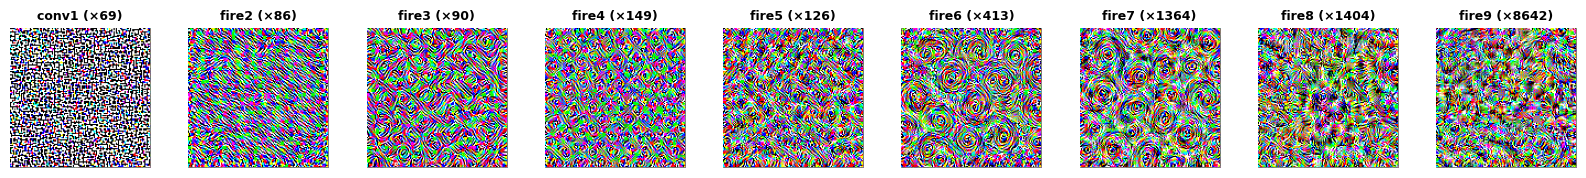

part de hautes fréquences : conv1 84 %, fire2 91 %, fire3 89 %, fire4 87 %, fire5 82 %, fire6 83 %, fire7 75 %, fire8 74 %, fire9 71 %


In [28]:
def visualize_layer_14(net, layer_index, size=128, steps=100, lr=0.05, seed=0):
    """Same as visualize_filter_13, but the quantity that goes up is the mean of the squared activations of ALL the
    filters of net[layer_index] (the whole layer)."""
    x = (torch.rand(1, 3, size, size, generator=torch.Generator().manual_seed(seed)) * 0.2 + 0.4).requires_grad_(True)
    optimizer = torch.optim.Adam([x], lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = -(net[:layer_index + 1](normalize(x)) ** 2).mean()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            x.clamp_(0, 1)
    return to_image(x)


with checked("28.14"):
    t0_14 = time.perf_counter()
    gallery_14 = {name: visualize_layer_14(NET, index, size=128, steps=80 if FAST_MODE else 300) for name, index in LAYERS.items()}
    if not returned("28.14", "visualize_layer_14", gallery_14["conv1"]):
        raise StopCheck
    print(f"9 couches en {fr(time.perf_counter() - t0_14, 1)} s")
    gains_14 = []
    for name, img in gallery_14.items():
        with torch.no_grad():
            start = torch.rand(1, 3, 128, 128, generator=torch.Generator().manual_seed(0)) * 0.2 + 0.4
            a0 = float((NET[:LAYERS[name] + 1](normalize(start)) ** 2).mean())
            a1 = float((NET[:LAYERS[name] + 1](normalize(to_batch(img))) ** 2).mean())
        gains_14.append(a1 / a0)
    verdict("28.14", min(gains_14) > 2, f"chaque couche s'active plus fort (gain minimal × {fr(min(gains_14), 1)}).",
            f"une couche ne s'active pas davantage (gain × {fr(min(gains_14), 2)}) : la loss porte-t-elle sur toute la couche ?")
    show_images(list(gallery_14.values()), [f"{n} (×{fr(g, 0)})" for n, g in zip(gallery_14, gains_14)], cols=9, size=1.8)
    hf_14 = {name: high_freq_share(img) for name, img in gallery_14.items()}
    print("part de hautes fréquences : " + ", ".join(f"{n} {pct(v, 0)}" for n, v in hf_14.items()))

### Ex 28.15 — Régulariser la visualisation : décalages, flou, octaves 🔬 ★★★ ⏱️ 40 min
**Objectif :** mesurer ce que chaque régularisation change à une visualisation : la part de hautes fréquences, et l'activation atteinte.  
**Prérequis :** Ex 28.13 · fiche §28.2.2 (encadré 🕰️) · C. Olah et coll., « Feature Visualization » (Distill, 2017) · **Parcours :** C

**Contrat** de `visualize_reg_15(net, layer_index, channel, ..., jitter=0, blur_every=0, octaves=1, octave_scale=1.4)` : la docstring de la cellule suivante. Sans régularisation (`jitter=0, blur_every=0, octaves=1`), elle doit rendre **la même image** que `visualize_filter_13` ; les trois régularisations s'ajoutent indépendamment :
- les **décalages** (*jitter*) : avant chaque pas, l'image est roulée de $(d_y, d_x)$ tirés uniformément dans $[-j, j]$ (`torch.roll`, générateur de graine `seed + 1`), le pas est fait sur l'image roulée ;
- le **flou** : tous les `blur_every` pas, un flou 3 × 3 (`F.avg_pool2d(x, 3, 1, 1, count_include_pad=False)`), sans graphe ;
- les **octaves** : on optimise d'abord une petite image, de côté `size / octave_scale**(octaves - 1)`, puis on l'agrandit d'un facteur `octave_scale` (interpolation bilinéaire) jusqu'à `size`, `steps` pas à chaque échelle.

La cellule d'expérience compare cinq réglages sur un filtre de `fire7` : l'activation atteinte et la part de hautes fréquences.

Dans tes notes : quelle régularisation réduit le plus les hautes fréquences ? Laquelle coûte le plus d'activation ? Une image régularisée excite moins le filtre : pourquoi est-elle pourtant **plus** informative ? Pourquoi les décalages empêchent-ils le réseau de « tricher » avec des motifs de quelques pixels collés à la grille de ses pas ?

In [29]:
def visualize_reg_15(net, layer_index, channel, size=128, steps=100, lr=0.05, seed=0, jitter=0, blur_every=0,
                     octaves=1, octave_scale=1.4):
    """visualize_filter_13 with three regularisations:
    - jitter: before each step, the image is rolled by (dy, dx) drawn uniformly in [-jitter, jitter] (torch.roll on the
      two last axes, a torch.Generator seeded with seed + 1), the step is made on the rolled image, then rolled back;
    - blur_every: every blur_every steps (if > 0), a 3 x 3 box blur of the image (F.avg_pool2d(x, 3, 1, 1,
      count_include_pad=False)), under torch.no_grad();
    - octaves: optimise first an image of size / octave_scale**(octaves - 1) pixels, then enlarge it
      (F.interpolate, bilinear, align_corners=False) by octave_scale up to `size`, `steps` steps at each scale.
    Return the final image (3, size, size), float32, in [0, 1]."""
    shifts = torch.Generator().manual_seed(seed + 1)
    sizes = [max(16, round(size / octave_scale ** k)) for k in range(octaves - 1, -1, -1)]
    x = torch.rand(1, 3, sizes[0], sizes[0], generator=torch.Generator().manual_seed(seed)) * 0.2 + 0.4
    for k, s in enumerate(sizes):
        if k > 0:
            x = F.interpolate(x.detach(), size=(s, s), mode="bilinear", align_corners=False).clamp(0, 1)
        x = x.detach().requires_grad_(True)
        optimizer = torch.optim.Adam([x], lr=lr)
        for step in range(steps):
            dy, dx = (torch.randint(-jitter, jitter + 1, (2,), generator=shifts).tolist() if jitter else (0, 0))
            optimizer.zero_grad()
            rolled = torch.roll(x, shifts=(dy, dx), dims=(2, 3))
            loss = -activation_13(net, rolled, layer_index, channel)
            loss.backward()
            optimizer.step()
            with torch.no_grad():
                if blur_every and (step + 1) % blur_every == 0:
                    x.copy_(F.avg_pool2d(x, 3, 1, 1, count_include_pad=False))
                x.clamp_(0, 1)
    return to_image(x)


with checked("28.15"):
    need("28.15", "activation_13")
    plain_15 = visualize_reg_15(NET, LAYERS["fire7"], 100, size=64, steps=20)
    if not returned("28.15", "visualize_reg_15", plain_15):
        raise StopCheck
    ref_15 = visualize_filter_13(NET, LAYERS["fire7"], 100, size=64, steps=20)
    same("28.15", "sans régularisation (jitter=0, blur_every=0, octaves=1), même image que visualize_filter_13",
         np.asarray(plain_15), ref_15, rtol=1e-4, atol=1e-4)
    reg_15 = np.asarray(visualize_reg_15(NET, LAYERS["fire7"], 100, size=64, steps=20, jitter=4, blur_every=5, octaves=2))
    verdict("28.15", reg_15.shape == (3, 64, 64) and 0 <= reg_15.min() and reg_15.max() <= 1,
            "avec les trois régularisations : une image (3, 64, 64) dans [0, 1].",
            f"attendu (3, 64, 64) dans [0, 1], reçu {reg_15.shape}, de {fr(reg_15.min())} à {fr(reg_15.max())}.")

✅ Ex 28.15 : sans régularisation (jitter=0, blur_every=0, octaves=1), même image que visualize_filter_13 : un tableau (3, 64, 64), comme attendu.


✅ Ex 28.15 : avec les trois régularisations : une image (3, 64, 64) dans [0, 1].


      brut : activation 598614,9, hautes fréquences 76 %
 décalages : activation 87589,1, hautes fréquences 83 %
      flou : activation 272584,9, hautes fréquences 18 %
   octaves : activation 592575,8, hautes fréquences 61 %
 les trois : activation 79818,2, hautes fréquences 7 %


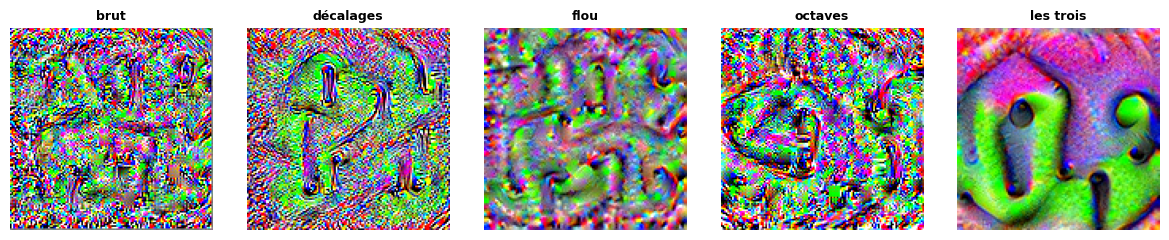

In [30]:
with checked("28.15"):
    settings_15 = {"brut": {}, "décalages": {"jitter": 6}, "flou": {"blur_every": 8},
                   "octaves": {"octaves": 3}, "les trois": {"jitter": 6, "blur_every": 8, "octaves": 3}}
    steps_15 = 60 if FAST_MODE else 200
    results_15 = {}
    for name, kw in settings_15.items():
        img = visualize_reg_15(NET, LAYERS["fire7"], 100, size=128, steps=steps_15, **kw)
        with torch.no_grad():
            act = float(activation_13(NET, to_batch(img), LAYERS["fire7"], 100))
        results_15[name] = (img, act, high_freq_share(img))
    for name, (img, act, hf) in results_15.items():
        print(f"{name:>10s} : activation {fr(act, 1):>7s}, hautes fréquences {pct(hf, 0)}")
    show_images([r[0] for r in results_15.values()], list(results_15), cols=5, size=2.4)

## Partie B · Le deep dream

Le rêve part d'une **photo** libre (fournie avec scikit-learn, sous licence CC BY 2.0 : on la crédite) et fait monter les activations de plusieurs couches à la fois, à plusieurs échelles.

In [31]:
# The photo of part B: a free photo shipped with scikit-learn (CC BY 2.0)
PHOTO_B = wb.datasets.load_sample_image("china", SIZE)
print(wb.datasets.image_credit("china"))
DREAM_LAYERS = {"fire4": 1.0, "fire6": 1.5} if FAST_MODE else {"fire4": 1.0, "fire6": 1.5, "fire8": 1.0}

Temple en Chine (photo), danielbuechele (Flickr), https://www.flickr.com/photos/danielbuechele/6061409035/, licence CC BY 2.0 (https://creativecommons.org/licenses/by/2.0/)


### Ex 28.16 — Deep dream sur une photo libre 📦 ★★★ ⏱️ 40 min 🚀
**Objectif :** écrire un deep dream à plusieurs couches et plusieurs octaves, avec un masque optionnel.  
**Prérequis :** Ex 28.11, 28.13 · fiche §28.3 · **Parcours :** C

**Contrat**
- `dream_loss_16(net, x, layer_weights)` : $L_{\text{dream}} = \sum_\ell w_\ell \cdot \operatorname{moyenne}(A_\ell^2)$ pour un batch `x` dans $[0, 1]$ (normalisé dans la fonction), les activations lues par **ton** `extract_11` en une passe ; `layer_weights` = `{nom de couche: poids}` ;
- `deep_dream_16(net, photo, layer_weights, steps=40, lr=0.01, octaves=3, octave_scale=1.4, mask=None)` : la docstring de la cellule suivante. Retiens trois points : on **monte** (`x += lr * g`) avec un gradient **normalisé** par sa valeur absolue moyenne (`g / (g.abs().mean() + 1e-8)`) ; à chaque échelle, on réinjecte les détails que la réduction a fait perdre à la photo ; le gradient est multiplié par le masque (redimensionné, plus proche voisin) quand il y en a un.

La cellule de vérification contrôle la loss de rêve sur une petite fleur, un rêve court (la loss monte, les poids ne bougent pas), puis le masque : avec une seule octave, la moitié masquée de la photo ne doit pas changer du tout. La cellule suivante fait rêver la photo avec des couches précoces, intermédiaires et profondes. 🚀 En mode complet, les images sont plus grandes et les pas plus nombreux ; tu peux aussi essayer VGG16 (`wb.datasets.load_pretrained("vgg16")`, 528 Mio, et ses couches `VGG_LAYERS`), le réseau du livre.

Dans tes notes : décris les trois rêves. Avec quelles couches vois-tu des formes d'animaux ? Pourquoi normaliser le gradient (pense à l'échelle très différente des activations d'une couche à l'autre) ?

In [32]:
def dream_loss_16(net, x, layer_weights):
    """L_dream(x) = sum over the layers of weight * mean(A**2), A the activation of net[LAYERS[name]] for the batch x in
    [0, 1] (normalised inside); layer_weights: {name: weight}. A 0-d tensor with its graph."""
    acts = extract_11(net, normalize(x), {name: LAYERS[name] for name in layer_weights})
    return sum(w * (acts[name] ** 2).mean() for name, w in layer_weights.items())


def deep_dream_16(net, photo, layer_weights, steps=40, lr=0.01, octaves=3, octave_scale=1.4, mask=None):
    """Deep dream of `photo` (3, H, W) in [0, 1]: gradient ASCENT on dream_loss_16, at `octaves` scales (the smallest
    first: H / octave_scale**(octaves - 1)). At each scale: the dreamed image so far, enlarged (bilinear) to this
    scale, plus the details lost by shrinking the photo (the photo at this scale minus the photo shrunk once more and
    re-enlarged), clamped to [0, 1]; then `steps` steps x <- x + lr * g / mean(|g|) (g the gradient, normalised by its
    mean absolute value + 1e-8), multiplied by `mask` (a tensor (H', W') of 0 and 1 resized to the scale, nearest)
    if given, the pixels clamped after each step. Returns (3, H, W), float32, in [0, 1]."""
    base = to_batch(photo)
    H, W = base.shape[-2:]
    shapes = [(max(16, round(H / octave_scale ** k)), max(16, round(W / octave_scale ** k))) for k in range(octaves - 1, -1, -1)]
    resize = lambda t, s: F.interpolate(t, size=s, mode="bilinear", align_corners=False)
    dream = None
    for k, shape in enumerate(shapes):
        photo_k = resize(base, shape)
        if dream is None:
            x = photo_k.clone()
        else:
            detail = photo_k - resize(resize(base, shapes[k - 1]), shape)
            x = (resize(dream, shape) + detail).clamp(0, 1)
        m = None
        if mask is not None:
            m = F.interpolate(torch.as_tensor(mask, dtype=torch.float32)[None, None], size=shape, mode="nearest")
        x = x.detach().requires_grad_(True)
        for _ in range(steps):
            loss = dream_loss_16(net, x, layer_weights)
            (g,) = torch.autograd.grad(loss, x)
            g = g / (g.abs().mean() + 1e-8)
            if m is not None:
                g = g * m
            with torch.no_grad():
                x += lr * g
                x.clamp_(0, 1)
        dream = x.detach()
    return to_image(dream)


with checked("28.16"):
    need("28.16", "extract_11")
    small_16 = wb.datasets.load_sample_image("flower", 64)
    loss0_16 = dream_loss_16(NET, to_batch(small_16), {"fire3": 1.0, "fire5": 2.0})
    with torch.no_grad():
        xn_16 = normalize(to_batch(small_16))
        want0_16 = float((NET[:5](xn_16) ** 2).mean() + 2 * (NET[:8](xn_16) ** 2).mean())
    same("28.16", "dream_loss_16(fleur, {fire3: 1, fire5: 2})", float(loss0_16), want0_16, rtol=1e-5)
    signature_16 = weights_signature(NET)
    dream_16 = deep_dream_16(NET, small_16, {"fire3": 1.0, "fire5": 2.0}, steps=8, octaves=2)
    if not returned("28.16", "deep_dream_16", dream_16):
        raise StopCheck
    dream_16 = np.asarray(dream_16)
    verdict("28.16", dream_16.shape == small_16.shape and 0 <= dream_16.min() and dream_16.max() <= 1,
            "une image de la taille de la photo, dans [0, 1].", f"attendu {small_16.shape} dans [0, 1], reçu {dream_16.shape}.")
    with torch.no_grad():
        gain_16 = float(dream_loss_16(NET, to_batch(dream_16), {"fire3": 1.0, "fire5": 2.0})) / float(loss0_16)
    verdict("28.16", gain_16 > 1.3, f"le rêve fait monter la loss de rêve (× {fr(gain_16, 2)}).",
            f"la loss de rêve ne monte pas (× {fr(gain_16, 2)}) : une montée, sur l'image, avec le gradient normalisé ?")
    verdict("28.16", weights_signature(NET) == signature_16, "les poids du réseau n'ont pas bougé.", "les poids ont changé.")
    one_16 = np.asarray(deep_dream_16(NET, small_16, {"fire3": 1.0}, steps=1, lr=0.01, octaves=1))
    step_16 = float(np.abs(one_16 - small_16).mean())
    verdict("28.16", 0.004 < step_16 <= 0.0101, f"un pas change chaque pixel de {fr(step_16, 4)} en moyenne (lr = 0,01, gradient normalisé).",
            f"un pas change les pixels de {fr(step_16, 5)} en moyenne, pour lr = 0,01 : divise le gradient par sa valeur absolue moyenne.")
    same_16 = np.asarray(deep_dream_16(NET, small_16, {"fire3": 1.0}, steps=0, octaves=2))
    verdict("28.16", float(np.abs(same_16 - small_16).max()) < 1e-4,
            "sans aucun pas, deux octaves rendent la photo intacte : les détails perdus sont réinjectés.",
            "sans aucun pas, deux octaves ne rendent pas la photo : réinjecte les détails perdus (photo à l'échelle moins photo réduite puis agrandie).")
    mask_16 = torch.zeros(dream_16.shape[1:])
    mask_16[:, : dream_16.shape[2] // 2] = 1
    half_16 = np.asarray(deep_dream_16(NET, small_16, {"fire3": 1.0}, steps=6, octaves=1, mask=mask_16))
    right_16 = float(np.abs(half_16 - small_16)[:, :, dream_16.shape[2] // 2:].max())
    verdict("28.16", right_16 < 1e-6, "avec un masque, la moitié masquée ne bouge pas.",
            f"la moitié masquée a changé (jusqu'à {fr(right_16)}) : multiplie le gradient par le masque (octaves=1 ici).")

✅ Ex 28.16 : dream_loss_16(fleur, {fire3: 1, fire5: 2}) : 1245.99621582, comme attendu.
✅ Ex 28.16 : une image de la taille de la photo, dans [0, 1].
✅ Ex 28.16 : le rêve fait monter la loss de rêve (× 4,86).
✅ Ex 28.16 : les poids du réseau n'ont pas bougé.
✅ Ex 28.16 : un pas change chaque pixel de 0,0092 en moyenne (lr = 0,01, gradient normalisé).
✅ Ex 28.16 : sans aucun pas, deux octaves rendent la photo intacte : les détails perdus sont réinjectés.
✅ Ex 28.16 : avec un masque, la moitié masquée ne bouge pas.


3 rêves en 2,0 s


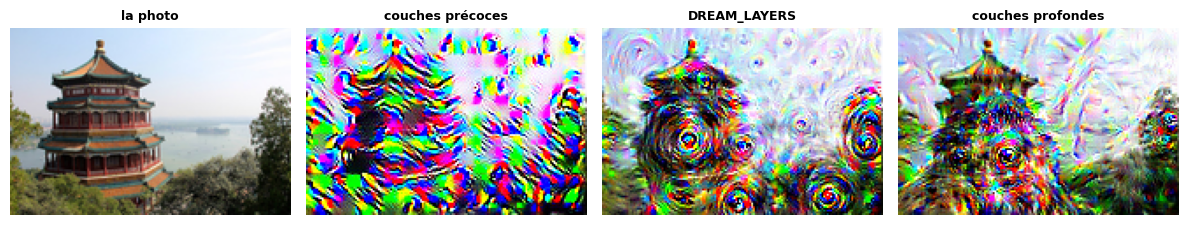

In [33]:
with checked("28.16"):
    t0_16 = time.perf_counter()
    dreams_16 = [deep_dream_16(NET, PHOTO_B, w, steps=30 if FAST_MODE else 80, lr=0.012)
                 for w in ({"conv1": 1.0, "fire2": 1.0}, DREAM_LAYERS, {"fire8": 1.0, "fire9": 1.0})]
    print(f"3 rêves en {fr(time.perf_counter() - t0_16, 1)} s")
    show_images([PHOTO_B] + dreams_16, ["la photo", "couches précoces", "DREAM_LAYERS", "couches profondes"], cols=4, size=3)

### Ex 28.17 — Choisir couches et poids, ne rêver que dans une zone 🔬 ★★★ ⏱️ 30 min
**Objectif :** composer un rêve : choisir les couches et leurs poids, et limiter le rêve à une zone de la photo par un masque.  
**Prérequis :** Ex 28.16 · fiche §28.3 · **Parcours :** C

Choisis tes couches et leurs poids (`layers_17`, au moins deux couches) et un masque (`mask_17`, un tenseur de 0 et de 1 à la taille de `PHOTO_B` : 1 là où le rêve a le droit de changer la photo). Par exemple : le ciel seulement, ou tout sauf le bâtiment. La cellule de vérification fait rêver la photo dans ta zone, vérifie que rien n'a bougé ailleurs et montre la carte des changements.

Dans tes notes : essaie au moins deux jeux de poids. Qu'est-ce qui change quand on donne plus de poids à une couche profonde ? Pourquoi un masque appliqué au **gradient** laisse-t-il quand même voir, au bord de la zone, des motifs qui débordent ? (Pense au champ récepteur.)

✅ Ex 28.17 : un masque de 0 et de 1 à la taille de la photo.


changement moyen dans la zone : 0,093 ; changement maximal hors de la zone : 0,000000
✅ Ex 28.17 : hors de la zone, la photo n'a pas bougé.


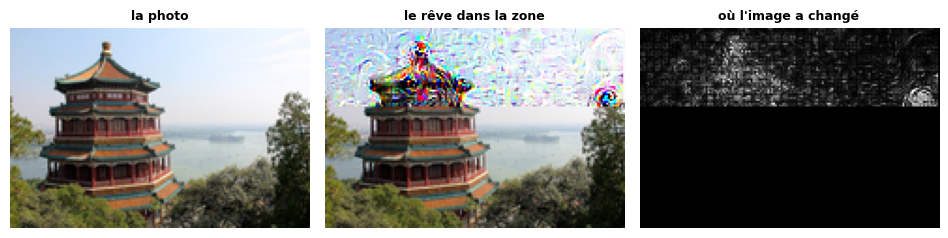

In [34]:
layers_17 = {"fire5": 1.0, "fire7": 2.0}
mask_17 = torch.zeros(PHOTO_B.shape[1:])
mask_17[: PHOTO_B.shape[1] * 2 // 5] = 1        # the sky only (the top of the photo)

with checked("28.17"):
    need("28.17", "deep_dream_16")
    if not filled(layers_17, mask_17):
        print("⏳ Ex 28.17 : choisis tes couches et ton masque dans la cellule précédente.")
        raise StopCheck
    m_17 = torch.as_tensor(mask_17, dtype=torch.float32)
    verdict("28.17", tuple(m_17.shape) == tuple(PHOTO_B.shape[1:]) and bool(((m_17 == 0) | (m_17 == 1)).all()),
            "un masque de 0 et de 1 à la taille de la photo.", f"attendu un masque {tuple(PHOTO_B.shape[1:])} de 0 et de 1, reçu {tuple(m_17.shape)}.")
    dream_17 = np.asarray(deep_dream_16(NET, PHOTO_B, layers_17, steps=30 if FAST_MODE else 80, lr=0.012, octaves=1, mask=m_17))
    change_17 = np.abs(dream_17 - PHOTO_B).mean(axis=0)
    inside_17 = float(change_17[m_17.numpy() == 1].mean()) if m_17.sum() > 0 else 0.0
    outside_17 = float(change_17[m_17.numpy() == 0].max()) if (m_17 == 0).any() else 0.0
    print(f"changement moyen dans la zone : {fr(inside_17, 3)} ; changement maximal hors de la zone : {fr(outside_17, 6)}")
    verdict("28.17", outside_17 < 1e-6, "hors de la zone, la photo n'a pas bougé.", "des pixels ont changé hors de la zone.")
    show_images([PHOTO_B, dream_17, np.stack([change_17 / max(change_17.max(), 1e-8)] * 3)],
                ["la photo", "le rêve dans la zone", "où l'image a changé"], size=3.2)

## Partie C · Le transfert de style

Le contenu : une photo libre ; le style : *La Nuit étoilée* (domaine public). D'abord la matrice de Gram, puis trois exercices pour **lire** et **déboguer** avant d'écrire : une prédiction, des courbes, un script fautif. Ensuite les reconstructions couche par couche, ton transfert de style complet, ses réglages, une alternative à la matrice de Gram, une galerie documentée et le défi. Conventions de ce notebook (✏️ 28.4) : la loss de contenu est une **moyenne** (`F.mse_loss`), la loss de style une **somme** sur les coefficients des matrices de Gram **normalisées** ; les poids `ALPHA`, `BETA`, `TV` sont réglés pour ces conventions.

Vincent van Gogh, « La Nuit étoilée » (1889), Museum of Modern Art, New York ; reproduction : https://upload.wikimedia.org/wikipedia/commons/thumb/e/ea/Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg/500px-Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg ; domaine public (l'artiste est mort en 1890 : plus de 70 ans) ; reproduction fidèle non protégée (directive (UE) 2019/790, art. 14)


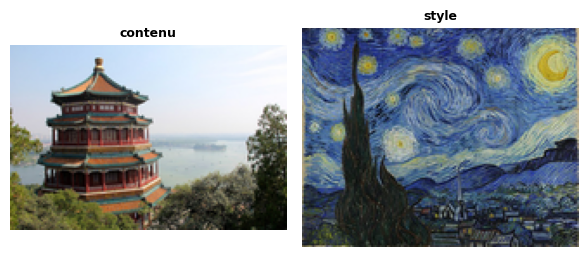

In [35]:
# The images and the settings of part C: a free photo (content) and a public-domain painting (style)
CONTENT_C = wb.datasets.load_sample_image("china", SIZE)
STYLE_C = wb.datasets.load_style_image("starry_night", SIZE)
CONTENT_LAYERS = ["fire6"]                                # one deep layer for the content
STYLE_LAYERS = ["conv1", "fire2", "fire3", "fire5"]       # four layers for the style, equal weights
ALPHA, BETA, TV = 1.0, 10.0, 0.05                         # tuned for these conventions (see 28.18 and 28.23)
STEPS_C = 150 if FAST_MODE else 400
print(wb.datasets.image_credit("starry_night"))
show_images([CONTENT_C, STYLE_C], ["contenu", "style"], size=3)

### Ex 28.18 — La matrice de Gram en PyTorch, vérifiée contre NumPy 📦 ★ ⏱️ 15 min
**Objectif :** écrire la matrice de Gram normalisée et la variation totale en PyTorch, et les vérifier contre NumPy.  
**Prérequis :** ✏️ 28.2, 28.4 · fiche §28.4.1, §28.4.5 (encadrés 🧮) · **Parcours :** R, M, C

**Contrat**
- `gram_matrix_18(A)` : pour un tenseur `(C, H, W)`, la matrice `(C, C)` $G = \frac{1}{CHW} F F^\top$ ($F$ : les cartes mises à plat en lignes) ; pour un batch `(N, C, H, W)`, une matrice par image, `(N, C, C)` ; sans NumPy, pour que le gradient passe ;
- `tv_loss_18(x)` : pour un batch d'images `(N, 3, H, W)`, la somme des carrés des écarts entre pixels voisins, verticalement et horizontalement, sur tous les canaux et toutes les images.

Exemple (✏️ 28.2) : pour $F = \begin{pmatrix} 3 & 1 \\ 0 & 2 \end{pmatrix}$ (deux filtres, deux positions, rangées dans un tenseur `(2, 1, 2)`), $G = \begin{pmatrix} 2{,}5 & 0{,}5 \\ 0{,}5 & 1 \end{pmatrix}$.

La cellule de vérification compare tes deux fonctions à `np.einsum` et à `np.diff` sur des tableaux au hasard, et vérifie que le gradient traverse `gram_matrix_18`.

In [36]:
def gram_matrix_18(A):
    """The normalised Gram matrix of activations A: a tensor (C, H, W) -> (C, C), or (N, C, H, W) -> (N, C, C);
    G = F F^T / (C * H * W) with F the maps flattened into rows. Differentiable (no numpy inside)."""
    C, H, W = A.shape[-3:]
    flat = A.reshape(*A.shape[:-2], H * W)
    return flat @ flat.transpose(-1, -2) / (C * H * W)


def tv_loss_18(x):
    """The total variation of an image batch x (N, 3, H, W): the sum of the squared differences between neighbouring
    pixels, vertically and horizontally, over every channel and image. A 0-d tensor."""
    return ((x[..., 1:, :] - x[..., :-1, :]) ** 2).sum() + ((x[..., :, 1:] - x[..., :, :-1]) ** 2).sum()


with checked("28.18"):
    rng_18 = np.random.default_rng(18)
    A_18 = rng_18.random((5, 7, 6))
    G_18 = gram_matrix_18(torch.tensor(A_18))
    if not returned("28.18", "gram_matrix_18", G_18):
        raise StopCheck
    same("28.18", "gram_matrix_18 sur (5, 7, 6), contre np.einsum", G_18, np.einsum("chw,dhw->cd", A_18, A_18) / A_18.size)
    B_18 = rng_18.random((2, 4, 3, 5))
    same("28.18", "gram_matrix_18 sur un batch (2, 4, 3, 5)", gram_matrix_18(torch.tensor(B_18)),
         np.einsum("nchw,ndhw->ncd", B_18, B_18) / (4 * 3 * 5))
    A_grad_18 = torch.tensor(A_18, requires_grad=True)
    gram_matrix_18(A_grad_18).sum().backward()
    verdict("28.18", A_grad_18.grad is not None, "le gradient traverse gram_matrix_18.", "pas de gradient : du NumPy dans la fonction ?")
    X_18 = rng_18.random((2, 3, 4, 5))
    same("28.18", "tv_loss_18 sur (2, 3, 4, 5)", float(tv_loss_18(torch.tensor(X_18))),
         float((np.diff(X_18, axis=2) ** 2).sum() + (np.diff(X_18, axis=3) ** 2).sum()))

✅ Ex 28.18 : gram_matrix_18 sur (5, 7, 6), contre np.einsum : un tableau (5, 5), comme attendu.
✅ Ex 28.18 : gram_matrix_18 sur un batch (2, 4, 3, 5) : un tableau (2, 4, 4), comme attendu.
✅ Ex 28.18 : le gradient traverse gram_matrix_18.
✅ Ex 28.18 : tv_loss_18 sur (2, 3, 4, 5) : 29.95386804, comme attendu.


### Ex 28.19 — Prédire une reconstruction depuis le bruit : contenu profond seul, style seul 🔮 ★ ⏱️ 10 min
**Objectif :** prédire, en chiffres, ce qu'une reconstruction depuis le bruit garde de la photo, selon la couche et la loss.  
**Prérequis :** Ex 28.18 · fiche §28.4.3, §28.4.4 · **Parcours :** C

On part d'un bruit et l'on optimise les pixels pour égaler, au choix, les activations d'une **seule** couche de la photo (loss de contenu), ou les matrices de Gram du tableau (loss de style), comme le livre aux fig. 28.19 et 28.23. La cellule suivante charge les résultats (la solution de 28.22, trois graines) : l'erreur quadratique moyenne, pixel par pixel, entre la photo et ses reconstructions depuis `conv1` et depuis `fire7`, et la corrélation, pixel par pixel, entre la reconstruction du **style** et la photo.

**Avant d'exécuter**, écris tes deux prédictions :
a) l'erreur de la reconstruction depuis `fire7`, divisée par celle depuis `conv1` : `"A"` moins de 1,5, `"B"` de 1,5 à 5, `"C"` plus de 5 ;
b) `True` ou `False` : la corrélation entre la reconstruction du style et la photo reste sous 0,1 en valeur absolue, pour les trois graines.

La cellule d'expérience n'affiche rien tant que tes deux prédictions ne sont pas écrites.

In [37]:
# Reconstructions from noise (the solution of 28.22, tools/chapters/history_ch28.py), for three seeds: the photo
# CONTENT_C rebuilt from the activations of conv1 or of fire7 alone, and the painting STYLE_C rebuilt from the Gram
# matrices of all of STYLE_LAYERS. Measured: the mean squared error to the photo, pixel by pixel (images in [0, 1]),
# and the correlation, pixel by pixel, between the style reconstruction and the photo (both in grey levels).
RECON_19 = unpack("eNqrVioqzStWslKIrlYqTk1NAbIMdBSUcotT45Pz88oMQXw9AwMTc0uoaFpmUao5WNTQzNAYJJqcX1QUX1xSmZMKFNYFqjY0NKnVUYCbZ4jNPDNDLOYZm5liM8/I1BzZPCNs5pmaYTPPBKv7TAwsa2NrATPzRVs=")   # packed, so that the numbers stay hidden until the experiment cell

In [38]:
ratio_19, corr_19 = "C", True

In [39]:
wb.record("28.19a", "C", mistakes={"compare les deux colonnes d'erreur : le rapport est-il proche de 1 ?": "A", "calcule le rapport des deux erreurs, graine par graine": "B"})
wb.record("28.19b", True, mistakes={"regarde la colonne des corrélations, en valeur absolue": False})

WB_ANSWER {"hash": "605ac119a8649a779ee389215748716de9fbe101eca4ca7911ad12642bc8ca5b", "id": "28.19a", "kind": "str", "mistakes": {"4df15344056f90de6ca54b0dd40b6cd8d3801e024867139fcf5d54b5f345848a": "calcule le rapport des deux erreurs, graine par graine", "ba1d8d6756b23f3cb5508ccb6d5507d594892ccc999a1206b43fc0f0dccbc554": "compare les deux colonnes d'erreur : le rapport est-il proche de 1 ?"}}
📝 Ex 28.19a : réponse enregistrée (str).
WB_ANSWER {"hash": "f3feea524587a40f6bbe7fc9170d061f3adfd003ff66aac89626b9b1c1f6b20b", "id": "28.19b", "kind": "bool", "mistakes": {"c3e812b4b3ebd7bcaab203a24ca4cda9ca6ccf8dbb8f42397af71ecbe06658e3": "regarde la colonne des corrélations, en valeur absolue"}}
📝 Ex 28.19b : réponse enregistrée (bool).


In [40]:
if any(answer is ... or answer is None for answer in [ratio_19, corr_19]):
    print("⏳ Ex 28.19 : écris d'abord tes deux prédictions dans la cellule précédente.")
else:
    print(f"{'graine':>6s} {'erreur conv1':>13s} {'erreur fire7':>13s} {'rapport':>8s} {'corrélation (style)':>20s}")
    for run_19 in RECON_19["runs"]:
        print(f"{run_19['seed']:6d} {fr(run_19['mse_conv1'], 4):>13s} {fr(run_19['mse_fire7'], 4):>13s} "
              f"{fr(run_19['mse_fire7'] / run_19['mse_conv1'], 1):>8s} {fr(run_19['corr_style'], 3):>20s}")
    wb.check("28.19a", ratio_19)
    wb.check("28.19b", corr_19)

graine  erreur conv1  erreur fire7  rapport  corrélation (style)
     0        0,0048        0,1614     33,7               -0,011
     1        0,0046        0,1636     35,5               -0,026
     2        0,0046        0,1635     35,9               -0,041
✅ Ex 28.19a : Bravo !
✅ Ex 28.19b : Exact !


Dans tes notes : tes prédictions étaient-elles justes ? Pourquoi une reconstruction depuis `fire7` peut-elle avoir une grosse erreur pixel et garder pourtant la scène (tu le verras en 28.22) ? Pourquoi la corrélation du style avec la photo ne pouvait-elle pas être forte (∂ 28.3) ?

### Ex 28.20 — Lire les courbes de losses d'un transfert de style 📈 ★★ ⏱️ 15 min
**Objectif :** lire les trois termes pondérés d'un transfert de style, et reconnaître un départ et un réglage à leurs courbes.  
**Prérequis :** Ex 28.18 · fiche §28.4.5 · ✏️ 28.4 · **Parcours :** R, C

La cellule suivante trace trois transferts de style réels (la solution de 28.23, 150 pas), sous des lettres mélangées : les trois termes **pondérés**, $\alpha L_c$, $\beta L_s$ et $\lambda L_{TV}$, tous les 5 pas, sur une échelle logarithmique. L'un a les réglages de la partie C ; les deux autres changent **une** chose chacun.

Lis les courbes et écris :
a) la lettre de l'essai qui part d'un **bruit** (et non de la photo) ;
b) la lettre de l'essai dont le terme de style pondéré reste, à la fin, plus de 10 fois au-dessus du terme de contenu pondéré ;
c) pour l'essai A : de combien de puissances de dix le terme de style pondéré descend-il entre le pas 0 et la fin ? (un entier, lu sur les graduations)

Dans tes notes : qu'a-t-on changé dans chacun des deux autres essais ? Pourquoi la variation totale **monte**-t-elle dans deux essais ? Pourquoi un terme de contenu nul au départ n'est-il pas un bon signe en soi ?

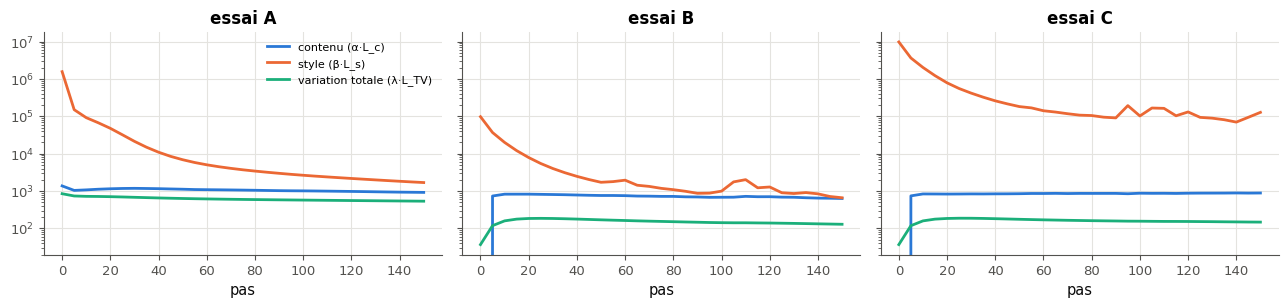

In [41]:
# Three real style transfers (the solution of 28.23, CONTENT_C, STYLE_C, 150 steps), under shuffled letters: the
# three WEIGHTED terms (alpha * L_c, beta * L_s, tv * L_tv) every 5 steps. One run has the settings of part C; the
# others change ONE thing each.
CURVES_20 = unpack("eNptVsuOZTUM/JVWr0dR/IptdsBnoF6h2aFGYhokNOp/p8q5LTQwm3utk5ddrqrk6/Mff75+ef7h6evzj/P76++vb59f3xD/Ipa2XPTTk2yXpR6MMpZNJNKrtzEKjJ5mhBW7DqPSlSXzTZbbRJGr71qrx36ie1lwdHeuyGJUtbBqor3C51gcUZPKkY9B71XCw7YlEmCgsZArI8lHnlt0yeyxfYVisDtWOU7qOpiEsc6zitv3OasDW3XEan7wWNKosi2WNzZsrWWsp5F6Rb18enr+8vb3b58HszjpG9nw5NgO3KJ95pqunZ+eTko78sbenil7bcNc032wKjFBxTemNpHwFlTbUzfSQh0IkbqiEKw61b1M8S1qY1SQFQ61pRur3UvWmYN27OXJcxIg7MQ3c/XVrMyEeLNo7TKUhG9a+5G5Hj/LlYnFrlXNyCpXsfeKlJc2s0brm0npzlrJoqSr15nsewdSxlLwAocdfktAbExUDhKodCL59hdhRIkrBNOTROG6VMGJyDHl3MQSMMdGxQd4Nql2wJZiqw+wlCLY4TgChx1XnMAAbTiHc9QegYANTONMeZwD/PEVWDZo4RMQjcH5rCT7Aj2QxPIAAEkyBdVigCJOg41cdeImH+CsJpIPKMCZc4TdKoIkJqYBmJW4BFI9TDWs0XCuAvVOxMs78PnpvyoFgQgTCjZyAwIgN0ux29YbCPUFpSwjqQq4JWWTXSAfA3SdKaCwtQUVJPLd6jfQQimJfMETnuS33LSNmjgHMqDkwGv0TNmYfeXFxpw0cr5XXsKiDeTcKQiVGLGvnrMKXWQy+0G3A46B4HfRUe53qAu2DPTQ7beth/WyrbHtGy12MkcZsuM8tDKGnnQLp29BJUB4M4vCYX5uGyCfFooGiG12xGhNYybq6bft0DNUTM8hIa/7ZVGNdB+6R7EacfKNihJDpONNAl3CAcffenk0nSgXeVEJ7HYzgLsS8CaIMnKpS2FFj0BCnqiqVwOihb7QrzbdFidXNHakTcFj8hh9Q2+iKYB6GI/2QiL/6s7gfteqC9iPh4HLOsVBbSNqHBQ5SgY8pOd8GShQV5TdyRWzCn5yOARNFM1LYLAyuaOZPV9whB+igRbd5SBbU0m8WGy8Ag1Pdl5oRs0hh4/NKv+AgF6r9U2Au4WeK1ASF6PxVRxAnUb2CZoYwQPYphnZyGqgBTX6jOZ+/r7maCk0mSJqMQFwlQnQReZdZtcACz6WbP5MplkVsmxyuODX7BeMQGaX0RwHzmZ3GNTVZcE+zlwBcJZRVh20ndjPF5/lqG0mOykdpFLcG5P7tHFDCJ3cKnC9T98plyOwUJ9/Is9/gwdxKiy6pwAan84UVpL/lxy4syk5N3pOjubMcHfeW1HhjWDDqC6ZgVMKEU5DF05x8AecErbKNNibpvUr/BhF9VxQAgslLMM7pbjGT3GXKOgz9yv633xAzBzbVOzYMZ4kcJjrhnzQEI1JDS+KQ3OkapzwF2nUO5vPCq7EK8DQHuKLxwZuSVymc4MdwmEsVo45uP2YY8YL0oZ9WNG3qrbk7pQIbhxcUrN7Ce/uKRUeqnUfSxDJoeQIXR5c+LiGv6/Y6TblJCNUHGwfip07C1ciXlN5Ax1Tgg3L8H6us2tiq+YffBpQUu/VRwmnTcCNp2rAIhPg2TcmxcfZ+B6yOPM4DF73/lD3PMjiPMAMOr7cYO+4wh/IGdg8/ELRp4cV3NzxlLHJx+kbfc3BxohAjhP68v7+/g+ZTiBk")
fig_20, axes_20 = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax_20, (letter_20, run_20) in zip(axes_20, sorted(CURVES_20["runs"].items())):
    steps_20 = [5 * k for k in range(len(run_20["content"]))]
    for key_20, label_20 in (("content", "contenu (α·L_c)"), ("style", "style (β·L_s)"), ("tv", "variation totale (λ·L_TV)")):
        ax_20.plot(steps_20, run_20[key_20], label=label_20)
    ax_20.set_yscale("log")
    ax_20.set_title(f"essai {letter_20}")
    ax_20.set_xlabel("pas")
axes_20[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [42]:
noise_20, heavy_20, first_20 = "A", "C", 3

In [43]:
wb.record("28.20a", "A", mistakes={"partir de la photo, c'est un terme de contenu nul au départ : cherche l'essai où il ne l'est pas": "B", "regarde le terme de contenu au pas 0 de chaque essai": "C"})
wb.record("28.20b", "C", mistakes={"compare les deux courbes à la fin de chaque essai, sur l'échelle logarithmique : un facteur 10, c'est une graduation": "A", "regarde l'écart entre style et contenu au dernier pas": "B"})
wb.record("28.20c", 3, mistakes={"compte les graduations (puissances de dix) que descend la courbe de style de l'essai A": 2, "l'axe est logarithmique : une graduation, c'est un facteur 10": 4})

WB_ANSWER {"hash": "fa780bf1bfe00712f4757ff007f3f3db6887076d9db9201de9bc23f4b3497c94", "id": "28.20a", "kind": "str", "mistakes": {"c21b4bc7a35298fa0c06afe99564f805d1bcc5d87669a1a180034713b739e17e": "regarde le terme de contenu au pas 0 de chaque essai", "e1c52baeb87e83ac96498e65c380395630238d7503af53b8e39f622a12ec60bc": "partir de la photo, c'est un terme de contenu nul au départ : cherche l'essai où il ne l'est pas"}}
📝 Ex 28.20a : réponse enregistrée (str).
WB_ANSWER {"hash": "7efd652055c0dd377519df20872f5012aee3876e3f30df17e794167000df1c25", "id": "28.20b", "kind": "str", "mistakes": {"14c7fd4e72927df514ebf9db8dd76b035848e9babd6a8002ff15d7aded7d8e3a": "compare les deux courbes à la fin de chaque essai, sur l'échelle logarithmique : un facteur 10, c'est une graduation", "1732f1c5a6155dd601f9daa08db0e5e1a50f00aa2377a179ad819e5a10c79f93": "regarde l'écart entre style et contenu au dernier pas"}}
📝 Ex 28.20b : réponse enregistrée (str).
WB_ANSWER {"hash": "2380e8114b0374134573ea72d089e

### Ex 28.21 — Le transfert de style qui ne produisait que du gris 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver et corriger les quatre erreurs d'un script de transfert de style, guidé par des diagnostics enchaînés.  
**Prérequis :** Ex 28.18, 28.11 · fiche §28.4.5, pièges ⚠️ · **Parcours :** C

Le script `style_transfer_buggy_21` part d'une image grise (c'est voulu) et devrait la transformer en une photo peinte. Il ne rend que du gris. La cellule suivante le définit et lance `diagnose_21`, quatre diagnostics enchaînés, chacun ne s'exécutant que si le précédent passe (une erreur peut en cacher une autre) : les pixels bougent-ils ? que reçoit la première couche ? quel est le rapport entre le terme de style et le terme de contenu au premier pas ? dans quelle plage finissent les pixels ?

1. Écris dans `faulty_21` les lettres des lignes fautives (dans n'importe quel ordre). Il y en a **quatre**.
2. Recopie la fonction dans `style_transfer_fixed_21` et corrige-la : même signature, mêmes sorties, même départ gris. La cellule de vérification relance les diagnostics sur ta version.

Dans tes notes : pour chaque erreur, le symptôme qu'elle produit seule. Laquelle expliquait le gris ? Pourquoi `clamp_(-3, 3)` est-il une confusion entre deux espaces de pixels ?

In [44]:
# The script to debug (do not change this cell: copy the function into the next one to fix it)
def style_transfer_buggy_21(net, content, style, steps=60, lr=0.05):
    def features(x, index):                                                       # A
        return net[:index + 1](x)                                                 # B
    def gram(A):                                                                  # C
        flat = A.reshape(A.shape[1], -1)                                          # D
        return flat @ flat.T                                                      # E
    c, s = to_batch(content), to_batch(style)                                     # F
    with torch.no_grad():                                                         # G
        target_c = features(c, LAYERS["fire6"])                                   # H
        targets_s = {n: gram(features(s, LAYERS[n])) for n in STYLE_LAYERS}      # I
    x = torch.full_like(c, 0.5).requires_grad_(True)                              # J
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)                         # K
    first = None
    for step in range(steps):                                                     # L
        l_c = F.mse_loss(features(x, LAYERS["fire6"]), target_c)                  # M
        l_s = sum(((gram(features(x, LAYERS[n])) - targets_s[n]) ** 2).sum() for n in STYLE_LAYERS)   # N
        l_tv = ((x[..., 1:, :] - x[..., :-1, :]) ** 2).sum() + ((x[..., 1:] - x[..., :-1]) ** 2).sum()  # O
        if first is None:
            first = (ALPHA * l_c.item(), BETA * l_s.item())
        optimizer.zero_grad()                                                     # P
        (ALPHA * l_c + BETA * l_s + TV * l_tv).backward()                         # Q
        optimizer.step()                                                          # R
        with torch.no_grad():
            x.clamp_(-3, 3)                                                       # S
    return x.detach()[0].numpy(), first


def diagnose_21(fn, steps=25):
    """Four diagnoses in a row, on small images; the first one that fails stops the chain (one bug can hide another)."""
    c, s = wb.datasets.load_sample_image("china", 64), wb.datasets.load_style_image("starry_night", 64)
    seen = []
    handle = NET[0].register_forward_pre_hook(lambda m, inputs: seen.append(float(inputs[0].detach().mean())))
    try:
        img, first = fn(NET, c, s, steps=steps)
    finally:
        handle.remove()
    img = np.asarray(img)
    moved = float(np.abs(img - 0.5).max())
    ratio = first[1] / max(first[0], 1e-12)
    ratio_text = f"{ratio:.3g}".replace(".", ",")
    points = [  # (what passes, test, what was measured, what is wrong)
        ("les pixels bougent", moved >= 1e-6, f"écart maximal à l'image grise de départ : {fr(moved, 4)}",
         "l'image n'a pas changé : qu'est-ce que l'optimiseur met à jour ?"),
        ("la première couche reçoit des pixels normalisés", min(seen) <= 0.2,
         f"moyenne des pixels reçus par la première couche : {fr(min(seen), 3)} à {fr(max(seen), 3)}",
         "des pixels autour de 0,45 : le réseau attend des images normalisées comme celles d'ImageNet."),
        ("le style n'écrase pas le contenu au premier pas", ratio <= 1e6,
         f"terme de style / terme de contenu au premier pas : {ratio_text}",
         "le style écrase tout : compare l'échelle des matrices de Gram à celle de la fiche."),
        ("les pixels finissent dans [0, 1]", img.min() >= 0 and img.max() <= 1,
         f"plage des pixels à la fin : {fr(img.min(), 3)} à {fr(img.max(), 3)}",
         "des pixels hors de [0, 1] : ils ne s'affichent pas, et le réseau n'en a jamais vu de tels."),
    ]
    for k, (name, ok, measured, why) in enumerate(points, start=1):
        if ok:
            print(f"✅ Ex 28.21 : point {k}, {name} ({measured}).")
        else:
            print(f"❌ Ex 28.21 : point {k} : {measured} ; {why}")
            for later in range(k + 1, len(points) + 1):
                print(f"⏳ Ex 28.21 : point {later} : corrige d'abord le point {k}.")
            return False
    print("✅ Ex 28.21 : les quatre diagnostics passent.")
    return True


_ = diagnose_21(style_transfer_buggy_21)

❌ Ex 28.21 : point 1 : écart maximal à l'image grise de départ : 0,0000 ; l'image n'a pas changé : qu'est-ce que l'optimiseur met à jour ?
⏳ Ex 28.21 : point 2 : corrige d'abord le point 1.
⏳ Ex 28.21 : point 3 : corrige d'abord le point 1.
⏳ Ex 28.21 : point 4 : corrige d'abord le point 1.


✅ Ex 28.21 : Exact !


✅ Ex 28.21 : point 1, les pixels bougent (écart maximal à l'image grise de départ : 0,5000).
✅ Ex 28.21 : point 2, la première couche reçoit des pixels normalisés (moyenne des pixels reçus par la première couche : -0,375 à 0,508).
✅ Ex 28.21 : point 3, le style n'écrase pas le contenu au premier pas (terme de style / terme de contenu au premier pas : 388).
✅ Ex 28.21 : point 4, les pixels finissent dans [0, 1] (plage des pixels à la fin : 0,000 à 1,000).
✅ Ex 28.21 : les quatre diagnostics passent.
✅ Ex 28.21 : ta version corrigée passe les quatre diagnostics.


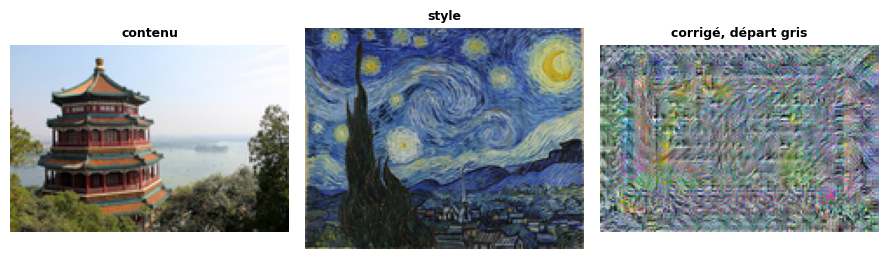

In [45]:
faulty_21 = "BEKS"


def style_transfer_fixed_21(net, content, style, steps=60, lr=0.05):
    """The script of style_transfer_buggy_21, fixed (same signature, same returns, same gray start)."""
    def features(x, index):                                                       # A
        return net[:index + 1](normalize(x))                                      # B: the ImageNet normalisation
    def gram(A):                                                                  # C
        flat = A.reshape(A.shape[1], -1)                                          # D
        return flat @ flat.T / flat.numel()                                       # E: divided by C * H * W
    c, s = to_batch(content), to_batch(style)                                     # F
    with torch.no_grad():                                                         # G
        target_c = features(c, LAYERS["fire6"])                                   # H
        targets_s = {n: gram(features(s, LAYERS[n])) for n in STYLE_LAYERS}      # I
    x = torch.full_like(c, 0.5).requires_grad_(True)                              # J
    optimizer = torch.optim.Adam([x], lr=lr)                                      # K: the pixels, not the weights
    first = None
    for step in range(steps):                                                     # L
        l_c = F.mse_loss(features(x, LAYERS["fire6"]), target_c)                  # M
        l_s = sum(((gram(features(x, LAYERS[n])) - targets_s[n]) ** 2).sum() for n in STYLE_LAYERS)   # N
        l_tv = ((x[..., 1:, :] - x[..., :-1, :]) ** 2).sum() + ((x[..., 1:] - x[..., :-1]) ** 2).sum()  # O
        if first is None:
            first = (ALPHA * l_c.item(), BETA * l_s.item())
        optimizer.zero_grad()                                                     # P
        (ALPHA * l_c + BETA * l_s + TV * l_tv).backward()                         # Q
        optimizer.step()                                                          # R
        with torch.no_grad():
            x.clamp_(0, 1)                                                        # S: the range of the pixels
    return x.detach()[0].numpy(), first


wb.check("28.21", faulty_21)
with checked("28.21"):
    ok_21 = diagnose_21(style_transfer_fixed_21)
    verdict("28.21", ok_21, "ta version corrigée passe les quatre diagnostics.", "ta version corrigée échoue encore à un diagnostic (ci-dessus).")
    if ok_21:
        img_21, _ = style_transfer_fixed_21(NET, CONTENT_C, STYLE_C, steps=STEPS_C)
        show_images([CONTENT_C, STYLE_C, np.clip(img_21, 0, 1)], ["contenu", "style", "corrigé, départ gris"], size=3)

In [46]:
wb.record("28.21", "BEKS", mistakes={"il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EKS",
                     "il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BKS",
                     "il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BES",
                     "il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEK",
                     "une ligne de trop : la ligne (A) est correcte ; relis ce qu'elle fait": "ABEKS",
                     "une ligne de trop : la ligne (C) est correcte ; relis ce qu'elle fait": "BCEKS",
                     "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait": "BDEKS",
                     "une ligne de trop : la ligne (F) est correcte ; relis ce qu'elle fait": "BEFKS",
                     "une ligne de trop : la ligne (G) est correcte ; relis ce qu'elle fait": "BEGKS",
                     "une ligne de trop : la ligne (H) est correcte ; relis ce qu'elle fait": "BEHKS",
                     "une ligne de trop : la ligne (I) est correcte ; relis ce qu'elle fait": "BEIKS",
                     "une ligne de trop : la ligne (J) est correcte ; relis ce qu'elle fait": "BEJKS",
                     "une ligne de trop : la ligne (L) est correcte ; relis ce qu'elle fait": "BEKLS",
                     "une ligne de trop : la ligne (M) est correcte ; relis ce qu'elle fait": "BEKMS",
                     "une ligne de trop : la ligne (N) est correcte ; relis ce qu'elle fait": "BEKNS",
                     "une ligne de trop : la ligne (O) est correcte ; relis ce qu'elle fait": "BEKOS",
                     "une ligne de trop : la ligne (P) est correcte ; relis ce qu'elle fait": "BEKPS",
                     "une ligne de trop : la ligne (Q) est correcte ; relis ce qu'elle fait": "BEKQS",
                     "une ligne de trop : la ligne (R) est correcte ; relis ce qu'elle fait": "BEKRS",
                     "la ligne (A) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "AEKS",
                     "la ligne (C) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "CEKS",
                     "la ligne (D) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "DEKS",
                     "la ligne (F) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EFKS",
                     "la ligne (G) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EGKS",
                     "la ligne (H) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EHKS",
                     "la ligne (I) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EIKS",
                     "la ligne (J) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EJKS",
                     "la ligne (L) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EKLS",
                     "la ligne (M) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EKMS",
                     "la ligne (N) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EKNS",
                     "la ligne (O) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EKOS",
                     "la ligne (P) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EKPS",
                     "la ligne (Q) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EKQS",
                     "la ligne (R) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?": "EKRS",
                     "la ligne (A) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "ABKS",
                     "la ligne (C) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BCKS",
                     "la ligne (D) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BDKS",
                     "la ligne (F) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BFKS",
                     "la ligne (G) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BGKS",
                     "la ligne (H) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BHKS",
                     "la ligne (I) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BIKS",
                     "la ligne (J) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BJKS",
                     "la ligne (L) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BKLS",
                     "la ligne (M) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BKMS",
                     "la ligne (N) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BKNS",
                     "la ligne (O) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BKOS",
                     "la ligne (P) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BKPS",
                     "la ligne (Q) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BKQS",
                     "la ligne (R) est correcte, et il manque une ligne fautive : compare l'échelle des matrices de Gram à celle de la fiche (diagnostic 3)": "BKRS",
                     "la ligne (A) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "ABES",
                     "la ligne (C) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BCES",
                     "la ligne (D) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BDES",
                     "la ligne (F) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BEFS",
                     "la ligne (G) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BEGS",
                     "la ligne (H) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BEHS",
                     "la ligne (I) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BEIS",
                     "la ligne (J) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BEJS",
                     "la ligne (L) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BELS",
                     "la ligne (M) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BEMS",
                     "la ligne (N) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BENS",
                     "la ligne (O) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BEOS",
                     "la ligne (P) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BEPS",
                     "la ligne (Q) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BEQS",
                     "la ligne (R) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à jour (diagnostic 1) ?": "BERS",
                     "la ligne (A) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "ABEK",
                     "la ligne (C) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BCEK",
                     "la ligne (D) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BDEK",
                     "la ligne (F) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEFK",
                     "la ligne (G) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEGK",
                     "la ligne (H) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEHK",
                     "la ligne (I) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEIK",
                     "la ligne (J) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEJK",
                     "la ligne (L) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEKL",
                     "la ligne (M) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEKM",
                     "la ligne (N) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEKN",
                     "la ligne (O) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEKO",
                     "la ligne (P) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEKP",
                     "la ligne (Q) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEKQ",
                     "la ligne (R) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?": "BEKR"})

WB_ANSWER {"hash": "e78266764f4c2c421925a9531725c2f84092ced40406dffa5d22ca9db30af448", "id": "28.21", "kind": "str", "mistakes": {"03fc6941d8b772c89c916cb6557d76e1b1a81ce9ee34e0e91e3fe93274a17e83": "la ligne (O) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?", "064c9662e8f5743589f7bc1aa27d63143967c83931ee9e171914193078d196a0": "la ligne (A) est correcte, et il manque une ligne fautive : que reçoit la première couche du réseau (diagnostic 2) ?", "087d8e8c14b366aaf1f26b40df69824a1f5741fc3e7e91dd41aac1e0a58d3b9b": "une ligne de trop : la ligne (M) est correcte ; relis ce qu'elle fait", "0c41607e2d8d6b3baf4e7e164b65be5959ac2fb4cf93b0334b3d0151f6855014": "la ligne (L) est correcte, et il manque une ligne fautive : dans quelle plage doivent rester les pixels (diagnostic 4) ?", "0f5bf8b41ce754efb0362518d3beb6ef894d87f6d887dd44458751c5fb922e06": "la ligne (J) est correcte, et il manque une ligne fautive : qu'est-ce que l'optimiseur met à

### Ex 28.22 — Reconstructions de contenu et de style couche par couche (fig. 28.19, 28.23, 28.24) 🎨 ★★★ ⏱️ 45 min 🚀
**Objectif :** refaire les trois figures du livre qui montrent ce que gardent les activations et les matrices de Gram de chaque couche.  
**Prérequis :** Ex 28.18, 28.11 · fiche §28.4.3, §28.4.4 · **Parcours :** C

**Contrat** de `reconstruct_22(net, target, layer_names, kind="content", steps=150, lr=0.05, seed=0)` : la docstring de la cellule suivante. Départ : le bruit `torch.rand(1, 3, H, W, generator=torch.Generator().manual_seed(seed))` ; `kind="content"` égale les activations de `target` (somme, sur les couches, des `F.mse_loss`), `kind="style"` ses matrices de Gram (somme des carrés des écarts) ; Adam sur les pixels, ramenés dans $[0, 1]$.

La cellule de vérification contrôle deux reconstructions courtes sur une petite fleur. La suivante produit trois rangées : le contenu de la photo couche par couche (fig. 28.19), le style du tableau couche par couche (fig. 28.23), puis cumulé (fig. 28.24). 🚀 En mode complet, plus de pas ; avec VGG16, tu retrouves les blocs du livre.

Dans tes notes : à partir de quelle couche le contenu ne garde-t-il plus que la disposition ? Quelle couche donne le style le plus proche du tableau ? Le livre dit que les blocs 4 et 5 de VGG16 n'ajoutent presque rien au style : est-ce aussi ce que tu vois pour les dernières couches de SqueezeNet ?

In [47]:
def reconstruct_22(net, target, layer_names, kind="content", steps=150, lr=0.05, seed=0):
    """An image rebuilt from noise so that its activations (kind="content": sum over layer_names of
    mean((A - A_target)**2)) or its Gram matrices (kind="style": sum of sum((G - G_target)**2), gram_matrix_18) match
    those of `target` (3, H, W). Start: torch.rand(1, 3, H, W, generator=torch.Generator().manual_seed(seed)); Adam on
    the pixels, clamped to [0, 1]. Returns (3, H, W), float32."""
    if kind not in ("content", "style"):
        raise ValueError("kind must be 'content' or 'style'")
    layers = {n: LAYERS[n] for n in layer_names}
    t = to_batch(target)
    with torch.no_grad():
        acts_t = extract_11(net, normalize(t), layers)
        goals = {n: (acts_t[n] if kind == "content" else gram_matrix_18(acts_t[n])) for n in layer_names}
    x = torch.rand(t.shape, generator=torch.Generator().manual_seed(seed)).requires_grad_(True)
    optimizer = torch.optim.Adam([x], lr=lr)
    for _ in range(steps):
        acts = extract_11(net, normalize(x), layers)
        if kind == "content":
            loss = sum(F.mse_loss(acts[n], goals[n]) for n in layer_names)
        else:
            loss = sum(((gram_matrix_18(acts[n]) - goals[n]) ** 2).sum() for n in layer_names)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            x.clamp_(0, 1)
    return to_image(x)


with checked("28.22"):
    need("28.22", "extract_11", "gram_matrix_18")
    tiny_22 = wb.datasets.load_sample_image("flower", 48)
    rec_22 = reconstruct_22(NET, tiny_22, ["conv1"], "content", steps=60)
    if not returned("28.22", "reconstruct_22", rec_22):
        raise StopCheck
    rec_22 = np.asarray(rec_22)
    start_22 = to_image(torch.rand((1,) + tiny_22.shape, generator=torch.Generator().manual_seed(0)))
    err0_22, err1_22 = float(((start_22 - tiny_22) ** 2).mean()), float(((rec_22 - tiny_22) ** 2).mean())
    verdict("28.22", rec_22.shape == tiny_22.shape and err1_22 < 0.3 * err0_22,
            f"depuis le bruit, la couche conv1 rapproche l'image de la photo (erreur pixel {fr(err0_22, 3)} → {fr(err1_22, 3)}).",
            f"l'image ne se rapproche pas de la photo ({fr(err0_22, 3)} → {fr(err1_22, 3)}) : départ, loss de contenu, descente ?")
    zero_22 = np.asarray(reconstruct_22(NET, tiny_22, ["conv1"], "content", steps=0, seed=4))
    same("28.22", "départ (steps=0, seed=4)", zero_22,
         to_image(torch.rand((1,) + tiny_22.shape, generator=torch.Generator().manual_seed(4))), rtol=1e-6, atol=1e-7)
    sty_22 = np.asarray(reconstruct_22(NET, tiny_22, ["conv1"], "style", steps=30))
    corr_22 = float(np.corrcoef(sty_22.mean(axis=0).ravel(), tiny_22.mean(axis=0).ravel())[0, 1])
    verdict("28.22", abs(corr_22) < 0.5, "kind=\"style\" ne recopie pas la disposition de l'image (matrices de Gram).",
            f"la reconstruction de style ressemble à la photo pixel par pixel (corrélation {fr(corr_22, 2)}) : compare des matrices de Gram, pas des activations.")
    with torch.no_grad():
        g_t = gram_matrix_18(extract_11(NET, normalize(to_batch(tiny_22)), {"c": 1})["c"])
        d0_22 = float(((gram_matrix_18(extract_11(NET, normalize(to_batch(start_22)), {"c": 1})["c"]) - g_t) ** 2).sum())
        d1_22 = float(((gram_matrix_18(extract_11(NET, normalize(to_batch(sty_22)), {"c": 1})["c"]) - g_t) ** 2).sum())
    verdict("28.22", d1_22 < 0.5 * d0_22, f"kind=\"style\" rapproche les matrices de Gram ({fr(d0_22, 2)} → {fr(d1_22, 2)}).",
            f"kind=\"style\" ne rapproche pas les matrices de Gram ({fr(d0_22, 2)} → {fr(d1_22, 2)}).")

✅ Ex 28.22 : depuis le bruit, la couche conv1 rapproche l'image de la photo (erreur pixel 0,201 → 0,022).
✅ Ex 28.22 : départ (steps=0, seed=4) : un tableau (3, 32, 48), comme attendu.


✅ Ex 28.22 : kind="style" ne recopie pas la disposition de l'image (matrices de Gram).
✅ Ex 28.22 : kind="style" rapproche les matrices de Gram (0,31 → 0,02).


15 reconstructions en 23,6 s


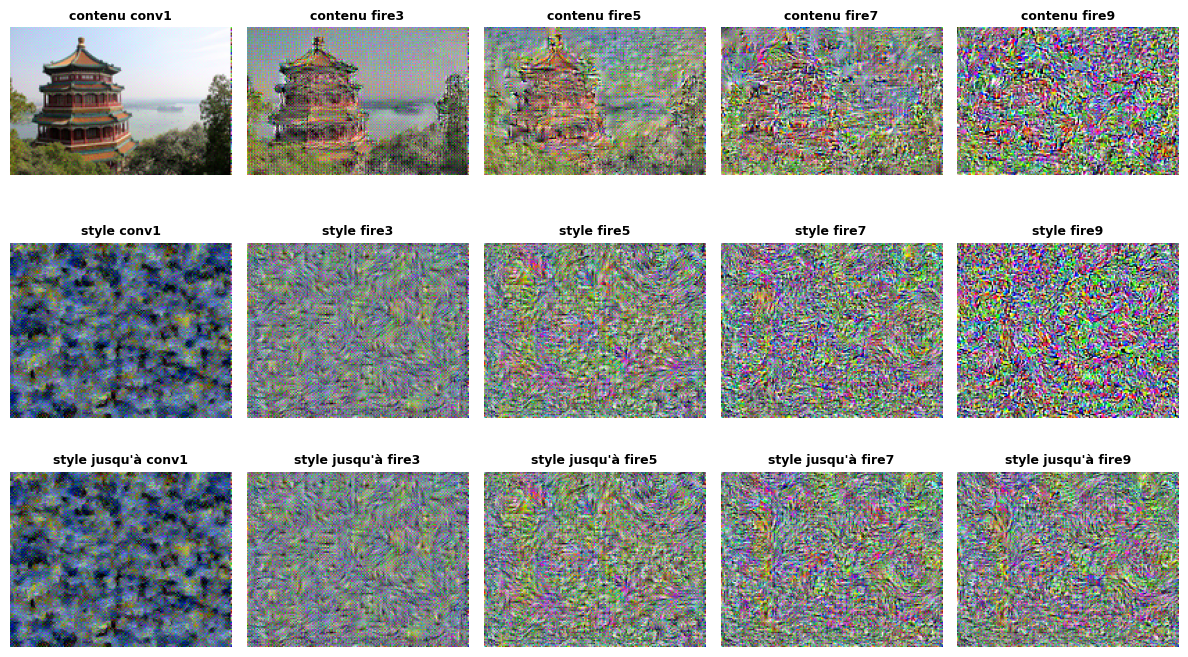

In [48]:
with checked("28.22"):
    names_22 = ["conv1", "fire3", "fire5", "fire7", "fire9"]
    steps_22 = 120 if FAST_MODE else 400
    t0_22 = time.perf_counter()
    content_rows_22 = [reconstruct_22(NET, CONTENT_C, [n], "content", steps_22) for n in names_22]
    style_rows_22 = [reconstruct_22(NET, STYLE_C, [n], "style", steps_22) for n in names_22]
    cumul_rows_22 = [reconstruct_22(NET, STYLE_C, names_22[:k + 1], "style", steps_22) for k in range(len(names_22))]
    print(f"15 reconstructions en {fr(time.perf_counter() - t0_22, 1)} s")
    show_images(content_rows_22 + style_rows_22 + cumul_rows_22,
                [f"contenu {n}" for n in names_22] + [f"style {n}" for n in names_22] + [f"style jusqu'à {n}" for n in names_22],
                cols=5, size=2.4)

### Ex 28.23 — Transfert de style complet sous budget CPU 📦 ★★★ ⏱️ 45 min 🚀
**Objectif :** écrire le transfert de style de Gatys en PyTorch, avec ses trois termes, et l'appliquer à trois tableaux du domaine public.  
**Prérequis :** Ex 28.18, 28.11 · ✏️ 28.4 · fiche §28.4.2 à §28.4.5 · **Parcours :** R, M, C

**Contrat** de `style_transfer_23(net, content, style, content_layers, style_layers, alpha, beta, tv, steps=150, lr=0.05, init="content", seed=0, every=1)` (la docstring de la cellule suivante le détaille) :
- les cibles sont calculées **une fois**, sans graphe : les activations du contenu aux `content_layers`, les matrices de Gram (`gram_matrix_18`) du style aux `style_layers` ; contenu et style peuvent avoir des tailles différentes ;
- départ : une copie du contenu (`init="content"`), ou le bruit `torch.rand(...)` de graine `seed` (`init="noise"`) ;
- à chaque pas : **une** passe de l'image par `extract_11` pour toutes les couches utiles ; $L_c$ = somme des `F.mse_loss` (des moyennes) ; $L_s$ = somme, sur les couches, des sommes des carrés des écarts de matrices de Gram ; $L_{TV}$ = `tv_loss_18` ; loss $= \alpha L_c + \beta L_s + \lambda L_{TV}$, un pas d'`Adam([x], lr)`, pixels ramenés dans $[0, 1]$ ;
- rend `(image, history)` : `history` = `{"content": [...], "style": [...], "tv": [...]}`, les trois termes **pondérés**, en `float`, enregistrés avant chaque pas dont l'indice est un multiple de `every`, et une fois de plus après le dernier pas.

La cellule de vérification fait un transfert de 12 pas sur de petites images : forme, plage, historique (13 valeurs par terme), loss qui baisse, poids intacts, couches de style additionnées, départ `"noise"` exact. La suivante applique trois styles à la photo (une dizaine de secondes). 🚀 En mode complet, des images de 256 pixels et 400 pas ; VGG16 et les couches du livre sont à ta portée (`VGG_LAYERS`).

Dans tes notes : compare les trois résultats. Qu'est-ce qui passe du tableau à la photo : la palette, les touches, les contours ? Quelle part du temps d'un pas prend la passe dans le réseau (🧮 28.6) ?

In [49]:
def style_transfer_23(net, content, style, content_layers, style_layers, alpha, beta, tv, steps=150, lr=0.05,
                      init="content", seed=0, every=1):
    """Gatys's style transfer with Adam on the pixels.

    content, style: (3, H, W) arrays in [0, 1] (of any sizes); the targets are computed once, without graph:
    the activations of content at content_layers, the Gram matrices (gram_matrix_18) of style at style_layers.
    Start: a copy of content (init="content") or torch.rand(1, 3, H, W, generator=torch.Generator().manual_seed(seed))
    (init="noise"). At each step: ONE pass of the image through extract_11 for all the needed layers,
      L_c = sum over content_layers of mean((A - A_c)**2)          (F.mse_loss, a MEAN)
      L_s = sum over style_layers of sum((G - G_s)**2)              (a SUM over the C x C entries)
      L_tv = tv_loss_18(x),
    loss = alpha * L_c + beta * L_s + tv * L_tv, a step of Adam([x], lr), the pixels clamped to [0, 1].
    Returns (image (3, H, W) float32 in [0, 1], history): history = {"content": [...], "style": [...], "tv": [...]},
    the three WEIGHTED terms (alpha * L_c...) as floats, recorded before each step whose index is a multiple of
    `every`, plus once more after the last step."""
    layers = {name: LAYERS[name] for name in set(content_layers) | set(style_layers)}
    c, s = to_batch(content), to_batch(style)
    with torch.no_grad():
        acts_c = extract_11(net, normalize(c), {n: LAYERS[n] for n in content_layers})
        acts_s = extract_11(net, normalize(s), {n: LAYERS[n] for n in style_layers})
        targets_c = {n: acts_c[n] for n in content_layers}
        targets_s = {n: gram_matrix_18(acts_s[n]) for n in style_layers}
    if init == "content":
        x = c.clone()
    else:
        x = torch.rand(c.shape, generator=torch.Generator().manual_seed(seed))
    x.requires_grad_(True)
    optimizer = torch.optim.Adam([x], lr=lr)
    history = {"content": [], "style": [], "tv": []}

    def terms(x):
        acts = extract_11(net, normalize(x), layers)
        l_c = sum(F.mse_loss(acts[n], targets_c[n]) for n in content_layers)
        l_s = sum(((gram_matrix_18(acts[n]) - targets_s[n]) ** 2).sum() for n in style_layers)
        return alpha * l_c, beta * l_s, tv * tv_loss_18(x)

    for step in range(steps + 1):
        t_c, t_s, t_tv = terms(x)
        if step % every == 0 or step == steps:
            for key, value in zip(("content", "style", "tv"), (t_c, t_s, t_tv)):
                history[key].append(float(value.detach()))
        if step == steps:
            break
        optimizer.zero_grad()
        (t_c + t_s + t_tv).backward()
        optimizer.step()
        with torch.no_grad():
            x.clamp_(0, 1)
    return to_image(x), history


with checked("28.23"):
    need("28.23", "extract_11", "gram_matrix_18", "tv_loss_18")
    small_c_23, small_s_23 = wb.datasets.load_sample_image("china", 48), wb.datasets.load_style_image("great_wave", 40)
    signature_23 = weights_signature(NET)
    passes_23 = []
    handle_23 = NET[0].register_forward_pre_hook(lambda m, inputs: passes_23.append(1))
    try:
        out_23 = style_transfer_23(NET, small_c_23, small_s_23, ["fire5"], ["conv1", "fire3"], 1.0, 10.0, 0.05, steps=12)
    finally:
        handle_23.remove()
    if not returned("28.23", "style_transfer_23", out_23):
        raise StopCheck
    img_23, hist_23 = out_23
    img_23 = np.asarray(img_23)
    verdict("28.23", img_23.shape == small_c_23.shape and img_23.dtype == np.float32 and 0 <= img_23.min() and img_23.max() <= 1,
            "une image float32 de la taille du contenu, dans [0, 1].", f"attendu float32 {small_c_23.shape} dans [0, 1], reçu {img_23.dtype} {img_23.shape}.")
    verdict("28.23", set(hist_23) == {"content", "style", "tv"} and all(len(v) == 13 for v in hist_23.values()),
            "un historique de 13 valeurs (12 pas, plus la fin) pour chacun des trois termes.",
            f"attendu les clés content, style, tv avec 13 valeurs, reçu { {k: len(v) for k, v in hist_23.items()} }.")
    verdict("28.23", hist_23["content"][0] == 0.0, "partir du contenu donne une loss de contenu nulle au départ.",
            f"le premier terme de contenu enregistré vaut {fr(hist_23['content'][0])} : pars d'une copie du contenu (init=\"content\") et enregistre AVANT le pas.")
    verdict("28.23", 15 <= len(passes_23) <= 17, f"{len(passes_23)} passes dans le réseau : les cibles, puis une par pas et une à la fin.",
            f"{len(passes_23)} passes dans le réseau, pour 12 pas : attendu 13 (une par pas, une à la fin), plus deux pour les cibles ; une seule passe par pas, pour toutes les couches.")
    total_23 = [sum(v) for v in zip(*hist_23.values())]
    verdict("28.23", total_23[-1] < 0.5 * total_23[0], f"la loss totale baisse ({fr(total_23[0], 1)} → {fr(total_23[-1], 1)}).",
            f"la loss totale baisse trop peu ({fr(total_23[0], 1)} → {fr(total_23[-1], 1)}) : une descente, sur les pixels ?")
    verdict("28.23", weights_signature(NET) == signature_23, "les poids du réseau n'ont pas bougé.", "les poids du réseau ont changé.")
    with torch.no_grad():
        def g_23(img, i):
            A = NET[:i + 1](normalize(to_batch(img)))[0].double()
            return torch.einsum("chw,dhw->cd", A, A) / A.numel()
        want_style_23 = 10.0 * float(sum(((g_23(small_c_23, i) - g_23(small_s_23, i)) ** 2).sum() for i in (LAYERS["conv1"], LAYERS["fire3"])))
        c_23 = to_batch(small_c_23)
        want_tv_23 = 0.05 * float(((c_23[..., 1:, :] - c_23[..., :-1, :]) ** 2).sum() + ((c_23[..., 1:] - c_23[..., :-1]) ** 2).sum())
    same("28.23", "premier terme de style enregistré (beta × somme sur conv1 et fire3)", hist_23["style"][0], want_style_23, rtol=1e-4)
    same("28.23", "premier terme de variation totale enregistré (tv × L_TV de la photo)", hist_23["tv"][0], want_tv_23, rtol=1e-4)
    _, hist_every_23 = style_transfer_23(NET, small_c_23, small_s_23, ["fire5"], ["conv1"], 1.0, 10.0, 0.05, steps=6, every=4)
    verdict("28.23", len(hist_every_23["style"]) == 3, "every=4 sur 6 pas : 3 valeurs (pas 0, pas 4, fin).",
            f"every=4 sur 6 pas : attendu 3 valeurs (pas 0, pas 4, fin), reçu {len(hist_every_23['style'])}.")
    noise_23, _ = style_transfer_23(NET, small_c_23, small_s_23, ["fire5"], ["conv1"], 1.0, 10.0, 0.0, steps=0, init="noise", seed=3)
    same("28.23", "départ init=\"noise\", seed=3, sans aucun pas", np.asarray(noise_23),
         to_image(torch.rand((1,) + small_c_23.shape, generator=torch.Generator().manual_seed(3))), rtol=1e-6, atol=1e-7)

✅ Ex 28.23 : une image float32 de la taille du contenu, dans [0, 1].
✅ Ex 28.23 : un historique de 13 valeurs (12 pas, plus la fin) pour chacun des trois termes.
✅ Ex 28.23 : partir du contenu donne une loss de contenu nulle au départ.
✅ Ex 28.23 : 15 passes dans le réseau : les cibles, puis une par pas et une à la fin.
✅ Ex 28.23 : la loss totale baisse (714,6 → 180,5).
✅ Ex 28.23 : les poids du réseau n'ont pas bougé.
✅ Ex 28.23 : premier terme de style enregistré (beta × somme sur conv1 et fire3) : 709.96466064, comme attendu.
✅ Ex 28.23 : premier terme de variation totale enregistré (tv × L_TV de la photo) : 4.63520288, comme attendu.
✅ Ex 28.23 : every=4 sur 6 pas : 3 valeurs (pas 0, pas 4, fin).
✅ Ex 28.23 : départ init="noise", seed=3, sans aucun pas : un tableau (3, 32, 48), comme attendu.


3 transferts de style en 7,1 s


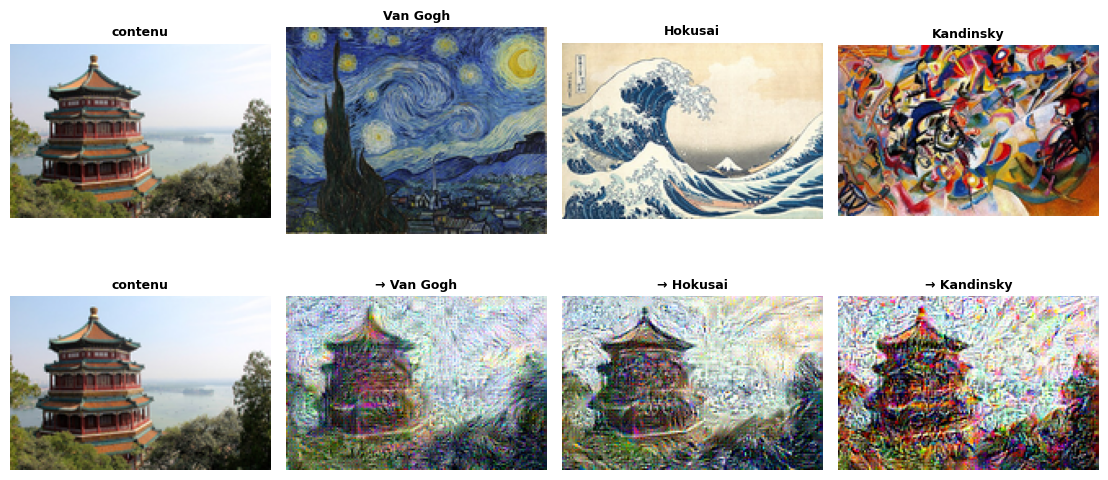

In [50]:
with checked("28.23"):
    t0_23 = time.perf_counter()
    styled_23 = {}
    for name in ("starry_night", "great_wave", "composition_vii"):
        styled_23[name], _ = style_transfer_23(NET, CONTENT_C, wb.datasets.load_style_image(name, SIZE), CONTENT_LAYERS,
                                               STYLE_LAYERS, ALPHA, BETA, TV, steps=STEPS_C)
    print(f"3 transferts de style en {fr(time.perf_counter() - t0_23, 1)} s")
    show_images([CONTENT_C] + [wb.datasets.load_style_image(n, SIZE) for n in styled_23] + [CONTENT_C] + list(styled_23.values()),
                ["contenu", "Van Gogh", "Hokusai", "Kandinsky", "contenu", "→ Van Gogh", "→ Hokusai", "→ Kandinsky"], cols=4, size=2.8)

### Ex 28.24 — Poids contenu/style, variation totale et image de départ 🔬 ★★★ ⏱️ 35 min 🚀
**Objectif :** explorer le compromis entre contenu et style, et l'effet de la variation totale et du point de départ, avec des mesures fixes.  
**Prérequis :** Ex 28.23 · fiche §28.4.5, §28.4.6 · **Parcours :** C

Pour comparer des réglages, il faut des **mesures qui ne changent pas avec eux** : `measure_24(img)` (cellule suivante) rend la distance de contenu (à la couche `fire6`) et la distance de style (matrices de Gram de `STYLE_LAYERS`) entre ton image et la photo, le tableau, sans pondération.

Écris dans `settings_24` au moins quatre réglages (des dictionnaires d'arguments de `style_transfer_23`, par exemple `{"beta": 100.0}` ou `{"init": "noise"}`) ; les autres arguments prennent les valeurs de la partie C. La cellule de vérification les fait tourner (≈ 4 s chacun en mode rapide) et affiche, pour chacun, les deux distances et la part de hautes fréquences.

Dans tes notes : trace (même à la main) la distance de style en fonction de la distance de contenu pour tes réglages de $\beta$ : une frontière se dessine-t-elle ? Que change $\lambda = 0$ ? Partir du bruit : meilleure ou pire distance de style, à nombre de pas égal ? Pourquoi « $\beta / \alpha = 40$ » du livre ne se transpose-t-il pas ici (Q9) ?

In [51]:
def measure_24(img, content=None, style=None):
    """Two fixed yardsticks for comparing settings (not the losses that were optimised): the content distance (mean
    squared difference of the fire6 activations) to `content` and the style distance (sum over STYLE_LAYERS of the
    squared differences of the normalised Gram matrices) to `style`, as Python floats."""
    content = CONTENT_C if content is None else content
    style = STYLE_C if style is None else style
    with torch.no_grad():
        def acts(image):
            out, h = {}, normalize(to_batch(image))
            for i, module in enumerate(NET[:LAYERS["fire6"] + 1]):
                h = module(h)
                out[i] = h
            return out
        def gram(A):
            flat = A.reshape(A.shape[1], -1)
            return flat @ flat.T / flat.numel()
        a, c, s = acts(img), acts(content), acts(style)
        d_c = float(((a[LAYERS["fire6"]] - c[LAYERS["fire6"]]) ** 2).mean())
        d_s = float(sum(((gram(a[LAYERS[n]]) - gram(s[LAYERS[n]])) ** 2).sum() for n in STYLE_LAYERS))
    return d_c, d_s

✅ Ex 28.24 : 6 réglages à comparer.


6 transferts en 14,5 s
repère : la photo elle-même a une distance de style de 9773,0
{'beta': 1.0}                                 contenu    271,2   style     236,8   hautes fréquences 6 %
{'beta': 10.0}                                contenu    632,5   style      66,2   hautes fréquences 9 %
{'beta': 100.0}                               contenu    859,5   style      56,3   hautes fréquences 10 %
{'beta': 10.0, 'tv': 0.0}                     contenu    631,3   style      71,8   hautes fréquences 10 %
{'beta': 10.0, 'init': 'noise'}               contenu    920,9   style     168,9   hautes fréquences 58 %
{'beta': 100.0, 'init': 'noise'}              contenu   1083,4   style     166,8   hautes fréquences 58 %


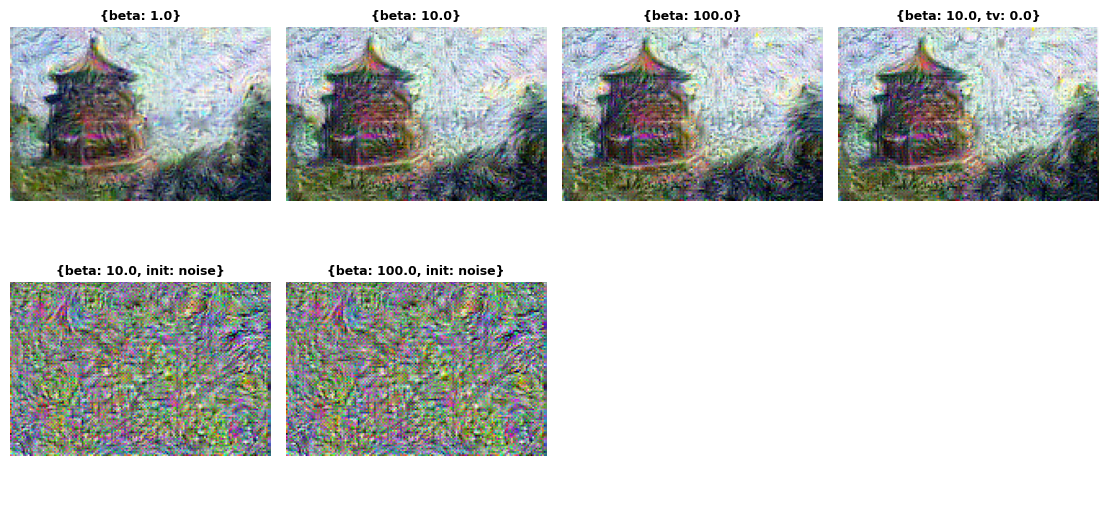

In [52]:
settings_24 = [{"beta": 1.0}, {"beta": 10.0}, {"beta": 100.0}, {"beta": 10.0, "tv": 0.0},
               {"beta": 10.0, "init": "noise"}, {"beta": 100.0, "init": "noise"}]


with checked("28.24"):
    need("28.24", "style_transfer_23")
    if not filled(settings_24):
        print("⏳ Ex 28.24 : écris tes réglages dans la cellule précédente.")
        raise StopCheck
    verdict("28.24", isinstance(settings_24, (list, tuple)) and len(settings_24) >= 4, f"{len(settings_24)} réglages à comparer.",
            "au moins quatre réglages, dans une liste de dictionnaires.")
    rows_24, images_24 = [], []
    t0_24 = time.perf_counter()
    for setting in settings_24:
        kw = {"alpha": ALPHA, "beta": BETA, "tv": TV, "steps": STEPS_C, "init": "content"}
        kw.update(setting)
        img, hist = style_transfer_23(NET, CONTENT_C, STYLE_C, CONTENT_LAYERS, STYLE_LAYERS, **kw)
        d_c, d_s = measure_24(img)
        rows_24.append((setting, d_c, d_s, high_freq_share(img)))
        images_24.append(img)
    print(f"{len(settings_24)} transferts en {fr(time.perf_counter() - t0_24, 1)} s")
    d_s0_24 = measure_24(CONTENT_C)[1]
    print(f"repère : la photo elle-même a une distance de style de {fr(d_s0_24, 1)}")
    for setting, d_c, d_s, hf in rows_24:
        print(f"{str(setting):45s} contenu {fr(d_c, 1):>8s}   style {fr(d_s, 1):>9s}   hautes fréquences {pct(hf, 0)}")
    show_images(images_24, [str(s).replace("'", "")[:28] for s in settings_24], cols=min(4, len(images_24)), size=2.8)

### Ex 28.25 — Au-delà de Gram : moyennes et écarts-types des canaux 🔬 ★★★ ⏱️ 40 min
**Objectif :** remplacer la matrice de Gram par les moyennes et les écarts-types des canaux (l'idée d'AdaIN) et comparer les résultats.  
**Prérequis :** Ex 28.23 · ∂ 28.3 (5 et 6) · fiche §28.4.6 (encadrés) · **Parcours :** M, C

∂ 28.3 a montré que la matrice de Gram mêle moyenne et écart-type de chaque canal ($C\,G_{ii} = \mu_i^2 + \sigma_i^2$) et y ajoute les co-activations. Huang et Belongie (AdaIN, 2017) n'utilisent **que** les moyennes et les écarts-types des canaux.

**Contrat**
- `channel_stats_25(A)` : pour des activations `(N, C, H, W)`, deux tenseurs `(N, C)` : la moyenne de chaque canal sur les $H \times W$ positions, et $\sqrt{\text{variance} + 10^{-5}}$, la variance de population (`unbiased=False`) ;
- `stats_loss_25(A, target_mean, target_std)` : la somme des carrés des écarts entre les moyennes de `A` et `target_mean`, plus celle des écarts entre les écarts-types et `target_std`.

La cellule de vérification compare tes deux fonctions à NumPy. La suivante fait deux transferts avec la même boucle (`transfer_25`, fournie : elle utilise ton `extract_11` et ton `tv_loss_18`), l'un avec la loss de Gram, l'autre avec ta loss de statistiques, et les mesure par `measure_24`.

Dans tes notes : les deux images se ressemblent-elles ? La loss de statistiques fait-elle baisser la distance de style **mesurée par Gram** ? Qu'est-ce que la matrice de Gram contient de plus (pense aux coefficients hors de la diagonale) ? Pourquoi AdaIN peut-il alors appliquer un style en une seule passe ?

In [53]:
def channel_stats_25(A):
    """(mean, std) of each channel of activations A (N, C, H, W) over the H x W positions: two tensors (N, C), with
    std = sqrt(var + 1e-5), var the population variance (unbiased=False)."""
    flat = A.reshape(A.shape[0], A.shape[1], -1)
    return flat.mean(dim=2), torch.sqrt(flat.var(dim=2, unbiased=False) + 1e-5)


def stats_loss_25(A, target_mean, target_std):
    """The AdaIN-style statistics loss: sum of the squared differences between the channel means of A and target_mean,
    plus those between the channel standard deviations and target_std (sums over the N x C entries)."""
    mean, std = channel_stats_25(A)
    return ((mean - target_mean) ** 2).sum() + ((std - target_std) ** 2).sum()


with checked("28.25"):
    A_25 = torch.tensor(np.random.default_rng(25).random((2, 3, 4, 5)))
    stats_25 = channel_stats_25(A_25)
    if not returned("28.25", "channel_stats_25", stats_25):
        raise StopCheck
    flat_25 = A_25.numpy().reshape(2, 3, -1)
    same("28.25", "channel_stats_25 : moyennes", stats_25[0], flat_25.mean(axis=2))
    same("28.25", "channel_stats_25 : écarts-types", stats_25[1], np.sqrt(flat_25.var(axis=2) + 1e-5))
    same("28.25", "stats_loss_25 contre la cible (0, 1)", float(stats_loss_25(A_25, torch.zeros(2, 3), torch.ones(2, 3))),
         float((flat_25.mean(axis=2) ** 2).sum() + ((np.sqrt(flat_25.var(axis=2) + 1e-5) - 1) ** 2).sum()))

✅ Ex 28.25 : channel_stats_25 : moyennes : [[0.43281442, 0.42577655, 0.47224947], [0.53421961, 0.40268175, 0.58602442]], comme attendu.
✅ Ex 28.25 : channel_stats_25 : écarts-types : [[0.30666907, 0.26471511, 0.29433538], [0.27396692, 0.27588589, 0.25566766]], comme attendu.
✅ Ex 28.25 : stats_loss_25 contre la cible (0, 1) : 4.50741146, comme attendu.


In [54]:
def transfer_25(style_term, beta, steps=STEPS_C, lr=0.05):
    """The style transfer of 28.23 (from the photo, your extract_11 and tv_loss_18), with a style term of your choice:
    style_term(acts_x, acts_s) -> a 0-d tensor, acts_x and acts_s the dicts of activations at STYLE_LAYERS."""
    layers = {n: LAYERS[n] for n in set(CONTENT_LAYERS) | set(STYLE_LAYERS)}
    c = to_batch(CONTENT_C)
    with torch.no_grad():
        acts_c = extract_11(NET, normalize(c), layers)
        acts_s = extract_11(NET, normalize(to_batch(STYLE_C)), {n: LAYERS[n] for n in STYLE_LAYERS})
    x = c.clone().requires_grad_(True)
    optimizer = torch.optim.Adam([x], lr=lr)
    for _ in range(steps):
        acts = extract_11(NET, normalize(x), layers)
        loss = (ALPHA * sum(F.mse_loss(acts[n], acts_c[n]) for n in CONTENT_LAYERS)
                + beta * style_term({n: acts[n] for n in STYLE_LAYERS}, acts_s) + TV * tv_loss_18(x))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            x.clamp_(0, 1)
    return to_image(x)

repère : la photo a une distance de style (Gram) de 9773,0
                     Gram : 2,7 s, distance de contenu 632,5, distance de style (Gram) 66,2
 moyennes et écarts-types : 2,6 s, distance de contenu 296,8, distance de style (Gram) 307,2


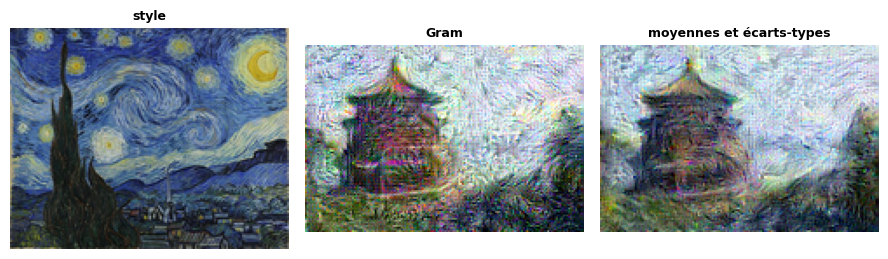

In [55]:
with checked("28.25"):
    need("28.25", "extract_11", "gram_matrix_18", "tv_loss_18")
    def gram_term_25(acts_x, acts_s):
        return sum(((gram_matrix_18(acts_x[n]) - gram_matrix_18(acts_s[n])) ** 2).sum() for n in acts_x)
    def stats_term_25(acts_x, acts_s):
        return sum(stats_loss_25(acts_x[n], *channel_stats_25(acts_s[n])) for n in acts_x)
    results_25 = {}
    for name, term, beta in (("Gram", gram_term_25, BETA), ("moyennes et écarts-types", stats_term_25, 1.0)):
        t0 = time.perf_counter()
        img = transfer_25(term, beta)
        results_25[name] = (img, time.perf_counter() - t0) + measure_24(img)
    print(f"repère : la photo a une distance de style (Gram) de {fr(measure_24(CONTENT_C)[1], 1)}")
    for name, (img, seconds, d_c, d_s) in results_25.items():
        print(f"{name:>25s} : {fr(seconds, 1)} s, distance de contenu {fr(d_c, 1)}, distance de style (Gram) {fr(d_s, 1)}")
    show_images([STYLE_C] + [r[0] for r in results_25.values()], ["style"] + list(results_25), size=3)

### Ex 28.26 — Crédits, licences et paramètres : documenter une galerie générée 🛠️ ★★★ ⏱️ 30 min
**Objectif :** publier une galerie d'images générées qu'un autre peut refaire et réutiliser légalement : crédits, licences, réglages, versions.  
**Prérequis :** Ex 28.23 · ⚖️ 28.9 · fiche (encadré ⚠️ du §28.4.5 et 🕰️ sur le droit d'auteur) · **Parcours :** C

Une image générée hérite de questions : d'où viennent la photo et le tableau ? sous quelle licence ? comment la refaire ? **Contrat** de `write_gallery_26(folder, entries)` : la docstring de la cellule suivante. Pour chaque entrée, un PNG (`plt.imsave`) et, dans un `README.md` : le nom du fichier (une image Markdown), les lignes de crédit de la photo et du tableau (`wb.datasets.image_credit`), chaque réglage de `params` sous la forme `clé: valeur` ; puis, une fois, le réseau et ses poids (« SqueezeNet 1.1, IMAGENET1K_V1 »), les versions de torch et de torchvision, la date (AAAA-MM-JJ), et une phrase qui dit que les images sont **générées**.

La cellule de vérification fait deux petits transferts, appelle ta fonction et passe le dossier à `validate_gallery_26`, qui liste ce qui manque (et refuse toute œuvre encore protégée).

Dans tes notes : quelle licence choisirais-tu pour tes images, sachant que la photo est sous CC BY 2.0 ? Que faudrait-il ajouter pour publier la galerie dans l'Union européenne (transparence, ⚖️ 28.9) ?

In [56]:
def validate_gallery_26(folder, entries):
    """Check a gallery written by write_gallery_26: files, credits, settings, reproducibility, no protected work."""
    folder = Path(folder)
    readme = (folder / "README.md").read_text(encoding="utf-8") if (folder / "README.md").exists() else ""
    problems = []
    if not readme:
        problems.append("pas de README.md")
    for entry in entries:
        if not (folder / entry["file"]).exists():
            problems.append(f"{entry['file']} absent du dossier")
        if entry["file"] not in readme:
            problems.append(f"{entry['file']} n'est pas cité dans le README")
        for name in (entry["content"], entry["style"]):
            if wb.datasets.image_credit(name) not in readme:
                problems.append(f"le crédit de {name!r} manque (wb.datasets.image_credit)")
        for key, value in entry["params"].items():
            if f"{key}: {value}" not in readme:
                problems.append(f"le réglage « {key}: {value} » manque")
    for word, why in (("SqueezeNet", "le réseau"), ("IMAGENET1K_V1", "les poids"), ("torchvision", "les versions"),
                      ("généré", "la mention « images générées »")):
        if word.lower() not in readme.lower():
            problems.append(f"{why} : « {word} » n'apparaît pas")
    if not re.search(r"20\d\d-\d\d-\d\d", readme):
        problems.append("pas de date au format AAAA-MM-JJ")
    for artist in ("Picasso", "Hopper"):
        if artist in readme:
            problems.append(f"{artist} : une œuvre encore protégée dans l'Union européenne")
    return problems

In [57]:
def write_gallery_26(folder, entries):
    """Write a reproducible gallery into `folder` (a Path): one PNG per entry and a README.md.

    entries: a list of dicts {"file": "name.png", "image": (3, H, W) in [0, 1], "content": name of a photo,
    "style": name of a painting, "params": dict of the settings}. The README gives, for each image: its file name (as
    a Markdown image), the credit lines of its photo and of its painting (wb.datasets.image_credit), and every setting
    of its "params" as "key: value"; then, once, the network and its weights ("SqueezeNet 1.1, IMAGENET1K_V1"), the
    versions of torch and torchvision, the date, and a sentence that says the images are generated."""
    import datetime

    import torchvision
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    lines = ["# Galerie de transferts de style", "",
             "Images **générées** par transfert de style neuronal (L. Gatys et coll., 2015) : ce ne sont ni des photos ni "
             "des œuvres des artistes cités.", ""]
    for entry in entries:
        plt.imsave(folder / entry["file"], np.clip(np.asarray(entry["image"]).transpose(1, 2, 0), 0, 1))
        lines += [f"## {entry['file']}", "", f"![{entry['file']}]({entry['file']})", "",
                  f"- Contenu : {wb.datasets.image_credit(entry['content'])}",
                  f"- Style : {wb.datasets.image_credit(entry['style'])}",
                  "- Réglages : " + ", ".join(f"{k}: {v}" for k, v in entry["params"].items()), ""]
    lines += ["## Reproduire", "", "- Réseau : SqueezeNet 1.1, poids IMAGENET1K_V1 (torchvision), gelé",
              f"- Versions : torch {torch.__version__}, torchvision {torchvision.__version__}",
              f"- Date : {datetime.date.today().isoformat()}", ""]
    (folder / "README.md").write_text("\n".join(lines), encoding="utf-8")


with checked("28.26"):
    need("28.26", "style_transfer_23")
    entries_26 = []
    for style_name in ("starry_night", "great_wave"):
        params = {"content_layers": CONTENT_LAYERS, "style_layers": STYLE_LAYERS, "alpha": ALPHA, "beta": BETA, "tv": TV,
                  "steps": 60, "lr": 0.05, "init": "content", "size": 96}
        img, _ = style_transfer_23(NET, wb.datasets.load_sample_image("flower", 96), wb.datasets.load_style_image(style_name, 96),
                                   CONTENT_LAYERS, STYLE_LAYERS, ALPHA, BETA, TV, steps=60)
        entries_26.append({"file": f"fleur_{style_name}.png", "image": img, "content": "flower", "style": style_name,
                           "params": params})
    folder_26 = WORK_DIR / "galerie"
    out_26 = write_gallery_26(folder_26, entries_26)
    problems_26 = validate_gallery_26(folder_26, entries_26)
    verdict("28.26", not problems_26, f"la galerie est complète ({folder_26}).", " ; ".join(problems_26[:4]))
    if not problems_26:
        print((folder_26 / "README.md").read_text(encoding="utf-8")[:1500])

✅ Ex 28.26 : la galerie est complète (/tmp/wb_ch28_wl5qn3zg/galerie).
# Galerie de transferts de style

Images **générées** par transfert de style neuronal (L. Gatys et coll., 2015) : ce ne sont ni des photos ni des œuvres des artistes cités.

## fleur_starry_night.png

![fleur_starry_night.png](fleur_starry_night.png)

- Contenu : Fleur (photo), vultilion (Flickr ; le README de scikit-learn crédite danielbuechele), https://www.flickr.com/photos/vultilion/6056698931/, licence CC BY 2.0 (https://creativecommons.org/licenses/by/2.0/)
- Style : Vincent van Gogh, « La Nuit étoilée » (1889), Museum of Modern Art, New York ; reproduction : https://upload.wikimedia.org/wikipedia/commons/thumb/e/ea/Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg/500px-Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg ; domaine public (l'artiste est mort en 1890 : plus de 70 ans) ; reproduction fidèle non protégée (directive (UE) 2019/790, art. 14)
- Réglages : content_layers: ['fire6'], style_layers: ['conv1',

## Partie D · Le texte mot à mot sur Verne, et le défi

Le livre termine par un LSTM qui écrit la suite du livre, mot à mot, à partir du mot le plus probable. Tu reprends ton code de 24.30 (Holmes) sur *Le Tour du monde en quatre-vingts jours*, avec le modèle du livre (deux couches de LSTM de 128 cellules), puis tu compares les stratégies de décodage. Le défi, enfin, revient au transfert de style.

In [58]:
VERNE = wb.datasets.load_verne().replace("_", "").replace("--", "—")   # without the italics marks, real dashes
EPOCHS_27 = 12 if FAST_MODE else 40
torch.set_num_threads(max(1, min(4, torch.get_num_threads())))


def build_vocab(*args, **kwargs):           # your chapter 22 library (mylearn.sequences), called through these names
    return mylearn.sequences.build_vocab(*args, **kwargs)


def encode(*args, **kwargs):
    return mylearn.sequences.encode(*args, **kwargs)


def decode_words(ids, itos):
    """Ids -> text: tokens joined by spaces, no space before , . ; : ! ? ) or after an apostrophe or ( ."""
    text = " ".join(itos[i] for i in ids)
    return re.sub(r"\s+([,.;:!?)»])|([’'(«])\s+", lambda m: m.group(1) or m.group(2), text)


def make_sequence_pairs(*args, **kwargs):
    return mylearn.sequences.make_sequence_pairs(*args, **kwargs)


def sample_from_logits(*args, **kwargs):
    return mylearn.sequences.sample_from_logits(*args, **kwargs)


def make_loader(X, Y, batch_size, seed):
    """Shuffled mini-batches of (X, Y), the same order for the same seed."""
    return torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, Y), batch_size=batch_size, shuffle=True,
                                       generator=torch.Generator().manual_seed(seed))


class WordLM2(nn.Module):
    """The book's model (§28.5): an embedding, TWO layers of LSTM of 128 cells, one shared Linear at every step;
    ids (N, T) -> (logits (N, T, V), state)."""

    def __init__(self, vocab_size, emb_dim=64, hidden=128, layers=2):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=layers, batch_first=True)
        self.head = nn.Linear(hidden, vocab_size)

    def forward(self, ids, state=None):
        output, state = self.lstm(self.emb(ids), state)
        return self.head(output), state


print(f"Verne : {len(VERNE)} caractères")

Verne : 420083 caractères


### Ex 28.27 — Plus de Verne : réutiliser le code du LSTM mot à mot de 24.30 sur Verne et l'entraîner plus longtemps, du charabia aux phrases 📦 ★★★ ⏱️ 45 min 🚀
**Objectif :** adapter un générateur de texte mot à mot au français et suivre ce qu'il écrit au fil des epochs.  
**Prérequis :** ch. 22 (`mylearn.sequences`) · Ex 24.30 · fiche §28.5 · **Fil rouge :** Verne · **Parcours :** C

Recopie tes fonctions de 24.30 en les renommant `_27`, puis adapte-les. **Contrat** (les docstrings de la cellule suivante) :
- `tokenize_words_27(text)` : le texte en minuscules ; les mots sont des suites de **lettres de tout alphabet** (la classe `[^\W\d_]` du module `re`, qui inclut é, à, ç…), une apostrophe `'` ou `’` qui suit des lettres leur reste collée (`"l'"`, `"qu'"`, `"aujourd'"`) ; tout autre caractère qui n'est pas une espace forme un token (ponctuation, chiffres un par un). L'expression de 24.30, limitée aux lettres de a à z, couperait « été » en trois tokens ;
- `make_vocab_27`, `split_pairs_27` (la validation est la **fin** du roman), `train_lm_27` (comme `train_lm_30`, plus un rappel `on_epoch(epoch, model)` après chaque epoch) et `mean_loss_27` : comme en 24.30.

Le modèle est fourni : `WordLM2`, un embedding de 64, **deux** couches de LSTM de 128 cellules, une couche dense vers le vocabulaire (le modèle du livre). Vocabulaire : les 5 000 mots les plus fréquents et `<unk>`.

La cellule de vérification essaie ton tokenizer sur une phrase piégée, construit le vocabulaire et les paires, puis te fait reporter : a) le nombre de tokens de Verne ; b) la part de `<unk>` dans le texte encodé. La suivante entraîne `MODEL_27` (`EPOCHS_27` epochs, 12 en mode rapide, ≈ 4 s chacune, learning rate 0,01) et affiche la perplexité de validation après chaque epoch et trois extraits générés (température 0,8), après la première, la moitié et la dernière epoch. 🚀 En mode complet, 40 epochs.

Dans tes notes : compare les trois extraits (le livre parle de « charabia » puis de phrases presque sensées). La perplexité de validation remonte-t-elle à la fin (overfitting, 🧮 28.7) ? Quels mots les conjugaisons et les accords du français ajoutent-ils au vocabulaire, par rapport à l'anglais de Holmes ?

In [59]:
# Copy here your functions of 24.30 (renamed _27), then adapt the tokenizer to French.
WORD_RE_27 = re.compile(r"[^\W\d_]+['’]?|\S")


def tokenize_words_27(text):
    """The text in lower case, cut into tokens: words = runs of LETTERS of any alphabet (accented letters included:
    the regex class [^\\W\\d_]), an apostrophe ' or ’ that follows letters staying glued to them ("l'",
    "qu'", "aujourd'"), and one token for every other character that is not a space (punctuation, digits)."""
    return WORD_RE_27.findall(text.lower())


def make_vocab_27(tokens, max_size):
    """(stoi, itos): build_vocab with the unknown token "<unk>" (id 0), at most max_size entries."""
    return build_vocab(tokens, max_size=max_size, unk_token="<unk>")


def split_pairs_27(ids, seq_len, val_share=0.1):
    """(X_tr, Y_tr, X_val, Y_val), int64 tensors: the last int(len(ids) * val_share) ids for the validation (the END
    of the novel), the others for the training, each part cut by make_sequence_pairs(part, seq_len)."""
    ids = np.asarray(ids)
    n_val = int(len(ids) * val_share)
    out = []
    for part in (ids[:len(ids) - n_val], ids[len(ids) - n_val:]):
        X, Y = make_sequence_pairs(part, seq_len)
        out += [torch.as_tensor(X, dtype=torch.int64), torch.as_tensor(Y, dtype=torch.int64)]
    return tuple(out)


def train_lm_27(model, X, Y, epochs, batch_size=64, lr=3e-3, seed=0, on_epoch=None):
    """Train `model` on (X, Y) as train_lm_30: Adam(lr), make_loader(X, Y, batch_size, seed), cross-entropy over every
    position, gradients clipped to a norm of 1; after each epoch, call on_epoch(epoch, model) if given (epoch from 1).
    Return the mean training loss per token of each epoch (a list of floats)."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_loader(X, Y, batch_size, seed)
    losses = []
    for epoch in range(1, epochs + 1):
        model.train()
        total, count = 0.0, 0
        for xb, yb in loader:
            logits, _ = model(xb)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), yb.reshape(-1))
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * yb.numel()
            count += yb.numel()
        losses.append(total / count)
        if on_epoch is not None:
            on_epoch(epoch, model)
    return losses


def mean_loss_27(model, X, Y, batch_size=256):
    """The mean cross-entropy per token of `model` on (X, Y), in nats (eval mode, no graph), a Python float."""
    model.eval()
    total = 0.0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            logits, _ = model(X[i:i + batch_size])
            total += F.cross_entropy(logits.reshape(-1, logits.shape[-1]), Y[i:i + batch_size].reshape(-1),
                                     reduction="sum").item()
    return total / Y.numel()


with checked("28.27"):
    toks_27 = tokenize_words_27("L'été, Phileas Fogg — aujourd'hui à 8 h 45 — dit : « Partons ! »")
    if not returned("28.27", "tokenize_words_27", toks_27):
        raise StopCheck
    want_27 = ["l'", "été", ",", "phileas", "fogg", "—", "aujourd'", "hui", "à", "8", "h", "4", "5", "—", "dit", ":", "«",
               "partons", "!", "»"]
    verdict("28.27", list(toks_27) == want_27, "le tokenizer garde les lettres accentuées et colle l'apostrophe au mot.",
            f"attendu {want_27}, reçu {list(toks_27)}.")
    stoi_27, itos_27 = make_vocab_27(tokenize_words_27(VERNE), 5001)
    verdict("28.27", len(itos_27) == 5001 and itos_27[0] == "<unk>", "5 001 entrées, « <unk> » à l'id 0.",
            f"attendu 5 001 entrées et « <unk> » à l'id 0, reçu {len(itos_27)} entrées, la première {itos_27[0]!r}.")
    ids_27 = encode(tokenize_words_27(VERNE), stoi_27, unk_token="<unk>")
    X_tr_27, Y_tr_27, X_val_27, Y_val_27 = split_pairs_27(ids_27, 32)
    n_val_27 = int(len(ids_27) * 0.1)
    verdict("28.27", X_val_27.dtype == torch.int64 and bool((Y_tr_27[:, :-1] == X_tr_27[:, 1:]).all())
            and len(X_val_27) == (n_val_27 - 1) // 32
            and bool((X_val_27[0] == torch.as_tensor(np.asarray(ids_27)[len(ids_27) - n_val_27:][:32])).all()),
            "paires décalées d'un pas, validation prise à la fin du roman.", "les paires ou la séparation ne suivent pas la docstring.")
    wb.check("28.27a", len(tokenize_words_27(VERNE)), computed=True)
    wb.check("28.27b", float(np.mean(np.asarray(ids_27) == 0)), computed=True)

✅ Ex 28.27 : le tokenizer garde les lettres accentuées et colle l'apostrophe au mot.
✅ Ex 28.27 : 5 001 entrées, « <unk> » à l'id 0.
✅ Ex 28.27 : paires décalées d'un pas, validation prise à la fin du roman.
✅ Ex 28.27a : Parfait !
✅ Ex 28.27b : Bravo !


In [60]:
ascii_27 = len(re.findall(r"[a-z]+(?:['’][a-z]+)*|[^\sa-z]", VERNE.lower()))   # the tokenizer of 24.30
wb.record("28.27a", len(tokenize_words_27(VERNE)),
          mistakes={"ton tokenizer coupe-t-il les mots accentués ? Les lettres de tout alphabet : [^\\W\\d_]": ascii_27})
wb.record("28.27b", float(np.mean(np.asarray(ids_27) == 0)), decimals=4)

WB_ANSWER {"hash": "ff1463be380f4285d6b4dc19788c9b2ff9d29a430e8a970ffb90a21c2dc22077", "id": "28.27a", "kind": "int", "magnitude": 4, "mistakes": {"0fbd5de4a7a142c344817e0c8108a0012e834ca963279c1d35bf7e3841b37ba5": "ton tokenizer coupe-t-il les mots accentués ? Les lettres de tout alphabet : [^\\W\\d_]"}, "sign": 1}
📝 Ex 28.27a : réponse enregistrée (int).
WB_ANSWER {"decimals": 4, "hash": "e807ed63b08d0da3f2bce012b22528cb9e734cdb7905aa0286f07b31489f76e7", "hash_coarse": "a4ccd4ec5501232d195b192c926514a93cf5521994c9ab931ec7caf55811d658", "id": "28.27b", "kind": "float", "magnitude": -2, "sign": 1}
📝 Ex 28.27b : réponse enregistrée (float, 4 décimale(s)).


In [61]:
with checked("28.27"):
    if "itos_27" not in globals() or "X_val_27" not in globals():
        print("⏳ Ex 28.27 : fais d'abord passer la cellule de vérification précédente (tokenizer, vocabulaire, paires).")
        raise StopCheck
    torch.manual_seed(27)
    MODEL_27 = WordLM2(len(itos_27))
    prompt_27 = encode(tokenize_words_27("Phileas Fogg"), stoi_27, unk_token="<unk>")
    samples_27, val_27 = {}, []

    def on_epoch_27(epoch, model):
        val_27.append(mean_loss_27(model, X_val_27, Y_val_27))
        if epoch in (1, EPOCHS_27 // 2, EPOCHS_27):
            rng = np.random.default_rng(0)
            model.eval()
            with torch.inference_mode():
                logits, state = model(torch.as_tensor(np.asarray(prompt_27, dtype=np.int64)[None]))
                out = []
                for _ in range(40):
                    nxt = int(sample_from_logits(logits[0, -1].numpy(), temperature=0.8, rng=rng))
                    out.append(nxt)
                    logits, state = model(torch.tensor([[nxt]]), state)
            samples_27[epoch] = decode_words(list(prompt_27) + out, itos_27)

    t0_27 = time.perf_counter()
    train_27 = train_lm_27(MODEL_27, X_tr_27, Y_tr_27, EPOCHS_27, lr=1e-2, on_epoch=on_epoch_27)
    print(f"{EPOCHS_27} epochs en {fr(time.perf_counter() - t0_27, 1)} s")
    for epoch, (tr, va) in enumerate(zip(train_27, val_27), start=1):
        print(f"epoch {epoch:2d} : loss {fr(tr, 3)}, perplexité de validation {fr(math.exp(va), 1)}")
    print(f"repère : un modèle uniforme sur 5 001 mots a une perplexité de 5 001")
    for epoch, text in samples_27.items():
        print(f"\n— après {epoch} epoch(s), T = 0,8 :\n{text}")
    verdict("28.27", math.exp(val_27[-1]) < 500, f"la perplexité de validation tombe à {fr(math.exp(val_27[-1]), 1)}.",
            f"la perplexité de validation reste à {fr(math.exp(val_27[-1]), 1)} : l'entraînement a-t-il lieu ?")

12 epochs en 39,9 s
epoch  1 : loss 6,483, perplexité de validation 439,4
epoch  2 : loss 5,952, perplexité de validation 334,9
epoch  3 : loss 5,632, perplexité de validation 245,7
epoch  4 : loss 5,396, perplexité de validation 212,8
epoch  5 : loss 5,215, perplexité de validation 182,0
epoch  6 : loss 5,028, perplexité de validation 165,8
epoch  7 : loss 4,842, perplexité de validation 144,0
epoch  8 : loss 4,641, perplexité de validation 131,0
epoch  9 : loss 4,447, perplexité de validation 121,9
epoch 10 : loss 4,278, perplexité de validation 116,2
epoch 11 : loss 4,128, perplexité de validation 112,9
epoch 12 : loss 3,986, perplexité de validation 113,5
repère : un modèle uniforme sur 5 001 mots a une perplexité de 5 001

— après 1 epoch(s), T = 0,8 :
phileas fogg des. <unk> <unk> phileas prendre des plus — évidemment avec <unk> dit <unk> s', quelques en. à <unk>, une était fogg le rendrait malacca qu'des mais le, s'les de les coups indien de

— après 6 epoch(s), T = 0,8 :
philea

### Ex 28.28 — Glouton, température, top-k ou top-p : répétitions et diversité 🔬 ★★★ ⏱️ 30 min
**Objectif :** écrire les quatre stratégies de décodage et mesurer leurs effets sur les répétitions et la diversité du texte généré.  
**Prérequis :** Ex 28.27 · ch. 22 (`sample_from_logits`) · fiche §28.5 (encadré 🧮) · **Fil rouge :** Verne · **Parcours :** C

**Contrat**
- `pick_28(logits, strategy, rng, temperature=1.0, k=None, p=None)` : un identifiant (un `int` Python) tiré des logits `(V,)` du mot suivant : `"greedy"` (l'argmax, sans hasard), `"temperature"` (un tirage selon la softmax de `logits / temperature`), `"top_k"` (un tirage parmi les `k` plus grands logits seulement, probabilités renormalisées), `"top_p"` (un tirage parmi le plus petit ensemble des mots les plus probables dont la probabilité cumulée atteint `p`, renormalisé) ; un seul `rng.choice(ids, p=probs)` par tirage ;
- `repeated_share_28(ids, n=3)` : la part des n-grammes de `ids` qui sont déjà apparus plus tôt dans `ids` (0 s'il n'y en a pas).

La cellule de vérification contrôle les cas limites (glouton, top-k avec $k = 1$, top-p avec un petit $p$) et les fréquences de 6 000 tirages contre les probabilités attendues. La suivante génère, avec ton `MODEL_27`, 120 mots après « Phileas Fogg » pour cinq graines et cinq stratégies, et affiche la part de trigrammes répétés, la part de mots distincts et un extrait.

Dans tes notes : le glouton tombe-t-il dans une boucle, comme l'annonce la fiche ? Quelle stratégie donne le texte le plus varié, et à quel prix ? Pourquoi le top-p s'adapte-t-il mieux que le top-k à la confiance du modèle ?

In [62]:
def pick_28(logits, strategy, rng, temperature=1.0, k=None, p=None):
    """One token id (a Python int) from the logits (V,) of the next token:
    - "greedy": the argmax (first one on ties), no randomness;
    - "temperature": a draw from softmax(logits / temperature);
    - "top_k": a draw among the k largest logits only (softmax of logits / temperature on them, renormalised);
    - "top_p": a draw among the smallest set of the most probable tokens (softmax(logits / temperature)) whose total
      probability reaches p, renormalised.
    Each draw uses rng.choice(ids, p=probs) once (ids the kept ids in decreasing probability)."""
    z = np.asarray(logits, dtype=np.float64)
    if strategy == "greedy":
        return int(np.argmax(z))
    probs = np.exp((z - z.max()) / temperature)
    probs /= probs.sum()
    order = np.argsort(-probs, kind="stable")
    if strategy == "temperature":
        keep = order
    elif strategy == "top_k":
        keep = order[:k]
    elif strategy == "top_p":
        keep = order[: int(np.searchsorted(np.cumsum(probs[order]), p)) + 1]
    else:
        raise ValueError(f"unknown strategy {strategy!r}")
    kept = probs[keep] / probs[keep].sum()
    return int(rng.choice(keep, p=kept))


def repeated_share_28(ids, n=3):
    """The share of the n-grams of `ids` that already appeared earlier in `ids` (0 when there are none)."""
    grams = [tuple(ids[i:i + n]) for i in range(len(ids) - n + 1)]
    seen, repeated = set(), 0
    for g in grams:
        repeated += g in seen
        seen.add(g)
    return repeated / len(grams) if grams else 0.0


with checked("28.28"):
    z_28 = np.array([2.0, 1.0, 0.5, 3.0, -1.0])
    first_28 = pick_28(z_28, "greedy", np.random.default_rng(0))
    if not returned("28.28", "pick_28", first_28):
        raise StopCheck
    verdict("28.28", first_28 == 3 and pick_28(z_28, "top_k", np.random.default_rng(1), k=1) == 3
            and pick_28(z_28, "top_p", np.random.default_rng(2), p=0.01) == 3,
            "glouton, top-k avec k = 1 et top-p avec un petit p donnent le même mot.",
            "le glouton, le top-k avec k = 1 ou le top-p avec p = 0,01 ne rendent pas l'argmax.")
    def freq_28(**kw):
        rng = np.random.default_rng(28)
        draws = [pick_28(z_28, rng=rng, **kw) for _ in range(6000)]
        return np.bincount(draws, minlength=5) / len(draws)
    probs_28 = np.exp(z_28 - z_28.max()); probs_28 /= probs_28.sum()
    f_t = freq_28(strategy="temperature")
    verdict("28.28", np.abs(f_t - probs_28).max() < 0.03, "« temperature » à T = 1 suit la softmax.",
            f"fréquences {np.round(f_t, 3)}, attendu environ {np.round(probs_28, 3)}.")
    f_k = freq_28(strategy="top_k", k=2)
    want_k = np.zeros(5); want_k[[3, 0]] = probs_28[[3, 0]] / probs_28[[3, 0]].sum()
    verdict("28.28", np.abs(f_k - want_k).max() < 0.03, "« top_k » avec k = 2 ne tire que les deux meilleurs mots.",
            f"fréquences {np.round(f_k, 3)}, attendu environ {np.round(want_k, 3)}.")
    f_p = freq_28(strategy="top_p", p=0.9)
    keep_p = np.argsort(-probs_28)[:int(np.searchsorted(np.cumsum(np.sort(probs_28)[::-1]), 0.9)) + 1]
    want_p = np.zeros(5); want_p[keep_p] = probs_28[keep_p] / probs_28[keep_p].sum()
    verdict("28.28", np.abs(f_p - want_p).max() < 0.03, f"« top_p » avec p = 0,9 garde {len(keep_p)} mots.",
            f"fréquences {np.round(f_p, 3)}, attendu environ {np.round(want_p, 3)}.")
    same("28.28", "repeated_share_28([1, 2, 3, 1, 2, 3, 1], 3)", repeated_share_28([1, 2, 3, 1, 2, 3, 1], 3), 0.4)

✅ Ex 28.28 : glouton, top-k avec k = 1 et top-p avec un petit p donnent le même mot.
✅ Ex 28.28 : « temperature » à T = 1 suit la softmax.


✅ Ex 28.28 : « top_k » avec k = 2 ne tire que les deux meilleurs mots.
✅ Ex 28.28 : « top_p » avec p = 0,9 garde 3 mots.
✅ Ex 28.28 : repeated_share_28([1, 2, 3, 1, 2, 3, 1], 3) : 0.4, comme attendu.


In [63]:
with checked("28.28"):
    if globals().get("MODEL_27") is None:
        print("⏳ Ex 28.28 : entraîne d'abord le modèle de 28.27 (MODEL_27).")
        raise StopCheck
    strategies_28 = {"glouton": dict(strategy="greedy"), "T = 0,7": dict(strategy="temperature", temperature=0.7),
                     "T = 1,2": dict(strategy="temperature", temperature=1.2), "top-k 20": dict(strategy="top_k", k=20),
                     "top-p 0,9": dict(strategy="top_p", p=0.9)}
    MODEL_27.eval()
    report_28 = {}
    for name, kw in strategies_28.items():
        reps, distinct, texts = [], [], []
        for seed in range(5):
            rng = np.random.default_rng(seed)
            with torch.inference_mode():
                logits, state = MODEL_27(torch.as_tensor(np.asarray(prompt_27, dtype=np.int64)[None]))
                out = []
                for _ in range(120):
                    nxt = pick_28(logits[0, -1].numpy(), rng=rng, **kw)
                    out.append(nxt)
                    logits, state = MODEL_27(torch.tensor([[nxt]]), state)
            reps.append(repeated_share_28(out, 3))
            distinct.append(len(set(out)) / len(out))
            texts.append(decode_words(out[:30], itos_27))
        report_28[name] = (np.mean(reps), np.mean(distinct), texts[0])
    for name, (rep, dist, text) in report_28.items():
        print(f"{name:>10s} : trigrammes répétés {pct(rep, 0):>5s}, mots distincts {pct(dist, 0):>5s}   « {text} »")

   glouton : trigrammes répétés  94 %, mots distincts   3 %   « , et, les <unk>, et, <unk>, et, <unk>, et, <unk>, et, <unk>, et, <unk>, et, <unk>, »
   T = 0,7 : trigrammes répétés   4 %, mots distincts  51 %   « était - il, je la compagnie, la nécessité d'un embarcation, s'<unk> vers la gare, et, une nouvelle <unk>, dites de sa autre »
   T = 1,2 : trigrammes répétés   0 %, mots distincts  75 %   « savait d'abord, pourtant xxi par quelque assez glisser palissades.?. — non alors son arrivée, et le moyen soir - plus hôtel cent temps avec »
  top-k 20 : trigrammes répétés   1 %, mots distincts  53 %   « . — oui, reprit sa maison à bombay à huit heures; fogg. — quoi! je ne <unk> pas un jour du soir - la moment. »
 top-p 0,9 : trigrammes répétés   3 %, mots distincts  62 %   « le vent en <unk> jusqu'et ses chance avant le chef du sifflet, sur le milieu de l'air de l'extrémité d'amour de chaque civils d'altitude »


### Ex 28.29 — Défi : un transfert de style en moins de 2 minutes de CPU, loss de style divisée par 10 et contenu reconnaissable 🏆 ★★★★ ⏱️ 90 min
**Objectif :** trouver le meilleur compromis entre style et contenu sous une contrainte de temps, mesuré par un juge fixe.  
**Prérequis :** Ex 28.23, 28.24 · **Parcours :** C

Le défi porte sur une photo et un tableau que tu n'as pas encore utilisés pour régler : la fleur et *La Grande Vague* d'Hokusai. Écris `make_29(content, style)`, qui rend une image `(3, H, W)` dans $[0, 1]$ (tu peux appeler ton `style_transfer_23`, ou écrire autre chose). `evaluate_29` la lance une fois, la chronomètre et la mesure avec `measure_24`. Il faut **les trois** :
1. moins de 2 minutes de calcul ;
2. une distance de style au tableau divisée par **10** au moins, par rapport à celle de la photo elle-même ;
3. une distance de contenu à la photo sous `CONTENT_GOAL_29` (le contenu reste reconnaissable) : la valeur d'une solution de référence, plus 15 %.

Les réglages de la partie C passent le critère 2 haut la main, mais pas le 3 : il faut doser. Ne règle pas tes paramètres en regardant `CONTENT_29` et `STYLE_29` pas à pas : règle-les sur d'autres images (la photo `"china"`, les autres tableaux), puis lance `evaluate_29` une fois.

Dans tes notes : ta démarche de réglage, tes essais et leur temps ; ce que tu as appris du compromis entre style et contenu.

In [64]:
# The challenge: a photo and a painting you have not tuned on, a fixed yardstick, a time limit
CONTENT_29 = wb.datasets.load_sample_image("flower", SIZE)
STYLE_29 = wb.datasets.load_style_image("great_wave", SIZE)
LIMIT_SECONDS_29 = 120
CONTENT_GOAL_29 = 110.7            # the content distance (measure_24) must stay below this (a reference + 15 %)


def evaluate_29(make):
    """Run make(content, style) -> image (3, H, W) in [0, 1] once, timed, and print the three criteria."""
    start = time.perf_counter()
    img = np.asarray(make(CONTENT_29, STYLE_29), dtype=np.float32)
    seconds = time.perf_counter() - start
    d_c, d_s = measure_24(img, CONTENT_29, STYLE_29)
    d_s0 = measure_24(CONTENT_29, CONTENT_29, STYLE_29)[1]
    ok = (img.shape == CONTENT_29.shape and 0 <= img.min() and img.max() <= 1, seconds <= LIMIT_SECONDS_29,
          d_s <= d_s0 / 10, d_c <= CONTENT_GOAL_29)
    print(f"temps {fr(seconds, 1)} s (≤ {LIMIT_SECONDS_29}) ; distance de style {fr(d_s, 1)} pour {fr(d_s0, 1)} au départ "
          f"(÷ {fr(d_s0 / max(d_s, 1e-9), 1)}, il faut ÷ 10) ; distance de contenu {fr(d_c, 1)} (≤ {fr(CONTENT_GOAL_29, 1)})")
    show_images([CONTENT_29, STYLE_29, img], ["contenu", "style", "ton image"], size=3)
    return all(ok)

temps 4,7 s (≤ 120) ; distance de style 1673,7 pour 22367,8 au départ (÷ 13,4, il faut ÷ 10) ; distance de contenu 96,3 (≤ 110,7)


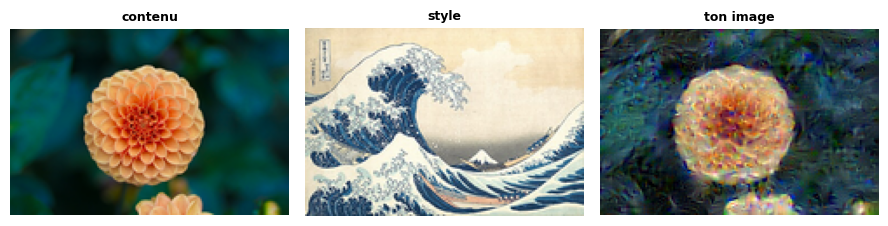

✅ Ex 28.29 : défi réussi : moins de 2 minutes, style divisé par 10 ou plus, contenu reconnaissable.


In [65]:
def make_29(content, style):
    """Your style transfer for the challenge: (3, H, W) arrays in [0, 1] -> an image (3, H, W) in [0, 1]."""
    # a small style weight (the style only has to be divided by 10), small steps, more of them: the content stays close
    img, _ = style_transfer_23(NET, content, style, ["fire6"], STYLE_LAYERS, 1.0, 0.05, 0.05, steps=300, lr=0.02)
    return img


with checked("28.29"):
    need("28.29", "make_29", "measure_24")
    passed_29 = evaluate_29(make_29)
    verdict("28.29", passed_29, "défi réussi : moins de 2 minutes, style divisé par 10 ou plus, contenu reconnaissable.",
            "pas encore : regarde le critère qui manque ci-dessus.")

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu écrire une montée de gradient sur l'image d'un réseau gelé, normalisation et plage des pixels comprises ?
2. Sais-tu calculer une matrice de Gram et dire ce qu'elle garde et ce qu'elle oublie ?
3. Sais-tu régler les trois poids d'un transfert de style en lisant la valeur de chaque terme, et choisir une stratégie de décodage de texte ?

**Pour aller plus loin** : l'article de Gatys et coll. (2015) et l'article « Feature Visualization » de Distill (2017), cités dans la fiche. La suite : le ch. 29, les datasets et la préparation du projet final.